# MAPEAMENTO E PRIORIZAÇÃO DE HOTSPOTS DE SINISTROS FERROVIÁRIOS VIA DBSCAN: APLICAÇÃO NA RUMO MALHA SUL

### Autores

**Aluisio Guilherme Regazzo**  
**Guilherme Benitez Frehse**  
**Lucas Gabriel Souza da Silva**  
**Suzane dos Santos**

---

**Notebook de reprodutibilidade do artigo**

Este notebook reúne as etapas de aquisição e preparação dos dados, análise exploratória, modelagem por DBSCAN, análises de sensibilidade e geração das figuras e tabelas utilizadas no artigo.


## Rastreabilidade entre o notebook e o artigo

Este notebook documenta **todo o caminho analítico utilizado no desenvolvimento do estudo**, e não apenas as figuras que permaneceram na versão final do artigo.

As etapas estão divididas em três blocos:

1. **Aquisição, auditoria e preparação dos dados** — corresponde principalmente às Seções 2 e 2.1 do artigo.
2. **Análise exploratória e decisões de preparação** — reúne as verificações e explorações realizadas antes da modelagem. Parte dessas análises é complementar e foi mantida para transparência e reprodutibilidade. A comparação entre a RMS e as demais concessões foi incorporada ao artigo como **Seção 3.1 / Figura 1**.
3. **Modelagem, sensibilidade e priorização** — corresponde às Seções 2.2–2.6 e aos resultados apresentados nas Seções 3.2–3.7 do artigo.

Assim, o repositório permite acompanhar desde a obtenção da base oficial da ANTT até a geração das Figuras 1–6 e da Tabela 1, preservando também as análises intermediárias que ajudaram a definir o fluxo metodológico.


## 1. Ambiente computacional

Importação das bibliotecas e registro das versões efetivamente utilizadas na execução.

In [1]:
# ============================================================
# 1) AMBIENTE COMPUTACIONAL
# ============================================================

import os
import re
import sys
import math
import unicodedata
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import sklearn
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

import scipy
from scipy.stats import spearmanr
from scipy.interpolate import make_interp_spline, interp1d

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams["font.sans-serif"] = [
    "DejaVu Sans",
    "Liberation Sans",
    "Arial",
    "sans-serif",
]
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.edgecolor"] = "black"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["figure.facecolor"] = "white"

print("✓ Ambiente carregado.")
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)

✓ Ambiente carregado.
Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1
SciPy: 1.16.3
Matplotlib: 3.10.0


## 2. Aquisição dos dados diretamente do Portal de Dados Abertos da ANTT

**Correspondência com o artigo:** Seção **2. Materiais e Métodos**.

Esta versão do notebook **não utiliza upload manual nem arquivo local como fonte de entrada**.

Os registros são obtidos diretamente do **DataStore/API oficial do Portal de Dados Abertos da ANTT**, usando o identificador do recurso empregado no artigo:

`b3851bf8-9c4c-4452-93f6-ddaba3992e60`

A API é consultada em páginas até que todos os registros disponíveis no recurso tenham sido recuperados. Caso o portal da ANTT rejeite a requisição naquele momento, o notebook interrompe a execução com uma mensagem explícita em vez de interpretar uma página HTML como CSV.


In [2]:
# ============================================================
# 2) AQUISIÇÃO DIRETA VIA API OFICIAL DA ANTT
# ============================================================

import requests
from urllib.parse import urlencode

RESOURCE_ID = "b3851bf8-9c4c-4452-93f6-ddaba3992e60"

# Endpoints oficiais do Portal de Dados Abertos da ANTT.
# A primeira opção corresponde ao padrão CKAN.
# As demais permanecem no mesmo domínio oficial e são tentadas
# caso o portal esteja aplicando reescrita/localização de rota.
ENDPOINTS_ANTT = [
    "https://dados.antt.gov.br/api/3/action/datastore_search",
    "https://dados.antt.gov.br/pt_BR/api/3/action/datastore_search",
    "https://dados.antt.gov.br/pt_BR/packages",
    "https://dados.antt.gov.br/packages",
]

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/124.0 Safari/537.36"
    ),
    "Accept": "application/json,text/plain,*/*",
    "Accept-Language": "pt-BR,pt;q=0.9,en;q=0.8",
    "Cache-Control": "no-cache",
}

def _resposta_e_json_validos(resp):
    """Valida se a resposta é JSON da API CKAN e não página HTML."""
    content_type = resp.headers.get("Content-Type", "").lower()
    texto_inicial = resp.text[:500].lower()

    if resp.status_code != 200:
        return False, None

    if (
        "text/html" in content_type
        or "<html" in texto_inicial
        or "request rejected" in texto_inicial
        or "access denied" in texto_inicial
    ):
        return False, None

    try:
        payload = resp.json()
    except Exception:
        return False, None

    if not isinstance(payload, dict):
        return False, None

    if payload.get("success") is not True:
        return False, None

    result = payload.get("result", {})

    if "records" not in result:
        return False, None

    return True, payload


def _consultar_endpoint(endpoint, offset=0, limit=1000):
    """
    Faz uma consulta ao recurso oficial.
    Trata tanto a rota CKAN padrão quanto a rota /packages
    documentada pelo próprio Portal da ANTT em páginas localizadas.
    """
    if endpoint.endswith("/packages"):
        params = {
            "ver": "/3",
            "logic_function": "datastore_search",
            "resource_id": RESOURCE_ID,
            "limit": limit,
            "offset": offset,
        }
    else:
        params = {
            "resource_id": RESOURCE_ID,
            "limit": limit,
            "offset": offset,
        }

    resp = requests.get(
        endpoint,
        params=params,
        headers=HEADERS,
        timeout=60,
    )

    valido, payload = _resposta_e_json_validos(resp)

    return valido, payload, resp


def descobrir_endpoint_funcional():
    """Testa somente endpoints do domínio oficial da ANTT."""
    detalhes = []

    for endpoint in ENDPOINTS_ANTT:
        try:
            valido, payload, resp = _consultar_endpoint(
                endpoint,
                offset=0,
                limit=5,
            )

            if valido:
                print("✓ Endpoint oficial funcional:")
                print(" ", resp.url)
                return endpoint, payload

            detalhes.append(
                f"{endpoint} -> HTTP {resp.status_code}; "
                f"Content-Type={resp.headers.get('Content-Type')!r}"
            )

        except Exception as exc:
            detalhes.append(
                f"{endpoint} -> {type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Não foi possível acessar o recurso pela API oficial da ANTT.\n\n"
        "O notebook está configurado para usar SOMENTE o site da ANTT; "
        "por isso não fará upload manual nem usará cópias locais.\n\n"
        "Tentativas realizadas:\n- "
        + "\n- ".join(detalhes)
    )


def baixar_todos_registros_antt(
    endpoint,
    primeiro_payload=None,
    page_size=1000,
):
    """
    Recupera todo o recurso do DataStore oficial da ANTT,
    paginando até alcançar o total informado pela API.
    """
    registros = []
    offset = 0
    total = None

    while True:
        if offset == 0 and primeiro_payload is not None:
            payload = primeiro_payload

            # O teste inicial usa limit=5; precisamos consultar
            # novamente com page_size para iniciar a paginação real.
            valido, payload, resp = _consultar_endpoint(
                endpoint,
                offset=0,
                limit=page_size,
            )
            if not valido:
                raise RuntimeError(
                    "O endpoint oficial respondeu ao teste inicial, "
                    "mas falhou ao iniciar a paginação."
                )
        else:
            valido, payload, resp = _consultar_endpoint(
                endpoint,
                offset=offset,
                limit=page_size,
            )

            if not valido:
                raise RuntimeError(
                    f"Falha na API oficial da ANTT a partir do offset {offset}."
                )

        result = payload["result"]
        lote = result.get("records", [])

        if total is None:
            total = int(result.get("total", len(lote)))
            print(f"Total informado pela API: {total:,}".replace(",", "."))

        if not lote:
            break

        registros.extend(lote)
        offset = len(registros)

        print(
            f"Registros recuperados: "
            f"{len(registros):,}/{total:,}".replace(",", ".")
        )

        if len(registros) >= total:
            break

    # Evita eventual repetição causada por respostas anômalas da API.
    registros = registros[:total]

    return registros, total


endpoint_antt, primeiro_payload = descobrir_endpoint_funcional()

registros_antt, total_api = baixar_todos_registros_antt(
    endpoint_antt,
    primeiro_payload=primeiro_payload,
    page_size=1000,
)

df_raw = pd.DataFrame(registros_antt)

# O DataStore CKAN adiciona normalmente uma coluna técnica "_id".
# Ela não participa das análises do artigo.
if "_id" in df_raw.columns:
    df_raw = df_raw.drop(columns=["_id"])

print("\n✓ Dados obtidos diretamente do Portal de Dados Abertos da ANTT.")
print(
    f"Registros carregados: "
    f"{len(df_raw):,}".replace(",", ".")
)
print("Número de colunas:", df_raw.shape[1])

display(df_raw.head())


✓ Endpoint oficial funcional:
  https://dados.antt.gov.br/api/3/action/datastore_search?resource_id=b3851bf8-9c4c-4452-93f6-ddaba3992e60&limit=5&offset=0
Total informado pela API: 3.710
Registros recuperados: 1.000/3.710
Registros recuperados: 2.000/3.710
Registros recuperados: 3.000/3.710
Registros recuperados: 3.710/3.710

✓ Dados obtidos diretamente do Portal de Dados Abertos da ANTT.
Registros carregados: 3.710
Número de colunas: 27


,Gravidade,Concessionaria,Data_Ocorrencia,Hora_Ocorrencia,UF,Municipio,Linha,Quilômetro_Inicial,Quilômetro_Final,Estação_Anterior,...,Prefixo,Double_Stack,Serviço_Transporte,N_feridos,N_obitos,Mercadoria,Equipagem,Outra_Ferrovia,PN,Prejuízo_Financeiro
0,Sim,FTL,2020-12-01T00:00:00,16:00,PE,Jaboatao dos Guararapes,Tronco Sul Recife,5.000,5.001,Jorge Lins,...,,,,0,0,,,,Não,91800.0
1,Não,FCA,2020-12-03T00:00:00,11:04,MG,Santo Antonio do Monte,Garças de Minas - Calafate,675.450,NaN,St. Amaro do Monte,...,C305,Não,Cargas,0,0,Cloreto de Potássio,Rogerio Dias da Silva,,Sim,NaN
2,Não,MRS,2020-12-04T00:00:00,06:35,MG,Ibirite,Variante do Paraopeba,614.996,NaN,Ibirite,...,KPE1101,Não,Cargas,0,0,Container Carregado de 20,MARCELINO BASILIO,,Sim,0.0
3,Sim,FTL,2020-12-04T00:00:00,20:30,MA,Sao Luis,Ramal de Itaqui,30.000,NaN,Pátio Esso,...,W002,Não,Cargas,0,0,Óleos Diesel em VagõesTanque VagõesVazios de ...,MARCIO ADRIANO SANTOS NUNES,,Não,0.0
4,Sim,FTL,2020-12-05T00:00:00,16:35,CE,Crateus,Tronco Norte Fortaleza,475.000,NaN,Crateus,...,K107,Não,Cargas,0,0,Bobinas de Aço ou Ferro Cimento Acondicionado...,ANTONIO EGENNALES ALVES DE MIRANDA JONAEL DE ...,,Sim,0.0


## 3. Validação estrutural dos dados recebidos da API

Como a base já foi recebida diretamente em formato JSON pelo DataStore da ANTT, não é necessário realizar `read_csv`.

Esta etapa apenas confirma que a estrutura devolvida pela API contém as principais variáveis esperadas antes da padronização dos cabeçalhos.


In [3]:
# ============================================================
# 3) VALIDAÇÃO ESTRUTURAL DA RESPOSTA DA API
# ============================================================

def normalizar_chave_simples(texto):
    texto = str(texto)
    texto = (
        texto
        .replace("\ufeff", "")
        .replace("\xa0", " ")
        .strip()
    )

    texto = unicodedata.normalize("NFD", texto)

    texto = "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    )

    texto = texto.casefold()

    return re.sub(
        r"[^a-z0-9]+",
        "",
        texto
    )


chaves_recebidas = {
    normalizar_chave_simples(c)
    for c in df_raw.columns
}

grupos_essenciais = {
    "data": {
        "dataocorrencia",
        "datadaocorrencia",
        "datadeocorrencia",
    },
    "concessionaria": {
        "concessionaria",
    },
    "linha": {
        "linha",
        "linhaferroviaria",
    },
    "municipio": {
        "municipio",
    },
    "km": {
        "quilometroinicial",
        "kminicial",
    },
}

faltantes_estruturais = []

for nome_grupo, alternativas in grupos_essenciais.items():
    if not any(
        alternativa in chaves_recebidas
        for alternativa in alternativas
    ):
        faltantes_estruturais.append(nome_grupo)

if faltantes_estruturais:
    raise RuntimeError(
        "A API oficial respondeu, mas a estrutura recebida "
        "não contém os grupos de colunas esperados: "
        + ", ".join(faltantes_estruturais)
        + "\n\nColunas recebidas:\n- "
        + "\n- ".join(map(str, df_raw.columns))
    )

print("✓ Estrutura recebida da API compatível com a base esperada.")
print("\nCabeçalhos recebidos:")

for c in df_raw.columns:
    print(" -", c)


✓ Estrutura recebida da API compatível com a base esperada.

Cabeçalhos recebidos:
 - Gravidade
 - Concessionaria
 - Data_Ocorrencia
 - Hora_Ocorrencia
 - UF
 - Municipio
 - Linha
 - Quilômetro_Inicial
 - Quilômetro_Final
 - Estação_Anterior
 - Estação_Posterior
 - Perímetro_Urbano
 - Causa_direta
 - Causa_contibutiva
 - Natureza
 - Interrupção
 - N_Trem
 - Prefixo
 - Double_Stack
 - Serviço_Transporte
 - N_feridos
 - N_obitos
 - Mercadoria
 - Equipagem
 - Outra_Ferrovia
 - PN
 - Prejuízo_Financeiro


## 4. Padronização robusta dos cabeçalhos

**Correspondência com o artigo:** Seção **2.1 Preparação, limpeza e padronização dos dados**.

Depois da aquisição direta via API oficial da ANTT, os nomes das variáveis são harmonizados para o padrão utilizado no restante do notebook. São tratadas diferenças de acentuação, espaços, BOM e nomes equivalentes.


In [4]:
# ============================================================
# 4) PADRONIZAÇÃO ROBUSTA DOS CABEÇALHOS
# ============================================================

def corrigir_mojibake(texto):
    if pd.isna(texto):
        return texto

    texto = str(texto)

    if any(marcador in texto for marcador in ["Ã", "Â", "�"]):
        try:
            return texto.encode("latin1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass

    return texto


def chave_coluna(texto):
    texto = corrigir_mojibake(texto)
    texto = (
        str(texto)
        .replace("\ufeff", "")
        .replace("\xa0", " ")
        .strip()
    )
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(
        c for c in texto
        if unicodedata.category(c) != "Mn"
    )
    texto = texto.casefold()
    return re.sub(r"[^a-z0-9]+", "", texto)


df_raw.columns = [
    corrigir_mojibake(
        str(c)
        .replace("\ufeff", "")
        .replace("\xa0", " ")
        .strip()
    )
    for c in df_raw.columns
]

aliases = {
    "Data_Ocorrencia": [
        "Data_Ocorrencia", "Data Ocorrencia",
        "Data da Ocorrencia", "Data de Ocorrencia",
        "Data_Ocorrência", "Data da Ocorrência"
    ],
    "Hora_Ocorrencia": [
        "Hora_Ocorrencia", "Hora Ocorrencia",
        "Hora da Ocorrencia", "Hora_Ocorrência",
        "Hora da Ocorrência"
    ],
    "Concessionaria": [
        "Concessionaria", "Concessionária"
    ],
    "Linha": [
        "Linha", "Linha Ferroviaria", "Linha Ferroviária"
    ],
    "Quilômetro_Inicial": [
        "Quilômetro_Inicial", "Quilometro_Inicial",
        "Quilometro Inicial", "Quilômetro Inicial",
        "KM Inicial", "Km Inicial", "Km_Inicial"
    ],
    "Quilômetro_Final": [
        "Quilômetro_Final", "Quilometro_Final",
        "Quilometro Final", "Quilômetro Final",
        "KM Final", "Km Final"
    ],
    "Municipio": [
        "Municipio", "Município"
    ],
    "UF": [
        "UF", "Estado"
    ],
    "Perímetro_Urbano": [
        "Perímetro_Urbano", "Perimetro_Urbano",
        "Perímetro Urbano", "Perimetro Urbano"
    ],
    "Natureza": [
        "Natureza", "Natureza do Acidente", "Natureza do Sinistro"
    ],
    "Serviço_Transporte": [
        "Serviço_Transporte", "Servico_Transporte",
        "Serviço Transporte", "Servico Transporte"
    ],
    "Prejuízo_Financeiro": [
        "Prejuízo_Financeiro", "Prejuizo_Financeiro",
        "Prejuízo Financeiro", "Prejuizo Financeiro"
    ],
    "Causa_contibutiva": [
        "Causa_contibutiva", "Causa_contributiva",
        "Causa Contibutiva", "Causa Contributiva"
    ],
    "Causa_direta": [
        "Causa_direta", "Causa Direta", "Causa direta"
    ],
    "PN": [
        "PN", "Passagem_Nivel", "Passagem Nivel",
        "Passagem em Nivel", "Passagem em Nível"
    ],
    "N_feridos": [
        "N_feridos", "N feridos", "Nº feridos",
        "Numero de feridos", "Número de feridos", "Feridos"
    ],
    "N_obitos": [
        "N_obitos", "N óbitos", "N obitos", "Nº óbitos",
        "Numero de obitos", "Número de óbitos", "Obitos", "Óbitos"
    ],
    "Mercadoria": ["Mercadoria"],
    "Estação_Anterior": [
        "Estação_Anterior", "Estacao_Anterior",
        "Estação Anterior", "Estacao Anterior"
    ],
    "Estação_Posterior": [
        "Estação_Posterior", "Estacao_Posterior",
        "Estação Posterior", "Estacao Posterior"
    ],
    "Outra_Ferrovia": [
        "Outra_Ferrovia", "Outra Ferrovia"
    ],
}

presentes = {}
for c in df_raw.columns:
    presentes.setdefault(chave_coluna(c), c)

renomear = {}

for canonico, opcoes in aliases.items():
    for opcao in [canonico] + opcoes:
        chave = chave_coluna(opcao)
        if chave in presentes:
            original = presentes[chave]
            if original != canonico:
                renomear[original] = canonico
            break

df_raw = df_raw.rename(columns=renomear)

if "Data_Ocorrencia" not in df_raw.columns:
    candidatas = [
        c for c in df_raw.columns
        if "data" in chave_coluna(c)
        and (
            "ocorr" in chave_coluna(c)
            or "acident" in chave_coluna(c)
        )
    ]
    if len(candidatas) == 1:
        df_raw = df_raw.rename(
            columns={candidatas[0]: "Data_Ocorrencia"}
        )

campos_obrigatorios = [
    "Data_Ocorrencia",
    "Concessionaria",
    "Linha",
    "Quilômetro_Inicial",
    "Municipio",
    "Perímetro_Urbano",
    "Natureza",
    "Causa_direta",
    "PN",
    "N_feridos",
    "N_obitos",
]

faltantes = [
    c for c in campos_obrigatorios
    if c not in df_raw.columns
]

print("\nCabeçalhos após padronização:")
print(df_raw.columns.tolist())

if faltantes:
    raise KeyError(
        "Colunas obrigatórias não localizadas: "
        + ", ".join(faltantes)
        + "\n\nColunas encontradas no arquivo:\n"
        + "\n".join(
            f"- {c!r} -> chave={chave_coluna(c)!r}"
            for c in df_raw.columns
        )
    )

print("\n✓ Cabeçalhos padronizados.")
print("✓ Todos os campos obrigatórios foram localizados.")


Cabeçalhos após padronização:
['Gravidade', 'Concessionaria', 'Data_Ocorrencia', 'Hora_Ocorrencia', 'UF', 'Municipio', 'Linha', 'Quilômetro_Inicial', 'Quilômetro_Final', 'Estação_Anterior', 'Estação_Posterior', 'Perímetro_Urbano', 'Causa_direta', 'Causa_contibutiva', 'Natureza', 'Interrupção', 'N_Trem', 'Prefixo', 'Double_Stack', 'Serviço_Transporte', 'N_feridos', 'N_obitos', 'Mercadoria', 'Equipagem', 'Outra_Ferrovia', 'PN', 'Prejuízo_Financeiro']

✓ Cabeçalhos padronizados.
✓ Todos os campos obrigatórios foram localizados.


## 5. Diagnóstico da base bruta

**Correspondência com o artigo:** caracterização inicial da fonte e definição do recorte temporal.

A API oficial da ANTT devolve `Data_Ocorrencia` em **formato ISO (`AAAA-MM-DDTHH:MM:SS`)**. Por isso, as datas são convertidas explicitamente nesse formato, sem `dayfirst=True`.

Essa distinção é importante: interpretar `2020-12-01T00:00:00` como uma data no padrão dia/mês pode transformar **1º de dezembro de 2020 em 12 de janeiro de 2020** e invalidar diversas outras datas.

A etapa também exibe a distribuição anual e verifica separadamente os meses encontrados em 2020 e 2026.


In [5]:
# ============================================================
# 5) DIAGNÓSTICO DA BASE BRUTA
# ============================================================

df_todos_dados = df_raw.copy()


def converter_data_antt(serie):
    """
    Converte a Data_Ocorrencia retornada pela API oficial da ANTT.

    A API fornece datas em formato ISO, por exemplo:
        2020-12-01T00:00:00

    Portanto NÃO se deve usar dayfirst=True, pois isso pode inverter
    mês/dia e transformar 01/12 em 12/01, além de gerar NaT em datas
    cujo dia é maior que 12.
    """
    serie = serie.astype("string").str.strip()

    # Formato oficial observado na API.
    convertido = pd.to_datetime(
        serie,
        format="%Y-%m-%dT%H:%M:%S",
        errors="coerce",
    )

    # Fallback conservador para eventual variação ISO futura.
    faltantes = convertido.isna() & serie.notna()

    if faltantes.any():
        convertido.loc[faltantes] = pd.to_datetime(
            serie.loc[faltantes],
            errors="coerce",
        )

    return convertido


df_todos_dados["Data_Ocorrencia_dt"] = converter_data_antt(
    df_todos_dados["Data_Ocorrencia"]
)

df_todos_dados["Ano"] = (
    df_todos_dados["Data_Ocorrencia_dt"].dt.year
)

df_todos_dados["Mes"] = (
    df_todos_dados["Data_Ocorrencia_dt"].dt.month
)

datas_validas = (
    df_todos_dados["Data_Ocorrencia_dt"]
    .dropna()
)

n_datas_invalidas_bruto = int(
    df_todos_dados["Data_Ocorrencia_dt"]
    .isna()
    .sum()
)

print(
    f"Total bruto: "
    f"{len(df_todos_dados):,}".replace(",", ".")
)

print(
    "Datas inválidas/ausentes:",
    n_datas_invalidas_bruto
)

if not datas_validas.empty:
    print("Primeira ocorrência:", datas_validas.min())
    print("Última ocorrência:", datas_validas.max())

print("\nOcorrências por ano:")
contagem_ano_total = (
    df_todos_dados["Ano"]
    .value_counts(dropna=True)
    .sort_index()
)

display(
    contagem_ano_total
    .rename("Ocorrências")
    .to_frame()
)

print("\nMeses presentes em 2020:")
meses_2020 = (
    df_todos_dados.loc[
        df_todos_dados["Ano"].eq(2020),
        "Mes"
    ]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

display(
    meses_2020
    .rename("Ocorrências")
    .to_frame()
)

print("\nMeses presentes em 2026:")
meses_2026 = (
    df_todos_dados.loc[
        df_todos_dados["Ano"].eq(2026),
        "Mes"
    ]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

display(
    meses_2026
    .rename("Ocorrências")
    .to_frame()
)

# ------------------------------------------------------------
# Validações essenciais
# ------------------------------------------------------------
if n_datas_invalidas_bruto != 0:
    raise ValueError(
        f"Foram encontradas {n_datas_invalidas_bruto} datas inválidas "
        "após a conversão ISO. A execução foi interrompida para evitar "
        "alteração indevida do recorte temporal."
    )

if len(df_todos_dados) == 3710:
    print("✓ Total bruto compatível com o artigo: 3.710.")
else:
    print(
        "⚠ O artigo foi elaborado com 3.710 registros brutos; "
        f"a base atual contém {len(df_todos_dados)}."
    )

# O recurso oficial é identificado pela ANTT como dezembro/2020
# a janeiro/2026. A checagem abaixo evita inversão mês/dia.
meses_2020_encontrados = set(meses_2020.index.tolist())
meses_2026_encontrados = set(meses_2026.index.tolist())

if meses_2020_encontrados == {12}:
    print("✓ 2020 contém somente registros de dezembro.")
else:
    print(
        "⚠ Atenção: foram encontrados outros meses em 2020:",
        sorted(meses_2020_encontrados)
    )

if meses_2026_encontrados == {1}:
    print("✓ 2026 contém somente registros de janeiro.")
else:
    print(
        "⚠ Atenção: foram encontrados outros meses em 2026:",
        sorted(meses_2026_encontrados)
    )


Total bruto: 3.710
Datas inválidas/ausentes: 0
Primeira ocorrência: 2020-12-01 00:00:00
Última ocorrência: 2026-01-31 00:00:00

Ocorrências por ano:


,Ocorrências
Ano,
2020,57
2021,746
2022,782
2023,728
2024,666
2025,687
2026,44



Meses presentes em 2020:


,Ocorrências
Mes,
12,57



Meses presentes em 2026:


,Ocorrências
Mes,
1,44


✓ Total bruto compatível com o artigo: 3.710.
✓ 2020 contém somente registros de dezembro.
✓ 2026 contém somente registros de janeiro.


## 5.1 Diagnóstico exploratório das variáveis da base bruta

**Etapa complementar de auditoria.**

Antes do recorte e da modelagem, é útil examinar a estrutura das variáveis recebidas diretamente da ANTT. Esta etapa registra:

- tipo de dado;
- quantidade e percentual de valores ausentes;
- quantidade de valores distintos;
- exemplos de valores observados.

Esse diagnóstico foi utilizado durante o desenvolvimento do estudo para identificar problemas de preenchimento, variáveis com elevada ausência de dados e campos que exigiam padronização específica.

> Esta tabela é uma saída exploratória do notebook e **não corresponde à Tabela 1 do artigo**.


In [6]:
# ============================================================
# 5.1) DIAGNÓSTICO EXPLORATÓRIO DAS VARIÁVEIS
# ============================================================

def exemplos_coluna(serie, n=3):
    valores = (
        serie
        .dropna()
        .astype(str)
        .drop_duplicates()
        .head(n)
        .tolist()
    )
    return " | ".join(valores)

relatorio_colunas = pd.DataFrame({
    "Variável": df_todos_dados.columns,
    "Tipo": [str(df_todos_dados[c].dtype) for c in df_todos_dados.columns],
    "Nulos": [int(df_todos_dados[c].isna().sum()) for c in df_todos_dados.columns],
    "Nulos (%)": [
        round(100 * df_todos_dados[c].isna().mean(), 2)
        for c in df_todos_dados.columns
    ],
    "Valores únicos": [
        int(df_todos_dados[c].nunique(dropna=True))
        for c in df_todos_dados.columns
    ],
    "Exemplos": [
        exemplos_coluna(df_todos_dados[c])
        for c in df_todos_dados.columns
    ],
})

display(relatorio_colunas)

print(
    "✓ Diagnóstico estrutural concluído para "
    f"{len(relatorio_colunas)} variáveis."
)


,Variável,Tipo,Nulos,Nulos (%),Valores únicos,Exemplos
0,Gravidade,object,0,0.00,2,Sim | Não
1,Concessionaria,object,0,0.00,13,FTL | FCA | MRS
2,Data_Ocorrencia,object,0,0.00,1590,2020-12-01T00:00:00 | 2020-12-03T00:00:00 | 20...
3,Hora_Ocorrencia,object,0,0.00,1281,16:00 | 11:04 | 06:35
4,UF,object,0,0.00,22,PE | MG | MA
5,Municipio,object,0,0.00,528,Jaboatao dos Guararapes | Santo Antonio do Mon...
6,Linha,object,0,0.00,119,Tronco Sul Recife | Garças de Minas - Calafate...
7,Quilômetro_Inicial,float64,0,0.00,3032,5.0 | 675.45 | 614.996
8,Quilômetro_Final,float64,46,1.24,3136,5.001 | 0.0 | 198.201
9,Estação_Anterior,object,0,0.00,884,Jorge Lins | St. Amaro do Monte | Ibirite


✓ Diagnóstico estrutural concluído para 30 variáveis.


### 5.2 Conferência temporal da fonte

Esta conferência mostra a cobertura efetivamente recebida da API antes do filtro.

Ela é mantida para demonstrar que:

- 2020 possui cobertura parcial;
- 2021–2025 são os anos completos utilizados na análise;
- 2026 possui cobertura parcial.

A presença de 2020 e 2026 nesta tabela **não significa que esses anos sejam utilizados na modelagem**.


In [7]:
# ============================================================
# 5.2) CONFERÊNCIA TEMPORAL DA FONTE
# ============================================================

conferencia_temporal = (
    df_todos_dados
    .dropna(subset=["Data_Ocorrencia_dt"])
    .assign(
        Ano=lambda d: d["Data_Ocorrencia_dt"].dt.year,
        Mes=lambda d: d["Data_Ocorrencia_dt"].dt.month,
    )
    .groupby(["Ano", "Mes"])
    .size()
    .rename("Ocorrências")
    .reset_index()
)

display(conferencia_temporal)

print(
    "\nPeríodo efetivamente recebido da API:",
    df_todos_dados["Data_Ocorrencia_dt"].min(),
    "até",
    df_todos_dados["Data_Ocorrencia_dt"].max()
)


,Ano,Mes,Ocorrências
0,2020,12,57
1,2021,1,48
2,2021,2,48
3,2021,3,66
4,2021,4,51
...,...,...,...
57,2025,9,67
58,2025,10,50
59,2025,11,67
60,2025,12,55



Período efetivamente recebido da API: 2020-12-01 00:00:00 até 2026-01-31 00:00:00


## 6. Recorte temporal para a análise: 2021–2025

O recurso oficial utilizado contém registros de **dezembro de 2020 a janeiro de 2026**.

Como 2020 possui apenas dezembro e 2026 possui apenas janeiro, **ambos os anos são excluídos da análise principal** para trabalhar somente com anos completos.

O recorte analítico adotado neste notebook passa a ser:

- início: **01/01/2021**;
- fim: **31/12/2025**.

Assim, todas as análises exploratórias, comparações, aplicações do DBSCAN, análises de sensibilidade, rankings, figuras e tabelas posteriores são recalculadas exclusivamente com registros de **2021 a 2025**.


In [8]:
# ============================================================
# 6) RECORTE TEMPORAL — SOMENTE ANOS COMPLETOS: 2021–2025
# ============================================================

if "Data_Ocorrencia_dt" not in df_todos_dados.columns:
    raise RuntimeError(
        "Data_Ocorrencia_dt não foi criada. "
        "Execute as etapas anteriores antes do recorte temporal."
    )

# IMPORTANTE:
# Nesta etapa criamos df_recorte_bruto.
# A remoção de duplicatas fica para a seção 7.
df_recorte_bruto = (
    df_todos_dados[
        df_todos_dados["Data_Ocorrencia_dt"].between(
            "2021-01-01",
            "2025-12-31",
            inclusive="both"
        )
    ]
    .copy()
)

print(
    "Total bruto recebido da ANTT:",
    f"{len(df_todos_dados):,}".replace(",", ".")
)

print(
    "Registros de 2020 excluídos:",
    int(df_todos_dados["Ano"].eq(2020).sum())
)

print(
    "Registros de 2026 excluídos:",
    int(df_todos_dados["Ano"].eq(2026).sum())
)

print(
    "Total no recorte 2021–2025:",
    f"{len(df_recorte_bruto):,}".replace(",", ".")
)

print(
    "Primeira data do recorte:",
    df_recorte_bruto["Data_Ocorrencia_dt"].min()
)

print(
    "Última data do recorte:",
    df_recorte_bruto["Data_Ocorrencia_dt"].max()
)

anos_presentes = sorted(
    df_recorte_bruto["Data_Ocorrencia_dt"]
    .dt.year
    .dropna()
    .unique()
    .tolist()
)

print(
    "Anos presentes no recorte:",
    anos_presentes
)

if anos_presentes != [2021, 2022, 2023, 2024, 2025]:
    raise ValueError(
        "O recorte temporal não contém exatamente os anos "
        "2021, 2022, 2023, 2024 e 2025."
    )

print(
    "✓ Recorte temporal validado: "
    "somente anos completos de 2021 a 2025."
)


Total bruto recebido da ANTT: 3.710
Registros de 2020 excluídos: 57
Registros de 2026 excluídos: 44
Total no recorte 2021–2025: 3.609
Primeira data do recorte: 2021-01-01 00:00:00
Última data do recorte: 2025-12-31 00:00:00
Anos presentes no recorte: [2021, 2022, 2023, 2024, 2025]
✓ Recorte temporal validado: somente anos completos de 2021 a 2025.


## 7. Duplicatas e integridade espacial

**Correspondência com o artigo:** Seções **2 e 2.1** — duplicatas e integridade das variáveis usadas na análise espacial.

Verificação de duplicatas integrais, datas inválidas, coordenadas geográficas (quando existentes) e disponibilidade de `Linha + Quilômetro_Inicial`.

In [9]:
# ============================================================
# 7) DUPLICATAS E INTEGRIDADE
# ============================================================

if "df_recorte_bruto" not in globals():
    raise RuntimeError(
        "df_recorte_bruto não existe. "
        "Execute primeiro a seção 6 — Recorte temporal 2021–2025."
    )

n_duplicatas_exatas = int(
    df_recorte_bruto.duplicated().sum()
)

n_datas_invalidas = int(
    df_recorte_bruto["Data_Ocorrencia_dt"]
    .isna()
    .sum()
)

df_limpo = (
    df_recorte_bruto
    .drop_duplicates()
    .copy()
)

def converter_numero_br(valor):
    if pd.isna(valor):
        return np.nan

    if isinstance(valor, (int, float, np.integer, np.floating)):
        return float(valor)

    s = str(valor).strip()

    if s == "" or s.casefold() in {"nan", "none"}:
        return np.nan

    # Casos com vírgula decimal.
    if "," in s:
        s = s.replace(".", "")
        s = s.replace(",", ".")

    return pd.to_numeric(s, errors="coerce")


km_temp = (
    df_limpo["Quilômetro_Inicial"]
    .apply(converter_numero_br)
)

n_referencia_linear = int(
    (
        df_limpo["Linha"].notna()
        & km_temp.notna()
    ).sum()
)

mapa_cols = {
    chave_coluna(c): c
    for c in df_limpo.columns
}

col_lat = next(
    (
        mapa_cols[k]
        for k in ["latitude", "lat"]
        if k in mapa_cols
    ),
    None
)

col_lon = next(
    (
        mapa_cols[k]
        for k in ["longitude", "lon", "lng", "long"]
        if k in mapa_cols
    ),
    None
)

if col_lat is not None and col_lon is not None:
    n_latlon = int(
        (
            df_limpo[col_lat].notna()
            & df_limpo[col_lon].notna()
        ).sum()
    )
else:
    n_latlon = 0

diagnostico = pd.DataFrame({
    "Indicador": [
        "Registros no recorte 2021–2025",
        "Duplicatas exatas",
        "Datas ausentes/inválidas",
        "Registros após remoção de duplicatas",
        "Registros com latitude + longitude",
        "Registros com Linha + Quilômetro_Inicial",
    ],
    "Resultado": [
        len(df_recorte_bruto),
        n_duplicatas_exatas,
        n_datas_invalidas,
        len(df_limpo),
        n_latlon,
        n_referencia_linear,
    ],
})

display(diagnostico)

if n_duplicatas_exatas == 0:
    print("✓ Nenhuma duplicata integral identificada.")
else:
    print(
        f"⚠ Foram removidas {n_duplicatas_exatas} duplicatas integrais."
    )

,Indicador,Resultado
0,Registros no recorte 2021–2025,3609
1,Duplicatas exatas,0
2,Datas ausentes/inválidas,0
3,Registros após remoção de duplicatas,3609
4,Registros com latitude + longitude,0
5,Registros com Linha + Quilômetro_Inicial,3609


✓ Nenhuma duplicata integral identificada.


## 7.1 Perfil de ausências e consistência no recorte 2021–2025

Depois da definição do período analítico, o notebook registra novamente a completude das variáveis no conjunto efetivamente utilizado no estudo.

Essa verificação permite distinguir problemas existentes na base bruta daqueles relevantes para o recorte 2021–2025.


In [10]:
# ============================================================
# 7.1) PERFIL DE AUSÊNCIAS NO RECORTE ANALÍTICO
# ============================================================

perfil_ausencias = pd.DataFrame({
    "Variável": df_limpo.columns,
    "Nulos": [
        int(df_limpo[c].isna().sum())
        for c in df_limpo.columns
    ],
    "Nulos (%)": [
        round(100 * df_limpo[c].isna().mean(), 2)
        for c in df_limpo.columns
    ],
    "Valores únicos": [
        int(df_limpo[c].nunique(dropna=True))
        for c in df_limpo.columns
    ],
}).sort_values(
    ["Nulos (%)", "Nulos"],
    ascending=[False, False]
)

display(perfil_ausencias.reset_index(drop=True))

print(
    "Variáveis com algum valor ausente:",
    int((perfil_ausencias["Nulos"] > 0).sum())
)


,Variável,Nulos,Nulos (%),Valores únicos
0,Gravidade,0,0.0,2
1,Concessionaria,0,0.0,13
2,Data_Ocorrencia,0,0.0,1538
3,Hora_Ocorrencia,0,0.0,1270
4,UF,0,0.0,22
5,Municipio,0,0.0,526
6,Linha,0,0.0,119
7,Quilômetro_Inicial,0,0.0,2962
8,Quilômetro_Final,0,0.0,3102
9,Estação_Anterior,0,0.0,874


Variáveis com algum valor ausente: 0


## 8. Limpeza e padronização das variáveis

**Correspondência com o artigo:** Seção **2.1 Preparação, limpeza e padronização dos dados**.

São tratados quilometragem, número de feridos e óbitos, perímetro urbano, natureza do sinistro, PN e identificador estável da ocorrência.

In [11]:
# ============================================================
# 8) LIMPEZA, NORMALIZAÇÃO E VARIÁVEIS DERIVADAS
# ============================================================

df_final = df_limpo.copy()

# ------------------------------------------------------------
# 8.1 Identificador estável
# ------------------------------------------------------------
df_final["_id_ocorrencia"] = df_final.index.astype(str)

# ------------------------------------------------------------
# 8.2 Variáveis numéricas essenciais
# ------------------------------------------------------------
df_final["Quilômetro_Inicial"] = (
    df_final["Quilômetro_Inicial"]
    .apply(converter_numero_br)
)

for col in ["N_feridos", "N_obitos"]:
    df_final[col] = (
        df_final[col]
        .apply(converter_numero_br)
        .fillna(0)
    )

# ------------------------------------------------------------
# 8.3 Limpeza textual básica
# ------------------------------------------------------------
for col in ["Concessionaria", "Linha", "Municipio"]:
    df_final[col] = (
        df_final[col]
        .astype(str)
        .map(corrigir_mojibake)
        .str.strip()
    )

# ------------------------------------------------------------
# 8.4 Funções de normalização
# ------------------------------------------------------------
def texto_normalizado(valor):
    if pd.isna(valor):
        return ""
    v = corrigir_mojibake(valor)
    v = unicodedata.normalize("NFD", str(v))
    v = "".join(
        c for c in v
        if unicodedata.category(c) != "Mn"
    )
    return v.casefold().strip()


def normalizar_sim_nao(valor):
    v = texto_normalizado(valor)

    if v in {"sim", "s", "1", "true"}:
        return "Sim"
    if v in {"nao", "n", "0", "false"}:
        return "Não"

    return "Não Informado"


def normalizar_perimetro(valor):
    if pd.isna(valor):
        return "Não Informado"

    v = texto_normalizado(valor)

    if v in {
        "nao",
        "rural",
        ".",
        "trecho corrido",
    }:
        return "Não"

    if v in {
        "",
        "nan",
        "none",
    }:
        return "Não Informado"

    return "Sim"


def normalizar_natureza(valor):
    v = texto_normalizado(valor)

    if "abalroamento" in v:
        return "Abalroamento"
    if "atropelamento" in v:
        return "Atropelamento"
    if "descarrilamento" in v:
        return "Descarrilamento"
    if "colis" in v:
        return "Colisão"
    if "incend" in v:
        return "Incêndio"

    return "Outros"


def normalizar_servico(valor):
    if pd.isna(valor):
        return "Não Informado"

    v_original = corrigir_mojibake(valor)
    v = texto_normalizado(valor)

    if v in {"cargas", "cargas cargas"}:
        return "Cargas"
    if "loco escoteira" in v or "locomotiva escoteira" in v:
        return "Locomotiva Escoteira"
    if (
        "auto de linha" in v
        or "maquina de servico" in v
        or v == "interno"
    ):
        return "Manutenção / Serviço Interno"
    if "passageir" in v:
        return "Passageiros"

    if str(v_original).strip() == "":
        return "Não Informado"

    return "Outros / Misto"


def categorizar_periodo_hora(valor):
    if pd.isna(valor):
        return "Não Informado"

    hora = pd.to_datetime(
        str(valor),
        errors="coerce",
        format="%H:%M"
    )

    if pd.isna(hora):
        # Segunda tentativa, aceitando formatos com segundos.
        hora = pd.to_datetime(
            str(valor),
            errors="coerce"
        )

    if pd.isna(hora):
        return "Não Informado"

    h = int(hora.hour)

    if 0 <= h < 6:
        return "Madrugada (00h00 às 05h59)"
    if 6 <= h < 12:
        return "Manhã (06h00 às 11h59)"
    if 12 <= h < 18:
        return "Tarde (12h00 às 17h59)"

    return "Noite (18h00 às 23h59)"


# ------------------------------------------------------------
# 8.5 Variáveis normalizadas
# ------------------------------------------------------------
df_final["Perimetro_Urbano_Norm"] = (
    df_final["Perímetro_Urbano"]
    .apply(normalizar_perimetro)
)

df_final["Natureza_Norm"] = (
    df_final["Natureza"]
    .apply(normalizar_natureza)
)

df_final["PN_Norm"] = (
    df_final["PN"]
    .apply(normalizar_sim_nao)
)

if "Serviço_Transporte" in df_final.columns:
    df_final["Servico_Transporte_Norm"] = (
        df_final["Serviço_Transporte"]
        .apply(normalizar_servico)
    )

if "Hora_Ocorrencia" in df_final.columns:
    df_final["Periodo_Dia_Norm"] = (
        df_final["Hora_Ocorrencia"]
        .apply(categorizar_periodo_hora)
    )

if "Prejuízo_Financeiro" in df_final.columns:
    df_final["Prejuizo_Financeiro_Norm"] = (
        df_final["Prejuízo_Financeiro"]
        .apply(converter_numero_br)
        .fillna(0.0)
    )

# ------------------------------------------------------------
# 8.6 Variáveis temporais derivadas
# ------------------------------------------------------------
df_final["Data_Ocorrencia_dt"] = converter_data_antt(
    df_final["Data_Ocorrencia"]
)

df_final["Ano"] = df_final["Data_Ocorrencia_dt"].dt.year
df_final["Mes"] = df_final["Data_Ocorrencia_dt"].dt.month
df_final["Dia_Semana"] = df_final["Data_Ocorrencia_dt"].dt.day_name()

# ------------------------------------------------------------
# 8.7 Desmembramento das causas contributivas
# ------------------------------------------------------------
def desmembrar_causas(texto):
    if pd.isna(texto):
        return []

    # Divide em vírgulas que não estejam dentro de parênteses.
    partes = re.split(
        r",\s*(?![^()]*\))",
        str(texto)
    )

    return [
        p.strip()
        for p in partes
        if p.strip()
    ]


if "Causa_contibutiva" in df_final.columns:
    listas_causas = (
        df_final["Causa_contibutiva"]
        .apply(desmembrar_causas)
    )

    max_causas = max(
        listas_causas.map(len).max(),
        1
    )

    for i in range(max_causas):
        coluna = f"Causa_explicativa_{i+1}"

        df_final[coluna] = listas_causas.apply(
            lambda lista:
                lista[i]
                if i < len(lista)
                else "Não Informado"
        )

print("✓ Limpeza, normalização e derivação concluídas.")
print("Dimensão de df_final:", df_final.shape)

colunas_derivadas = [
    c for c in [
        "Perimetro_Urbano_Norm",
        "Natureza_Norm",
        "PN_Norm",
        "Servico_Transporte_Norm",
        "Periodo_Dia_Norm",
        "Prejuizo_Financeiro_Norm",
        "Ano",
        "Mes",
        "Dia_Semana",
    ]
    if c in df_final.columns
]

display(
    df_final[
        colunas_derivadas
    ].head(10)
)


✓ Limpeza, normalização e derivação concluídas.
Dimensão de df_final: (3609, 42)


,Perimetro_Urbano_Norm,Natureza_Norm,PN_Norm,Servico_Transporte_Norm,Periodo_Dia_Norm,Prejuizo_Financeiro_Norm,Ano,Mes,Dia_Semana
53,Não,Abalroamento,Sim,Não Informado,Noite (18h00 às 23h59),48400.0,2021,6,Monday
58,Sim,Atropelamento,Não,Cargas,Madrugada (00h00 às 05h59),0.0,2021,1,Friday
59,Sim,Abalroamento,Sim,Cargas,Manhã (06h00 às 11h59),180964.0,2021,1,Friday
60,Sim,Atropelamento,Sim,Cargas,Tarde (12h00 às 17h59),0.0,2021,1,Saturday
61,Sim,Descarrilamento,Não,Cargas,Noite (18h00 às 23h59),0.0,2021,1,Saturday
62,Sim,Colisão,Não,Locomotiva Escoteira,Madrugada (00h00 às 05h59),0.0,2021,1,Monday
63,Não,Abalroamento,Sim,Não Informado,Manhã (06h00 às 11h59),0.0,2021,11,Friday
64,Sim,Descarrilamento,Não,Cargas,Manhã (06h00 às 11h59),4897800.0,2021,1,Wednesday
65,Sim,Atropelamento,Não,Cargas,Noite (18h00 às 23h59),8500.0,2021,1,Thursday
66,Sim,Abalroamento,Sim,Cargas,Noite (18h00 às 23h59),0.0,2021,1,Thursday


## 8.1 Validação das transformações realizadas

Esta etapa preserva as verificações que foram realizadas durante a construção do estudo. O objetivo é confirmar que as categorias normalizadas e as variáveis derivadas foram produzidas conforme esperado.

São apresentadas distribuições das principais variáveis transformadas e, quando disponível, uma amostra do desmembramento da causa contributiva.


In [12]:
# ============================================================
# 8.1) VALIDAÇÃO DAS TRANSFORMAÇÕES
# ============================================================

variaveis_categoricas_validacao = [
    "Perimetro_Urbano_Norm",
    "Natureza_Norm",
    "PN_Norm",
    "Servico_Transporte_Norm",
    "Periodo_Dia_Norm",
]

for col in variaveis_categoricas_validacao:
    if col in df_final.columns:
        print(f"\n>>> {col}")
        display(
            df_final[col]
            .value_counts(dropna=False)
            .rename("Quantidade")
            .to_frame()
        )

if "Prejuizo_Financeiro_Norm" in df_final.columns:
    print("\n>>> Prejuizo_Financeiro_Norm")
    display(
        df_final["Prejuizo_Financeiro_Norm"]
        .describe()
        .rename("Valor")
        .to_frame()
    )

causas_expandidas = [
    c for c in df_final.columns
    if c.startswith("Causa_explicativa_")
]

if causas_expandidas:
    print("\n>>> Exemplo do desmembramento de causas contributivas")
    colunas_exemplo = (
        ["Causa_contibutiva"]
        if "Causa_contibutiva" in df_final.columns
        else []
    ) + causas_expandidas

    filtro_multiplas = (
        df_final[causas_expandidas]
        .apply(
            lambda row:
                sum(v != "Não Informado" for v in row) > 1,
            axis=1
        )
    )

    display(
        df_final.loc[
            filtro_multiplas,
            colunas_exemplo
        ].head(10)
    )



>>> Perimetro_Urbano_Norm


,Quantidade
Perimetro_Urbano_Norm,
Sim,3029
Não,580



>>> Natureza_Norm


,Quantidade
Natureza_Norm,
Abalroamento,1555
Atropelamento,1168
Descarrilamento,822
Colisão,39
Incêndio,25



>>> PN_Norm


...

,Quantidade
Periodo_Dia_Norm,
Tarde (12h00 às 17h59),1099
Manhã (06h00 às 11h59),963
Noite (18h00 às 23h59),942
Madrugada (00h00 às 05h59),605



>>> Prejuizo_Financeiro_Norm


,Valor
count,3.609000e+03
mean,1.749888e+07
std,4.583704e+08
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,4.000000e+04
max,2.692686e+10



>>> Exemplo do desmembramento de causas contributivas


,Causa_contibutiva,Causa_explicativa_1,Causa_explicativa_2,Causa_explicativa_3,Causa_explicativa_4
59,"Desobediência de sinal (por terceiros), Falta ...",Desobediência de sinal (por terceiros),Falta de atenção à circulação (por terceiros),Não Informado,Não Informado
66,"Desobediência de sinal (por terceiros), Falta ...",Desobediência de sinal (por terceiros),Falta de atenção à circulação (por terceiros),Não Informado,Não Informado
69,"Desobediência de sinal (por terceiros), Falta ...",Desobediência de sinal (por terceiros),Falta de atenção à circulação (por terceiros),Não Informado,Não Informado
70,"Falta de atenção à circulação (por terceiros),...",Falta de atenção à circulação (por terceiros),Invasão da faixa de segurança (por terceiros),Não Informado,Não Informado
73,"Desobediência de sinal (por terceiros), Falta ...",Desobediência de sinal (por terceiros),Falta de atenção à circulação (por terceiros),Não Informado,Não Informado
74,"Desobediência de sinal (por terceiros), Falta ...",Desobediência de sinal (por terceiros),Falta de atenção à circulação (por terceiros),Não Informado,Não Informado
75,"Bitola aberta, Dormentação deficiente",Bitola aberta,Dormentação deficiente,Não Informado,Não Informado
82,"Bitola aberta, Dormentação deficiente",Bitola aberta,Dormentação deficiente,Não Informado,Não Informado
84,"Desobediência de sinal (por terceiros), Falta ...",Desobediência de sinal (por terceiros),Falta de atenção à circulação (por terceiros),Não Informado,Não Informado
86,"Bitola aberta, Dormentação deficiente",Bitola aberta,Dormentação deficiente,Não Informado,Não Informado


## 8.2 Seleção e papel das variáveis

Durante a etapa exploratória foram avaliadas variáveis que não precisavam participar diretamente da modelagem espacial. A decisão adotada foi **preservar os campos originais no dataframe para auditoria**, mas utilizar na modelagem somente as variáveis necessárias ao objetivo do estudo.

Principais decisões:

- **`Quilômetro_Inicial` e `Linha`**: referência espacial efetivamente utilizada pelo DBSCAN.
- **`N_feridos` e `N_obitos`**: utilizadas somente após o DBSCAN no Score de Severidade.
- **`Natureza_Norm`, `PN_Norm` e `Perimetro_Urbano_Norm`**: utilizadas na caracterização descritiva dos resultados.
- **`Quilômetro_Final`**: não utilizado na formação dos clusters, pois o estudo adotou o marco inicial da ocorrência.
- **`Estação_Anterior` e `Estação_Posterior`**: mantidas para auditoria, mas não utilizadas como métrica espacial.
- **`Mercadoria`**: não utilizada na modelagem de hotspots.
- **`Outra_Ferrovia`**: não utilizada na modelagem; sua completude é documentada no diagnóstico exploratório.
- **data e hora**: utilizadas para validação temporal e análises exploratórias; o DBSCAN não recebe variáveis temporais.
- **causa contributiva**: desmembrada para exploração, mas não utilizada na formação dos clusters.

Essa separação é importante para que o algoritmo de agrupamento permaneça estritamente espacial, conforme descrito na metodologia do artigo.


## 9. Universo analítico da Rumo Malha Sul

**Correspondência com o artigo:** Seção **2** — seleção das ocorrências da RMS e verificação de `Linha + Quilômetro_Inicial`.

Seleção da RMS e confirmação dos registros aptos ao DBSCAN.

In [13]:
# ============================================================
# 9) UNIVERSO ANALÍTICO RMS
# ============================================================

df_rms = (
    df_final[
        df_final["Concessionaria"]
        .astype(str)
        .str.strip()
        .eq("RMS")
    ]
    .copy()
)

df_rms_ml = (
    df_rms
    .dropna(
        subset=[
            "Linha",
            "Quilômetro_Inicial",
        ]
    )
    .copy()
)

print(
    f"Ocorrências RMS: "
    f"{len(df_rms):,}".replace(",", ".")
)
print(
    f"Ocorrências RMS aptas ao DBSCAN: "
    f"{len(df_rms_ml):,}".replace(",", ".")
)

if len(df_rms) == 1092:
    print("✓ Universo RMS compatível com o artigo: 1.092.")
else:
    print(
        "⚠ O artigo reporta 1.092 ocorrências RMS; "
        f"a execução atual apresentou {len(df_rms)}."
    )

if len(df_rms_ml) == len(df_rms):
    print("✓ 100% dos registros RMS possuem Linha + KM válidos.")
else:
    print(
        "⚠ Registros RMS sem Linha/KM:",
        len(df_rms) - len(df_rms_ml)
    )

Ocorrências RMS: 1.084
Ocorrências RMS aptas ao DBSCAN: 1.084
⚠ O artigo reporta 1.092 ocorrências RMS; a execução atual apresentou 1084.
✓ 100% dos registros RMS possuem Linha + KM válidos.


# ANÁLISE EXPLORATÓRIA

A análise exploratória é mantida no notebook para documentar o comportamento geral da base antes da modelagem. Ela tem duas funções: **verificar coerência dos dados** e **contextualizar os padrões posteriormente analisados pelo DBSCAN**.

Apenas a comparação entre a Rumo Malha Sul e as demais concessões foi incorporada formalmente ao corpo do artigo, na **Seção 3.1 e Figura 1**. As demais saídas desta seção são complementares e ficam registradas no notebook/repositório para fins de transparência e reprodutibilidade.

## 10. Análise exploratória nacional — complementar

**Status no artigo:** análise complementar. A versão final do artigo utiliza formalmente a comparação RMS × demais concessões na Seção 3.1, mas as explorações abaixo foram mantidas no notebook porque fizeram parte do caminho analítico que antecedeu a modelagem.

São examinados:

- evolução anual das ocorrências;
- sazonalidade mensal acumulada;
- distribuição por natureza;
- concessionárias com maior número de registros;
- unidades federativas com maior número de ocorrências.

Essas saídas ajudam a compreender a estrutura do conjunto de dados e a verificar se o recorte analítico apresenta comportamentos coerentes antes da aplicação do DBSCAN.


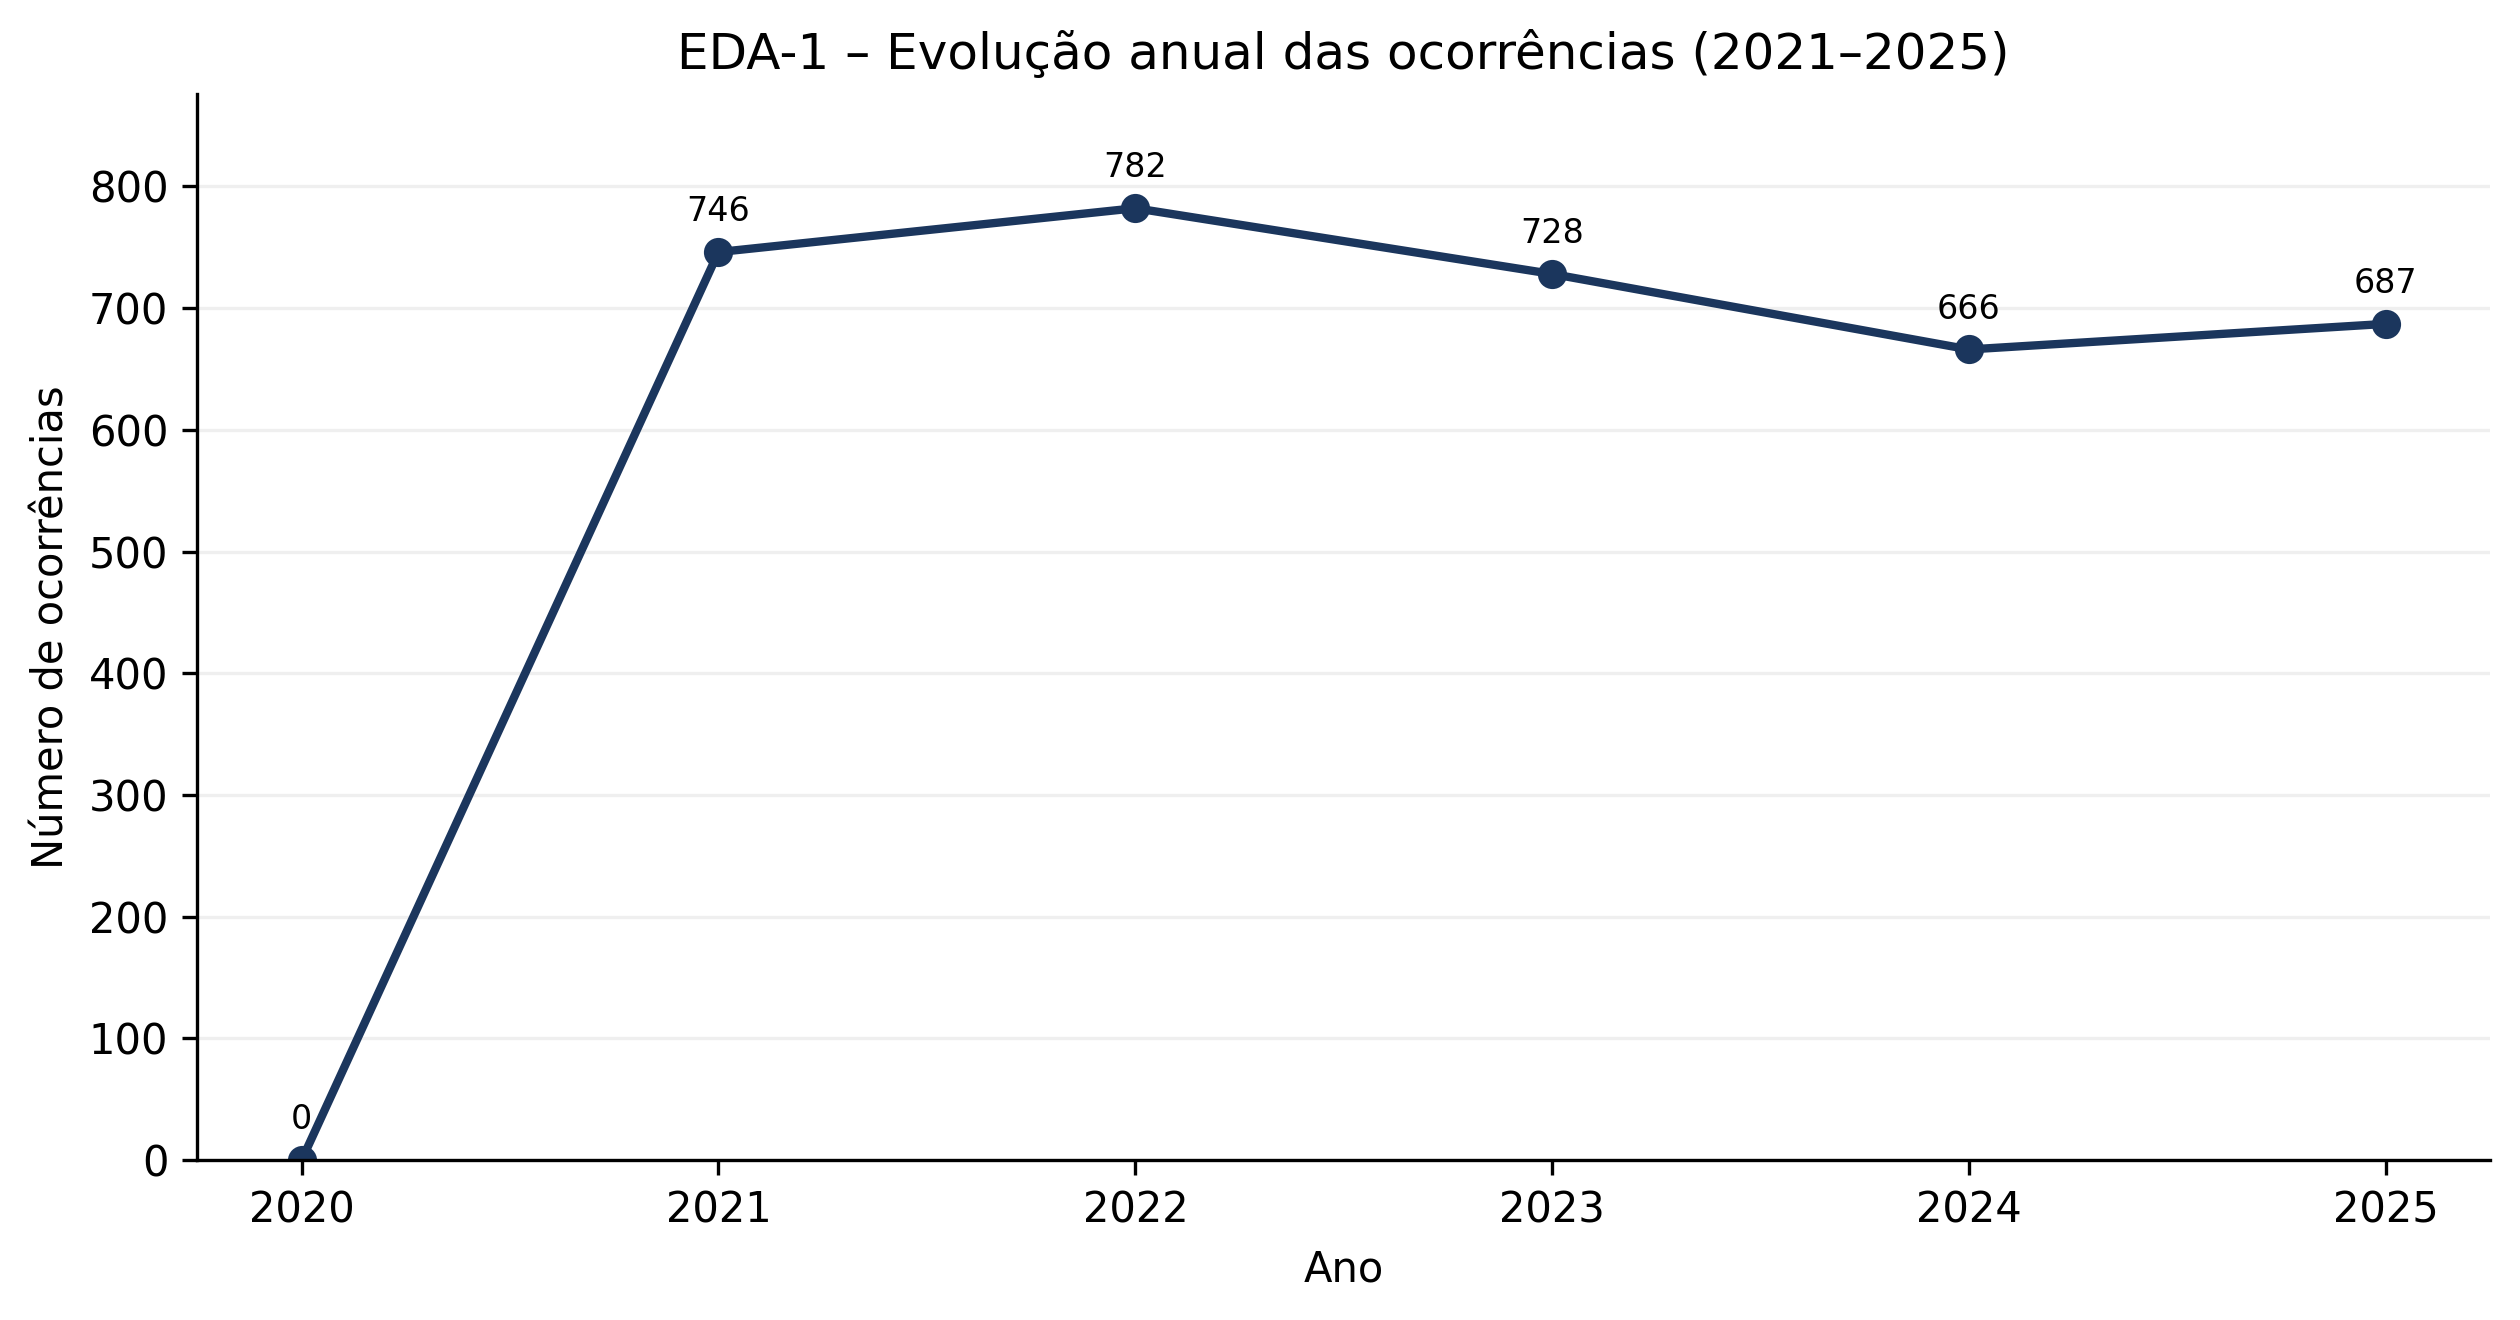

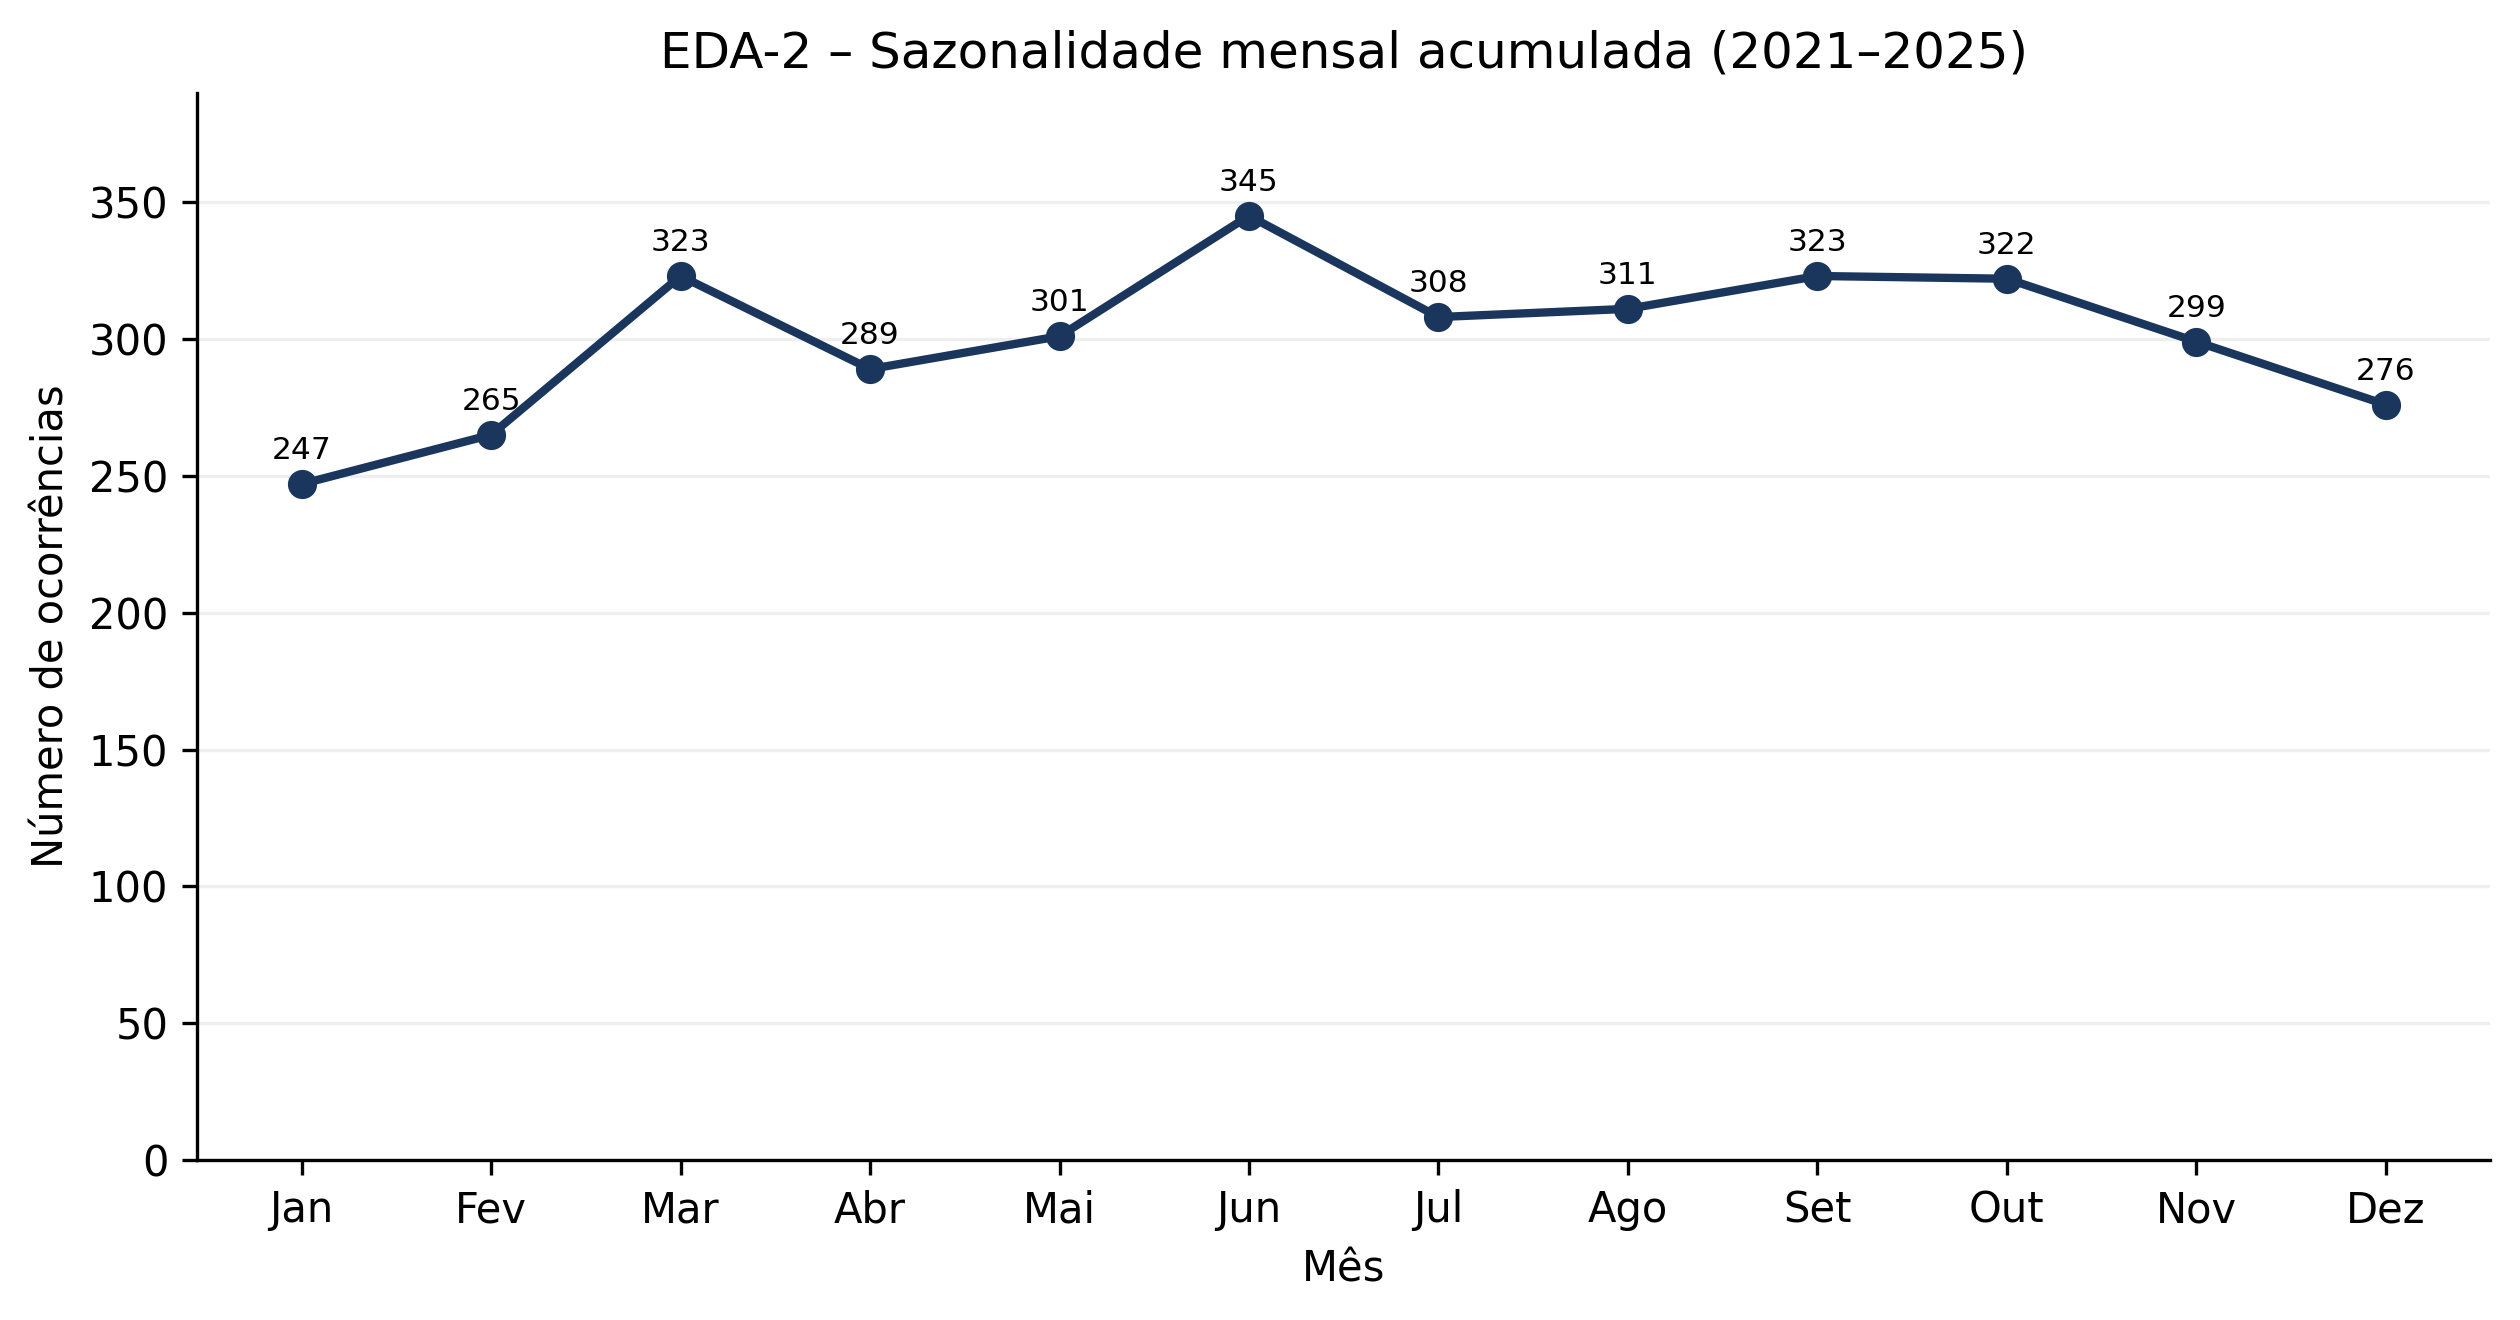

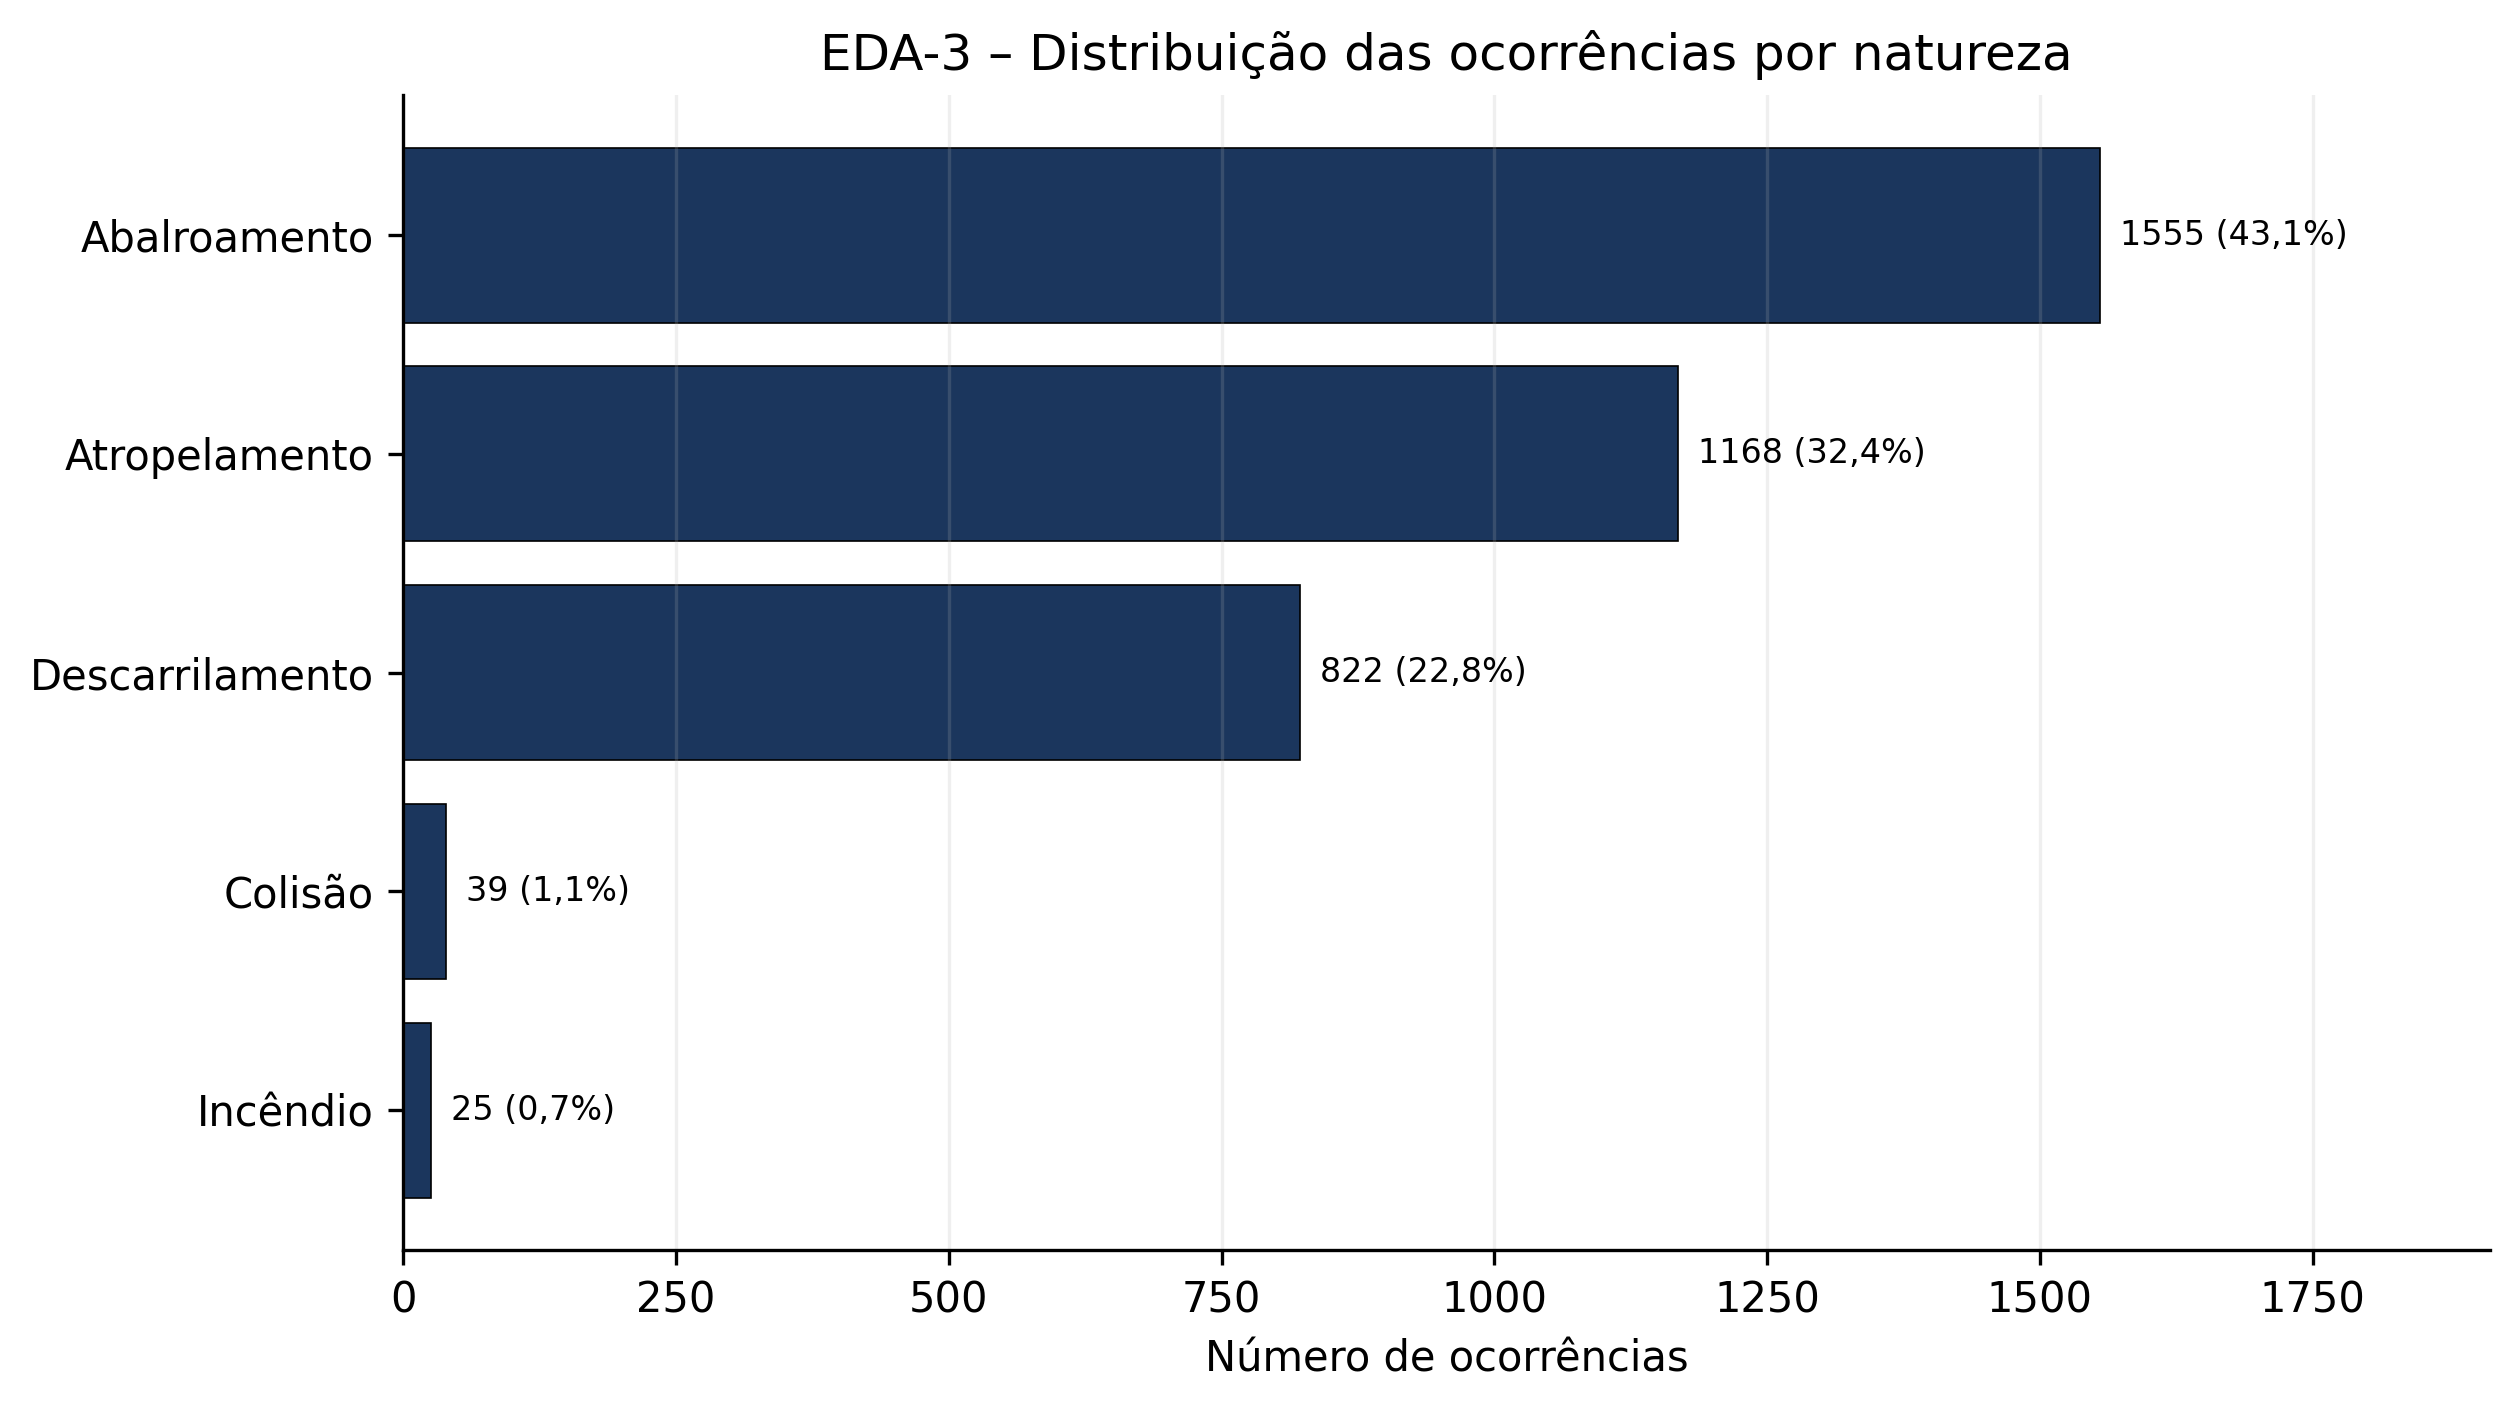

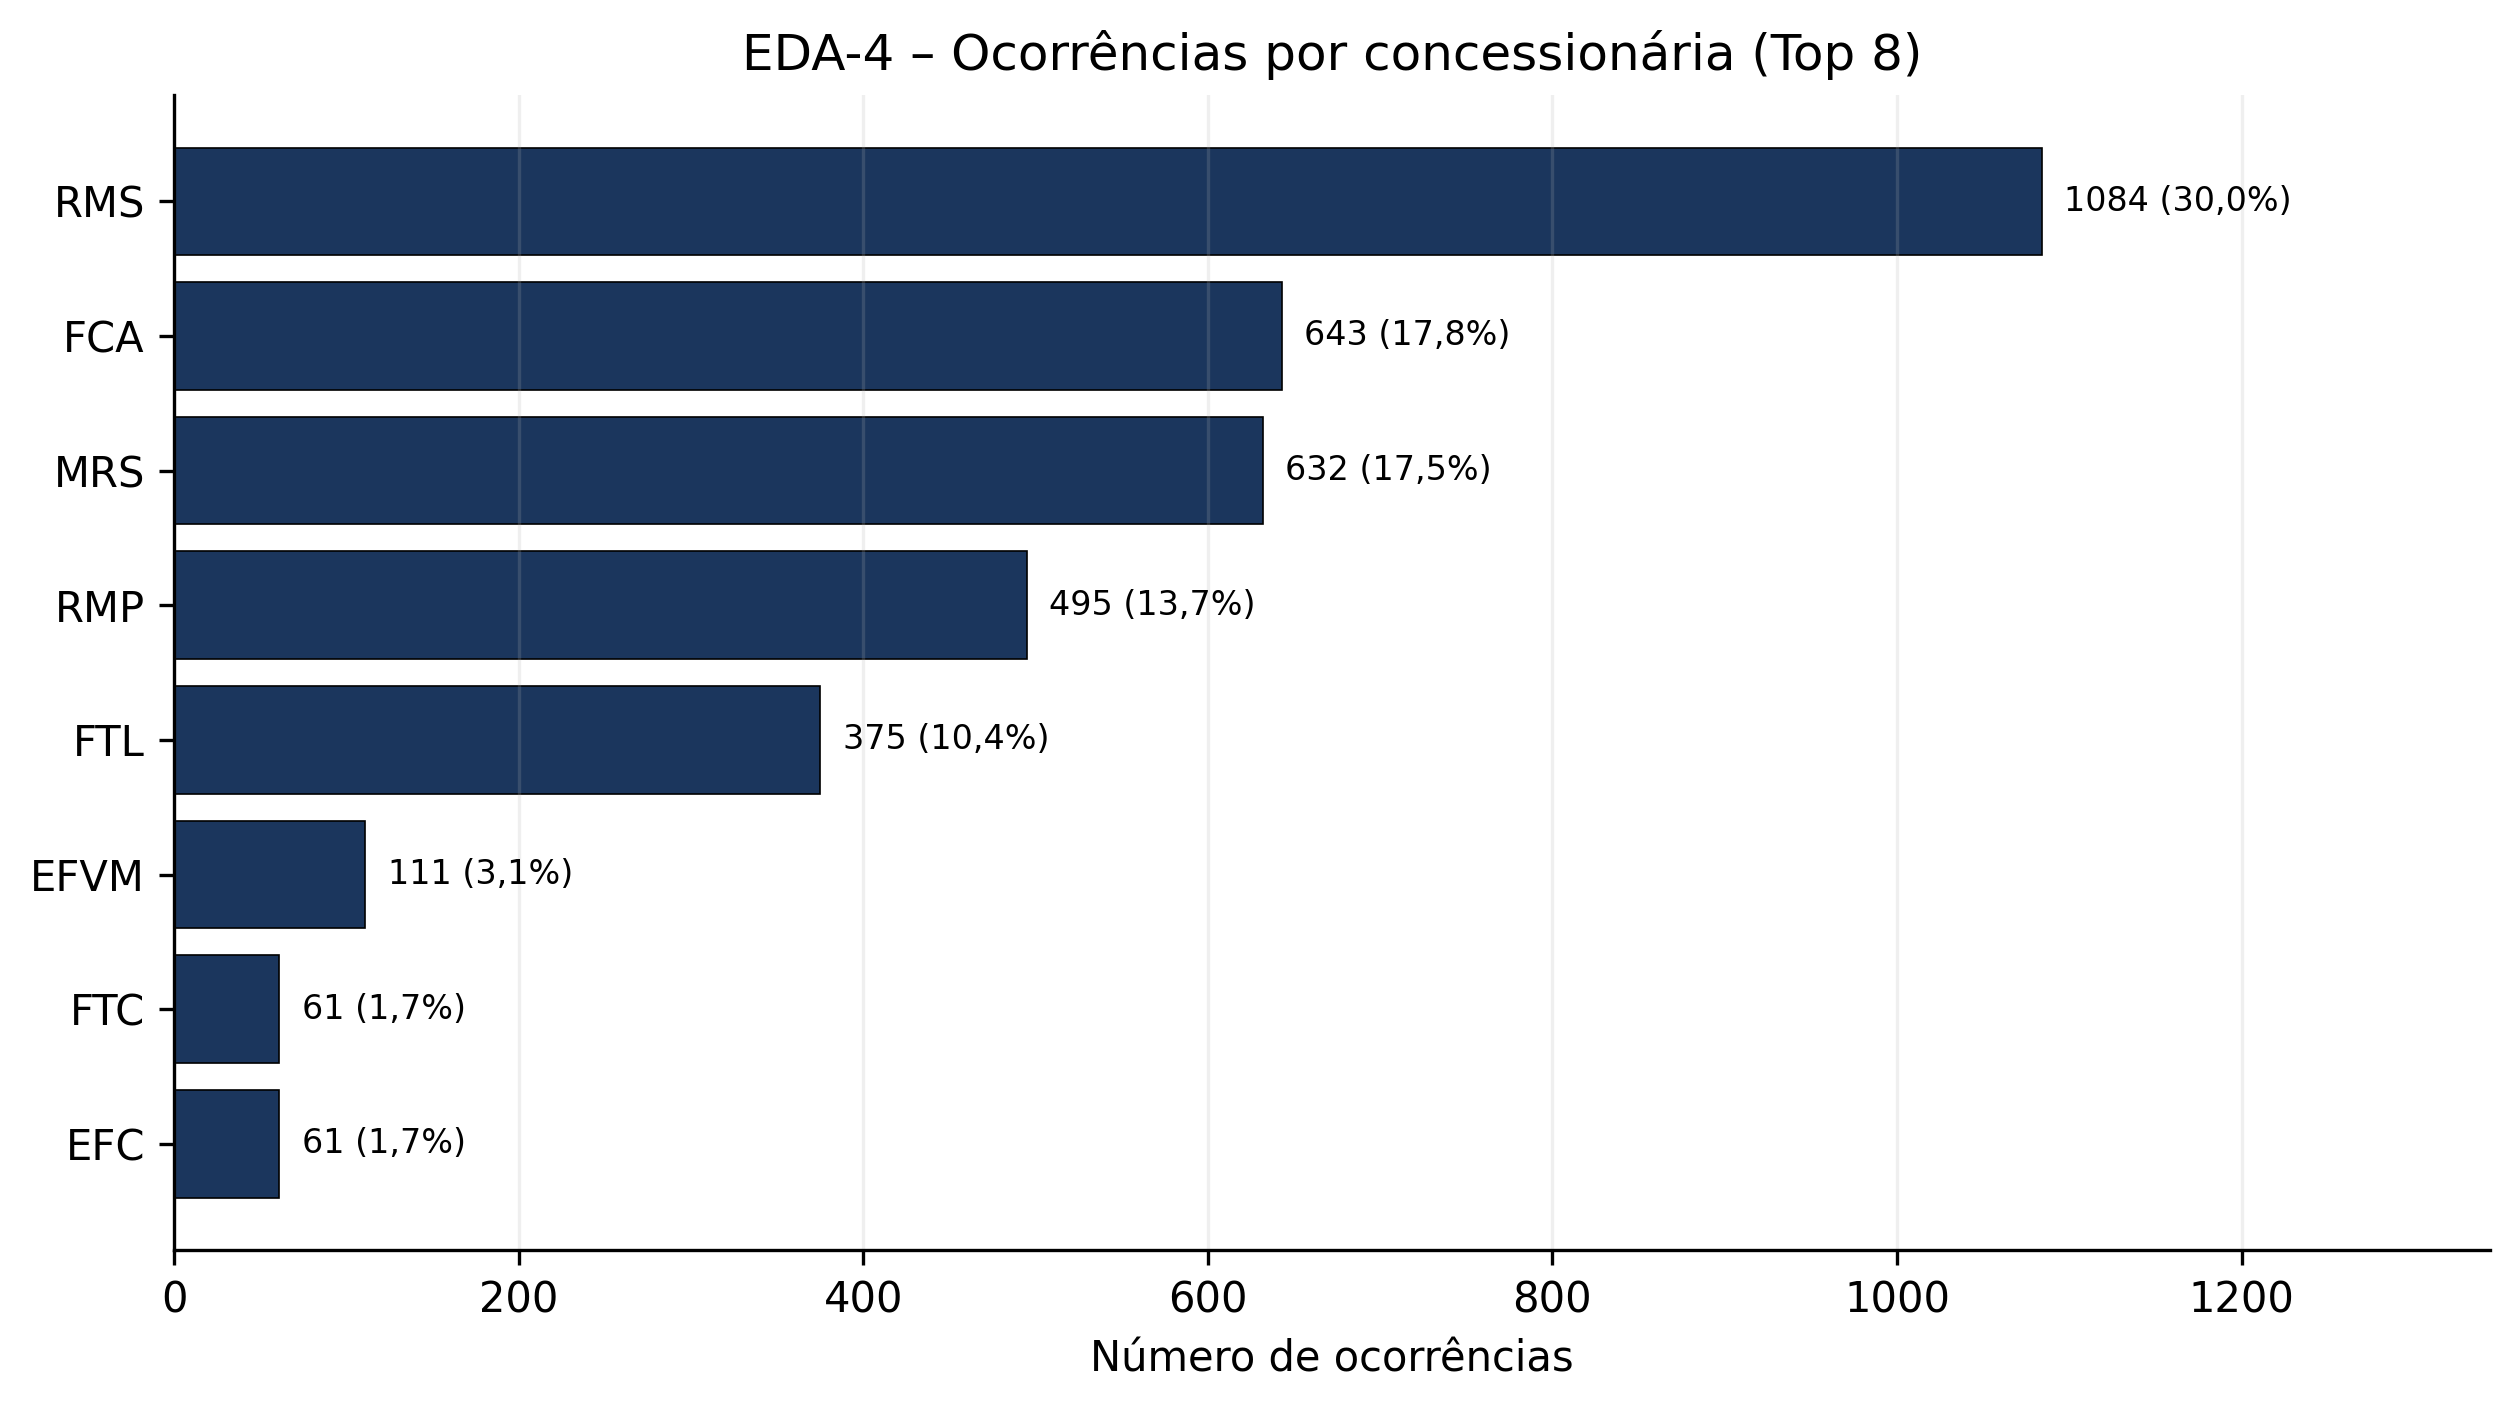

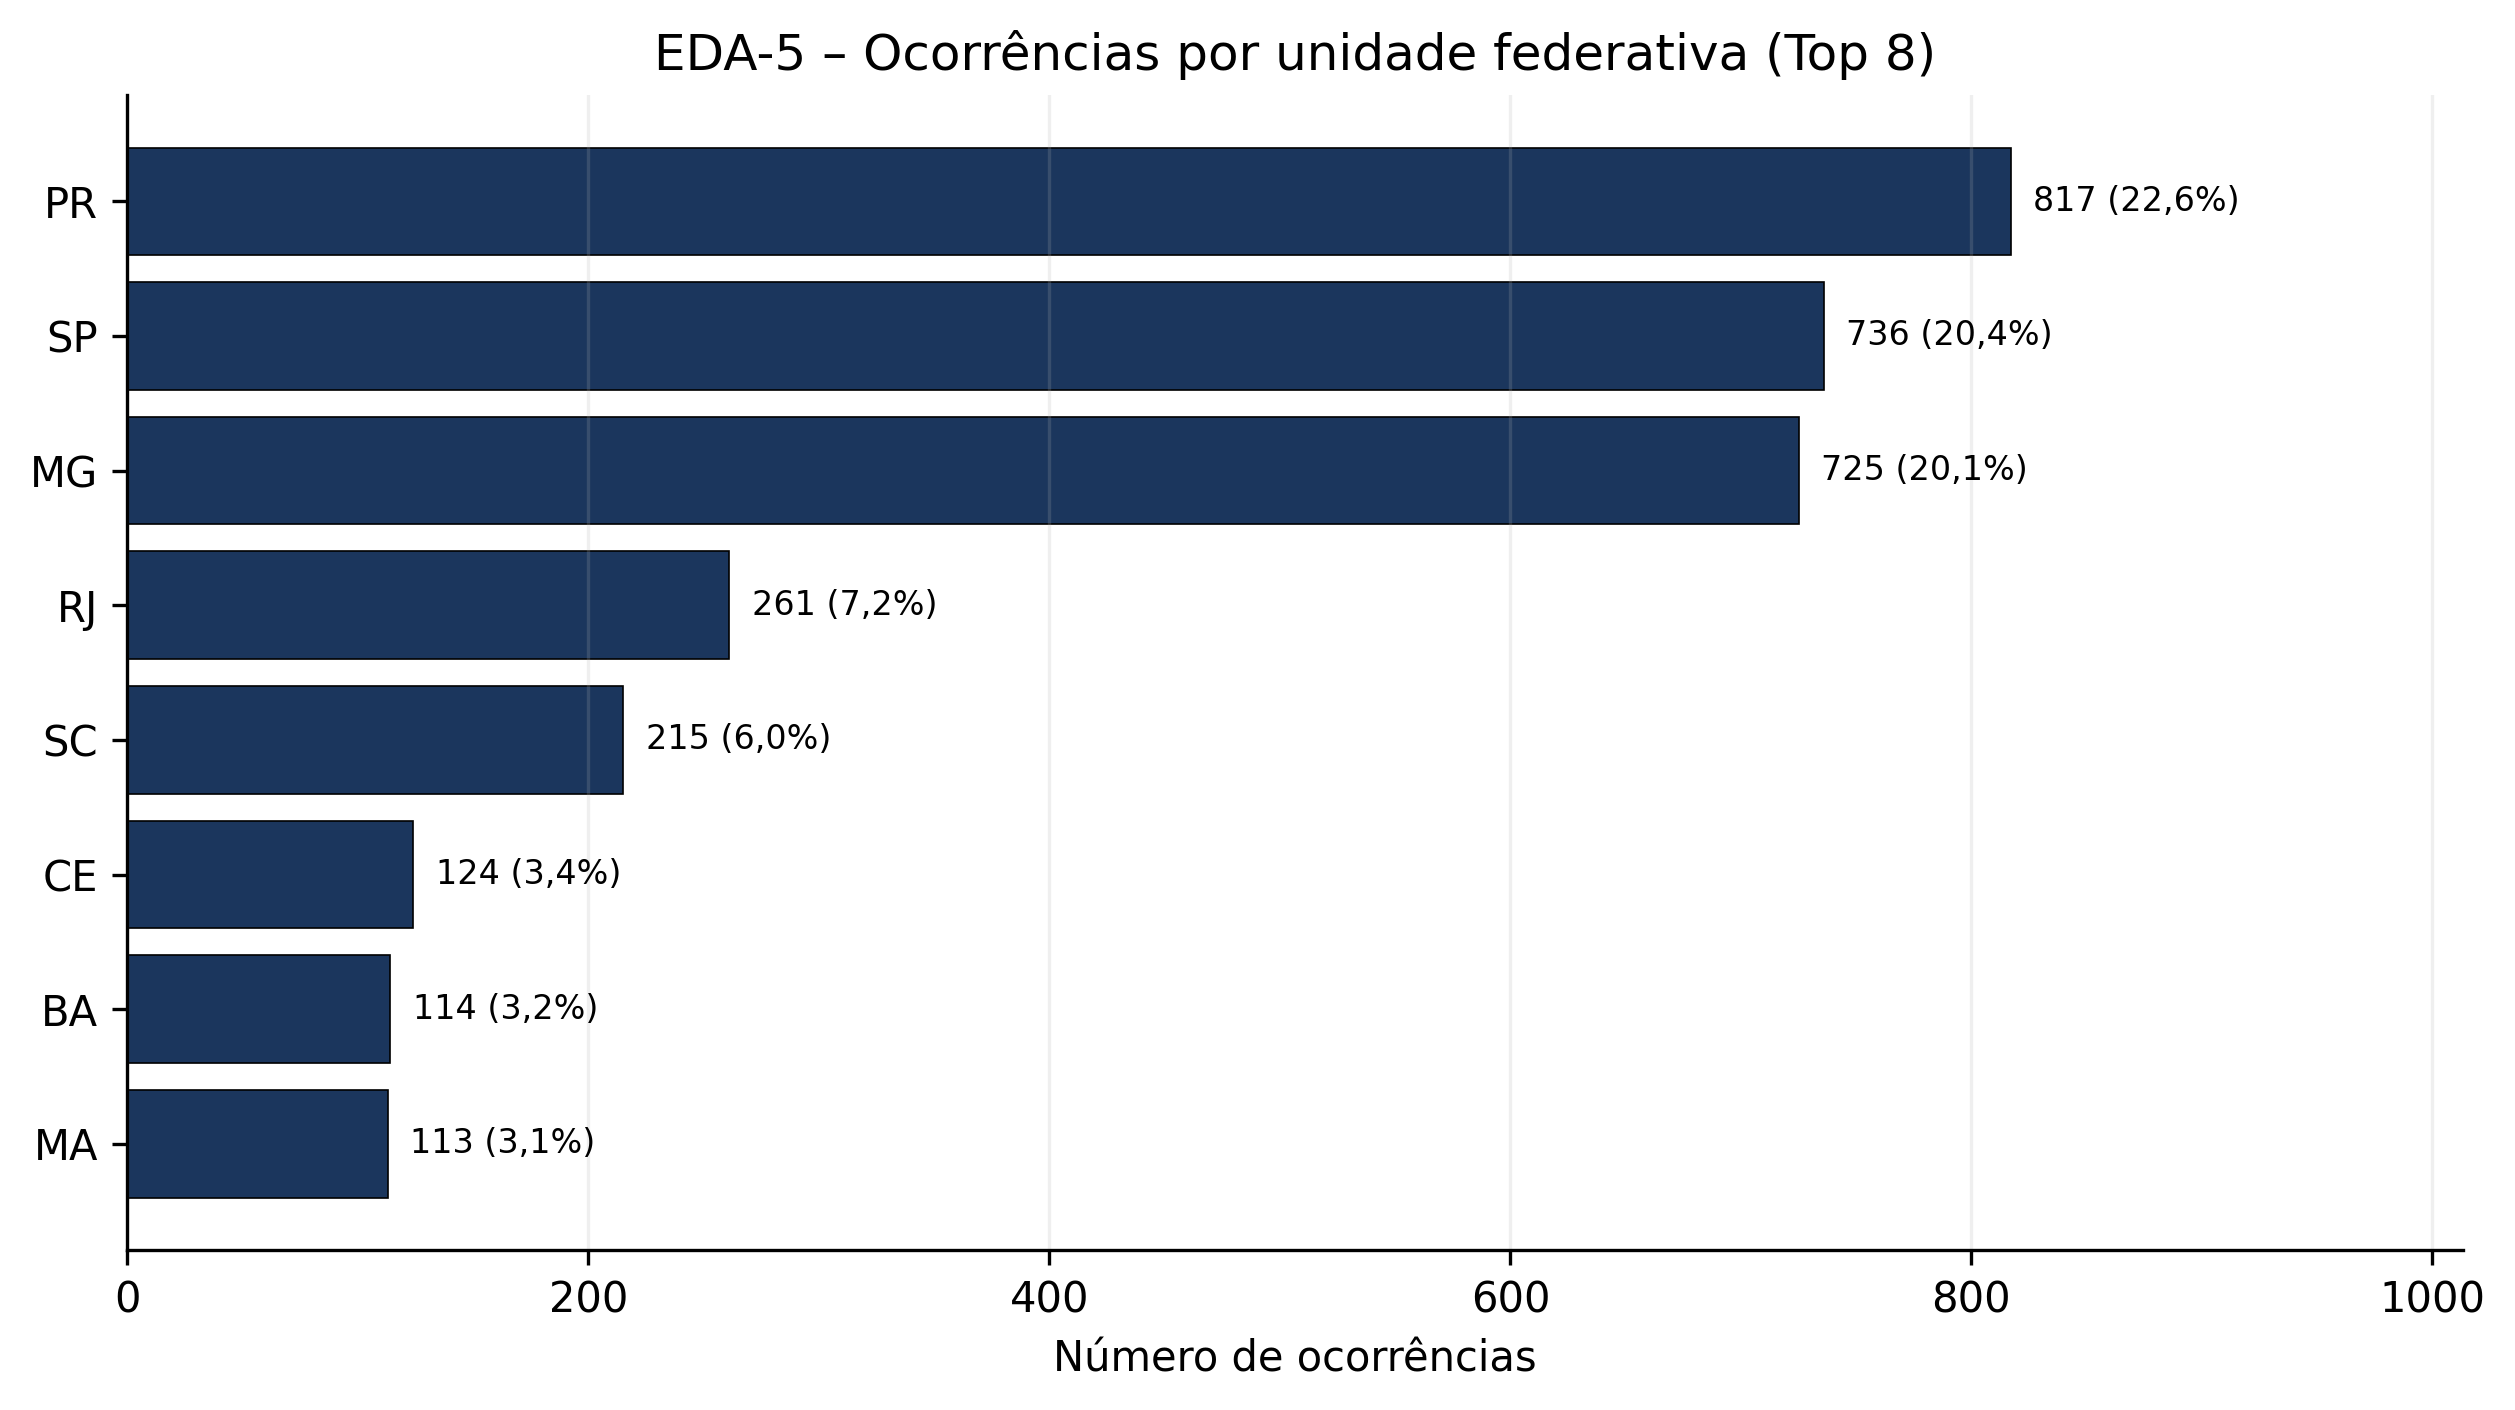

Fonte das EDA-1 a EDA-5: elaborado pelos autores, com base nos dados da ANTT (2026).


In [14]:
# ============================================================
# 10) ANÁLISE EXPLORATÓRIA NACIONAL – COMPLEMENTAR
# ============================================================

# As variáveis temporais são derivadas novamente a partir da data tratada
# para que esta seção permaneça independente de células exploratórias antigas.
df_final["Ano"] = df_final["Data_Ocorrencia_dt"].dt.year
df_final["Mes"] = df_final["Data_Ocorrencia_dt"].dt.month

# ------------------------------------------------------------
# EDA-1 – Evolução anual
# ------------------------------------------------------------
ano_counts = (
    df_final["Ano"]
    .value_counts()
    .sort_index()
    .reindex(range(2020, 2026), fill_value=0)
)

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=300)
ax.plot(
    ano_counts.index.astype(str),
    ano_counts.values,
    marker="o",
    linewidth=2.0,
    markersize=6,
    color="#1b365d",
)
ax.set_title("EDA-1 – Evolução anual das ocorrências (2021–2025)")
ax.set_ylabel("Número de ocorrências")
ax.set_xlabel("Ano")
ax.grid(axis="y", alpha=0.20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

margem = max(1, ano_counts.max() * 0.025)
for x, y in zip(ano_counts.index.astype(str), ano_counts.values):
    ax.text(x, y + margem, f"{int(y)}", ha="center", va="bottom", fontsize=8)

ax.set_ylim(0, max(ano_counts.max() * 1.12, 1))
plt.tight_layout()
plt.savefig("EDA_01_Evolucao_Anual.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# EDA-2 – Sazonalidade mensal acumulada
# ------------------------------------------------------------
mes_counts = (
    df_final["Mes"]
    .value_counts()
    .sort_index()
    .reindex(range(1, 13), fill_value=0)
)

meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=300)
ax.plot(
    meses,
    mes_counts.values,
    marker="o",
    linewidth=2.0,
    markersize=6,
    color="#1b365d",
)
ax.set_title("EDA-2 – Sazonalidade mensal acumulada (2021–2025)")
ax.set_ylabel("Número de ocorrências")
ax.set_xlabel("Mês")
ax.grid(axis="y", alpha=0.20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

margem = max(1, mes_counts.max() * 0.02)
for x, y in zip(meses, mes_counts.values):
    ax.text(x, y + margem, f"{int(y)}", ha="center", va="bottom", fontsize=7.5)

ax.set_ylim(0, max(mes_counts.max() * 1.13, 1))
plt.tight_layout()
plt.savefig("EDA_02_Sazonalidade_Mensal.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# EDA-3 – Natureza das ocorrências
# ------------------------------------------------------------
nat_counts = df_final["Natureza_Norm"].value_counts()
nat_plot = nat_counts.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=300)
bars = ax.barh(
    nat_plot.index,
    nat_plot.values,
    color="#1b365d",
    edgecolor="black",
    linewidth=0.4,
)
ax.set_title("EDA-3 – Distribuição das ocorrências por natureza")
ax.set_xlabel("Número de ocorrências")
ax.grid(axis="x", alpha=0.20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar, valor in zip(bars, nat_plot.values):
    pct = 100 * valor / len(df_final)
    ax.text(
        valor + max(nat_plot.max() * 0.012, 1),
        bar.get_y() + bar.get_height()/2,
        f"{int(valor)} ({pct:.1f}%)".replace(".", ","),
        va="center",
        fontsize=8,
    )
ax.set_xlim(0, max(nat_plot.max() * 1.23, 1))
plt.tight_layout()
plt.savefig("EDA_03_Natureza.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# EDA-4 – Concessionárias com mais registros
# ------------------------------------------------------------
conc_counts = df_final["Concessionaria"].value_counts().head(8).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=300)
bars = ax.barh(
    conc_counts.index,
    conc_counts.values,
    color="#1b365d",
    edgecolor="black",
    linewidth=0.4,
)
ax.set_title("EDA-4 – Ocorrências por concessionária (Top 8)")
ax.set_xlabel("Número de ocorrências")
ax.grid(axis="x", alpha=0.20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar, valor in zip(bars, conc_counts.values):
    pct = 100 * valor / len(df_final)
    ax.text(
        valor + max(conc_counts.max() * 0.012, 1),
        bar.get_y() + bar.get_height()/2,
        f"{int(valor)} ({pct:.1f}%)".replace(".", ","),
        va="center",
        fontsize=8,
    )
ax.set_xlim(0, max(conc_counts.max() * 1.24, 1))
plt.tight_layout()
plt.savefig("EDA_04_Concessionarias.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# EDA-5 – UFs com mais registros (se a coluna estiver disponível)
# ------------------------------------------------------------
if "UF" in df_final.columns:
    uf_counts = (
        df_final["UF"]
        .dropna()
        .astype(str)
        .str.strip()
        .value_counts()
        .head(8)
        .sort_values()
    )

    fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=300)
    bars = ax.barh(
        uf_counts.index,
        uf_counts.values,
        color="#1b365d",
        edgecolor="black",
        linewidth=0.4,
    )
    ax.set_title("EDA-5 – Ocorrências por unidade federativa (Top 8)")
    ax.set_xlabel("Número de ocorrências")
    ax.grid(axis="x", alpha=0.20)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for bar, valor in zip(bars, uf_counts.values):
        pct = 100 * valor / len(df_final)
        ax.text(
            valor + max(uf_counts.max() * 0.012, 1),
            bar.get_y() + bar.get_height()/2,
            f"{int(valor)} ({pct:.1f}%)".replace(".", ","),
            va="center",
            fontsize=8,
        )
    ax.set_xlim(0, max(uf_counts.max() * 1.24, 1))
    plt.tight_layout()
    plt.savefig("EDA_05_UFs.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("EDA-5 não gerada: a coluna 'UF' não está disponível nesta edição da base.")

print("Fonte das EDA-1 a EDA-5: elaborado pelos autores, com base nos dados da ANTT (2026).")

## 10.1 Exploração complementar de severidade e contexto

Além das distribuições gerais, foram avaliadas variáveis relacionadas às consequências e ao contexto dos registros. Esta etapa é mantida como documentação exploratória e **não deve ser interpretada como análise causal nem como medida de risco**.


In [15]:
# ============================================================
# 10.1) EDA COMPLEMENTAR – SEVERIDADE E CONTEXTO
# ============================================================

resumo_nacional = pd.DataFrame({
    "Indicador": [
        "Ocorrências",
        "Feridos registrados",
        "Óbitos registrados",
        "Ocorrências em PN (%)",
        "Ocorrências em área urbana (%)",
        "Interação com terceiros (%)",
    ],
    "Valor": [
        len(df_final),
        float(df_final["N_feridos"].sum()),
        float(df_final["N_obitos"].sum()),
        100 * df_final["PN_Norm"].eq("Sim").mean(),
        100 * df_final["Perimetro_Urbano_Norm"].eq("Sim").mean(),
        100 * (
            df_final["Causa_direta"]
            .astype(str)
            .map(corrigir_mojibake)
            .str.casefold()
            .str.contains("terceir", na=False)
            .mean()
        ),
    ],
})

display(resumo_nacional.round(2))

if "Periodo_Dia_Norm" in df_final.columns:
    print("\nDistribuição por período do dia:")
    display(
        df_final["Periodo_Dia_Norm"]
        .value_counts()
        .rename("Ocorrências")
        .to_frame()
    )

if "Servico_Transporte_Norm" in df_final.columns:
    print("\nDistribuição por serviço de transporte:")
    display(
        df_final["Servico_Transporte_Norm"]
        .value_counts()
        .rename("Ocorrências")
        .to_frame()
    )

print("\nCausa direta – categorias mais frequentes:")
display(
    df_final["Causa_direta"]
    .value_counts(dropna=False)
    .head(10)
    .rename("Ocorrências")
    .to_frame()
)


,Indicador,Valor
0,Ocorrências,3609.00
1,Feridos registrados,1256.00
2,Óbitos registrados,532.00
3,Ocorrências em PN (%),46.27
4,Ocorrências em área urbana (%),83.93
5,Interação com terceiros (%),75.34



Distribuição por período do dia:


,Ocorrências
Periodo_Dia_Norm,
Tarde (12h00 às 17h59),1099
Manhã (06h00 às 11h59),963
Noite (18h00 às 23h59),942
Madrugada (00h00 às 05h59),605



Distribuição por serviço de transporte:


,Ocorrências
Servico_Transporte_Norm,
Cargas,3286
Não Informado,133
Manutenção / Serviço Interno,99
Locomotiva Escoteira,61
Passageiros,29
Outros / Misto,1



Causa direta – categorias mais frequentes:


,Ocorrências
Causa_direta,
Interferência de Terceiro,2719
Via Permanente,548
Material Rodante,168
Falha Humana,68
Casos Fortuitos ou de Força Maior,59
Outras Causas,41
Gestão,4
Sistemas,2


## 11. Caracterização comparativa da Rumo Malha Sul — utilizada no artigo

**Correspondência com o artigo:** **Seção 3.1 – Caracterização comparativa da Rumo Malha Sul** e **Figura 1**.

Esta é a parcela da análise exploratória que foi incorporada ao manuscrito. A comparação considera **interação com terceiros**, **Passagem em Nível** e **área urbana**. As proporções descrevem o perfil das ocorrências registradas e não devem ser interpretadas, isoladamente, como medida de risco ferroviário.

,Rumo Malha Sul (RMS),Demais Concessionárias
Interação com Terceiros,91.79,68.28
Passagem em Nível,66.05,37.78
Área Urbana,87.18,82.53


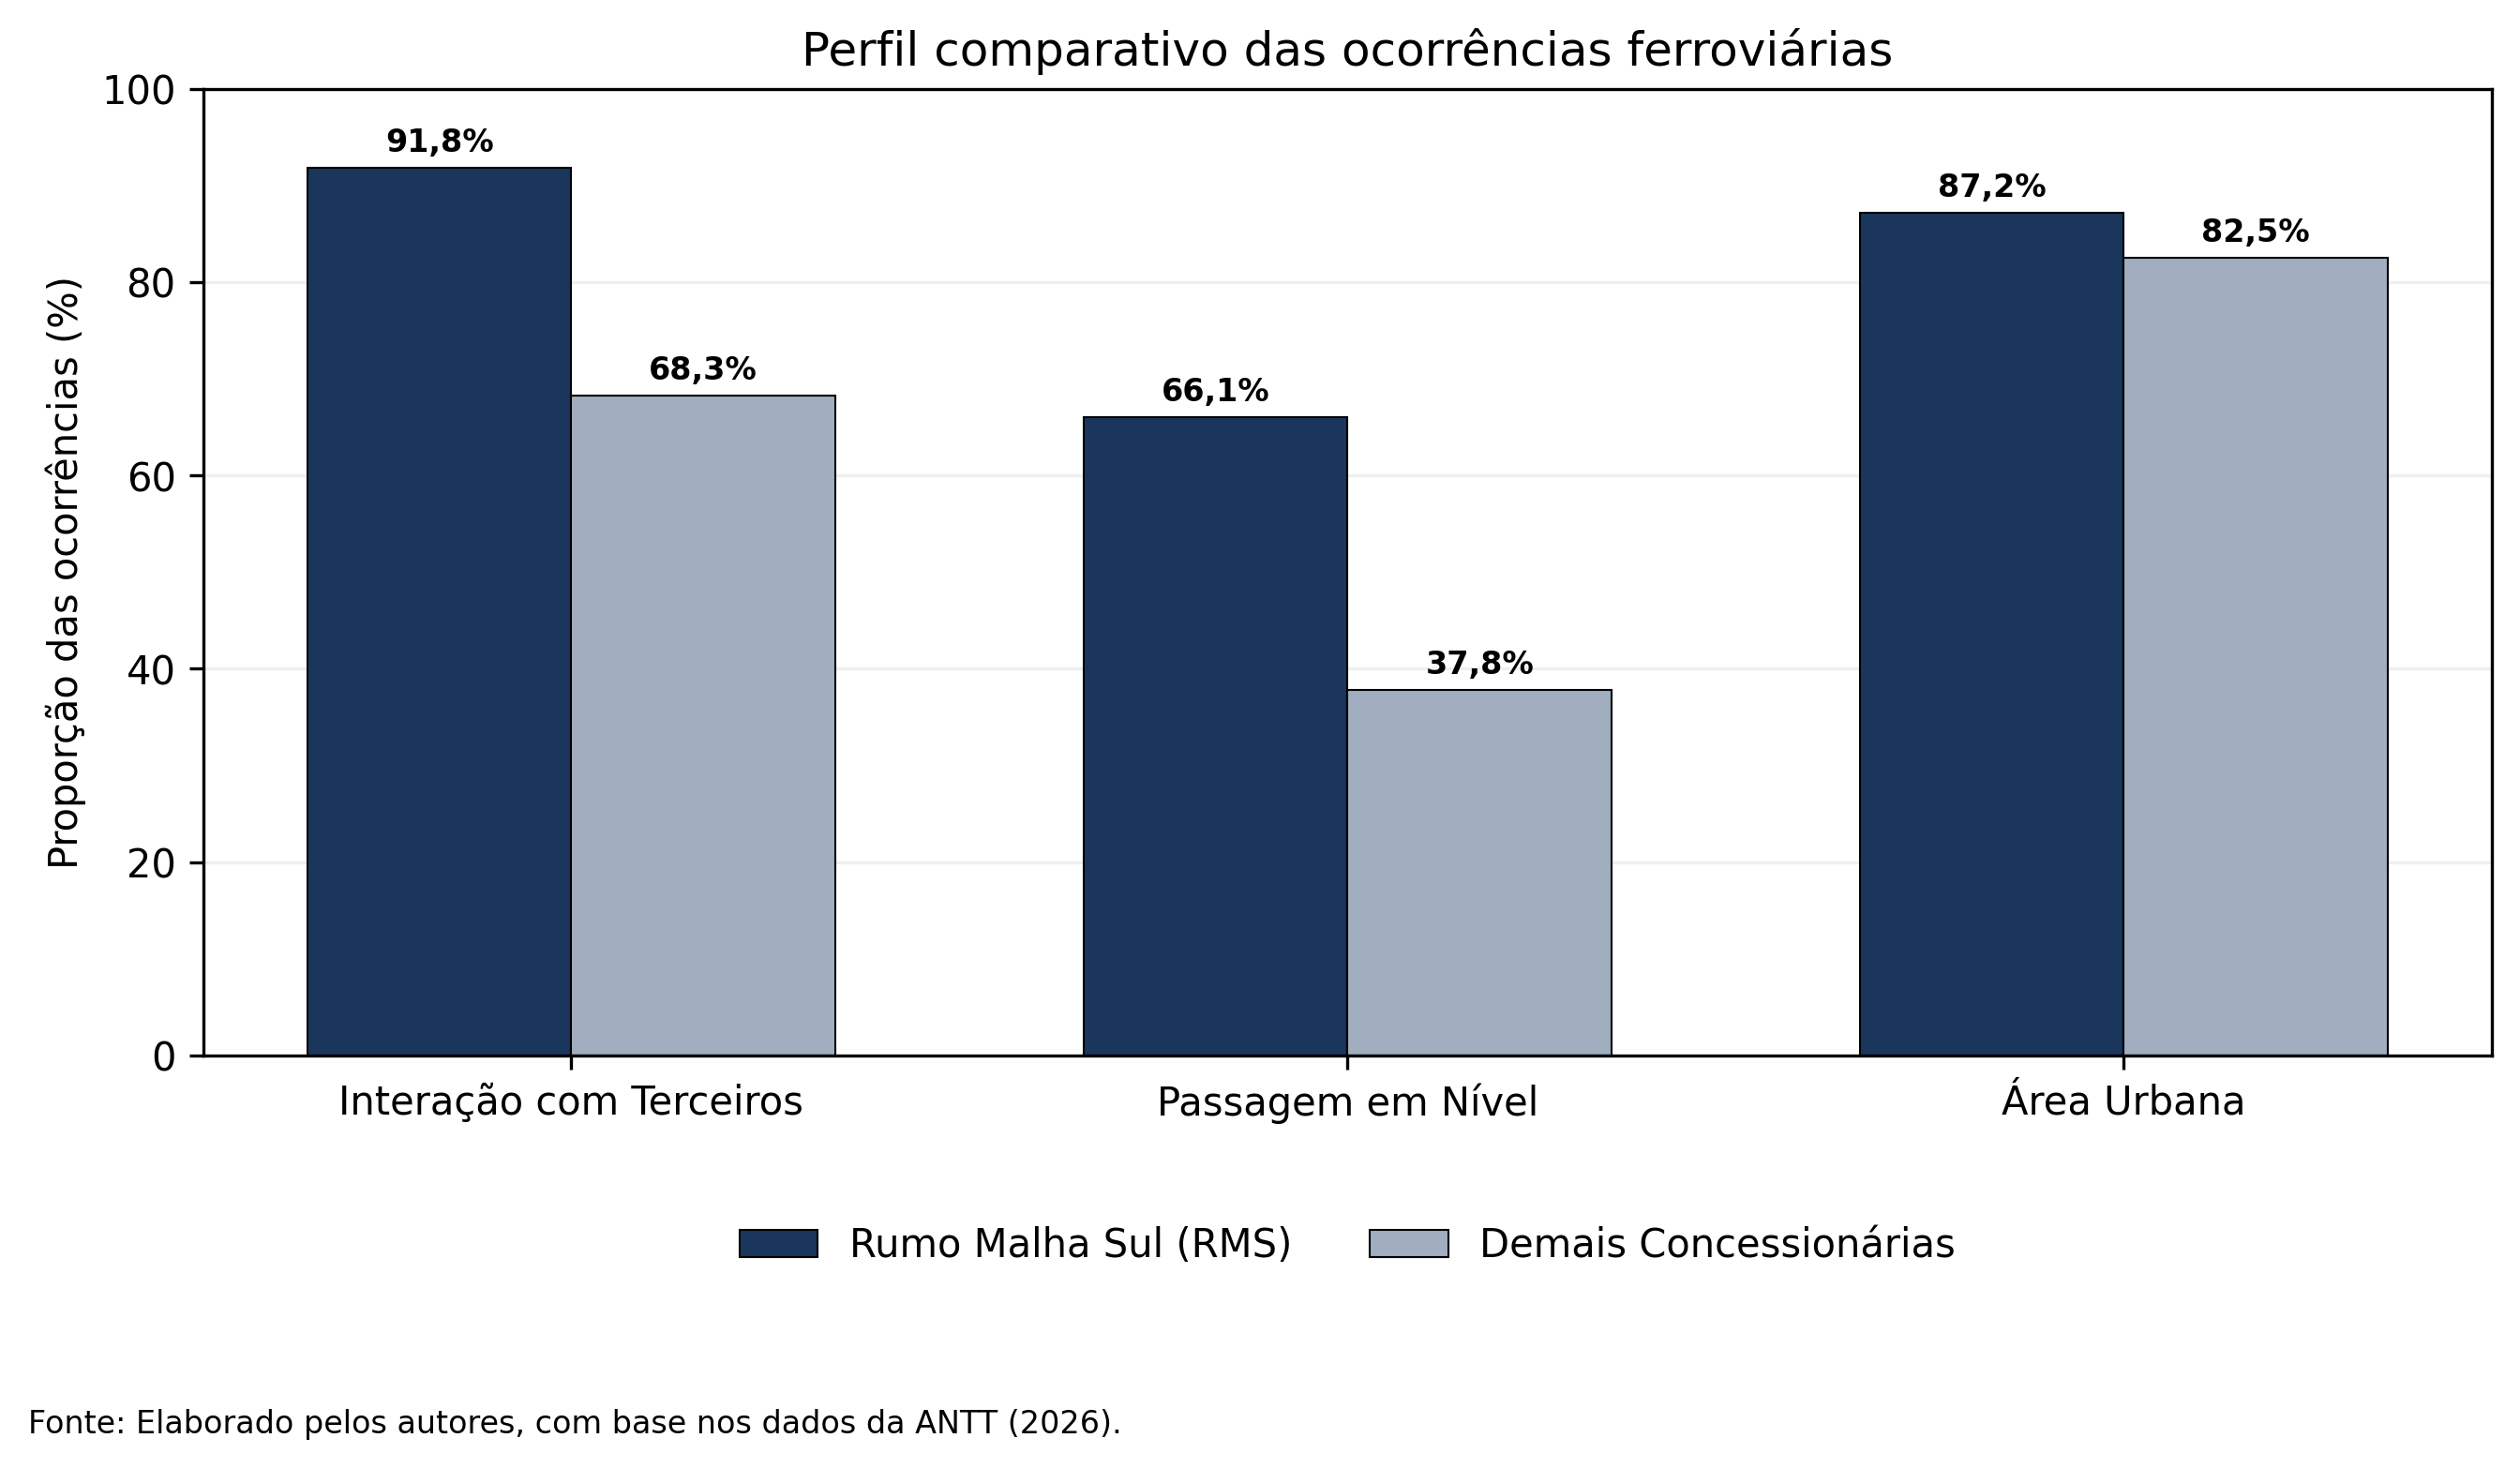

In [16]:
# ============================================================
# 10) FIGURA 1 – PERFIL COMPARATIVO RMS x DEMAIS
# ============================================================

df_final["Grupo_Concessao"] = np.where(
    df_final["Concessionaria"]
    .astype(str)
    .str.strip()
    .eq("RMS"),
    "Rumo Malha Sul (RMS)",
    "Demais Concessionárias",
)

causa_norm = (
    df_final["Causa_direta"]
    .astype(str)
    .map(corrigir_mojibake)
    .str.casefold()
)

df_final["Interacao_Terceiros"] = (
    causa_norm.str.contains(
        "terceir",
        na=False
    )
)

pct_terceiros = (
    df_final
    .groupby("Grupo_Concessao")["Interacao_Terceiros"]
    .mean()
    .mul(100)
)

pct_pn = (
    df_final
    .assign(
        Em_PN=df_final["PN_Norm"].eq("Sim")
    )
    .groupby("Grupo_Concessao")["Em_PN"]
    .mean()
    .mul(100)
)

pct_urbana = (
    df_final
    .assign(
        Area_Urbana=df_final["Perimetro_Urbano_Norm"].eq("Sim")
    )
    .groupby("Grupo_Concessao")["Area_Urbana"]
    .mean()
    .mul(100)
)

perfil_comparativo = pd.DataFrame(
    {
        "Rumo Malha Sul (RMS)": [
            pct_terceiros.get("Rumo Malha Sul (RMS)", np.nan),
            pct_pn.get("Rumo Malha Sul (RMS)", np.nan),
            pct_urbana.get("Rumo Malha Sul (RMS)", np.nan),
        ],
        "Demais Concessionárias": [
            pct_terceiros.get("Demais Concessionárias", np.nan),
            pct_pn.get("Demais Concessionárias", np.nan),
            pct_urbana.get("Demais Concessionárias", np.nan),
        ],
    },
    index=[
        "Interação com Terceiros",
        "Passagem em Nível",
        "Área Urbana",
    ],
)

display(perfil_comparativo.round(2))

fig, ax = plt.subplots(
    figsize=(9, 5.2),
    dpi=300
)

x = np.arange(
    len(perfil_comparativo.index)
)
largura = 0.34

b1 = ax.bar(
    x - largura / 2,
    perfil_comparativo["Rumo Malha Sul (RMS)"],
    width=largura,
    label="Rumo Malha Sul (RMS)",
    color="#1b365d",
    edgecolor="black",
    linewidth=0.5,
)

b2 = ax.bar(
    x + largura / 2,
    perfil_comparativo["Demais Concessionárias"],
    width=largura,
    label="Demais Concessionárias",
    color="#a0aec0",
    edgecolor="black",
    linewidth=0.5,
)

ax.set_ylabel(
    "Proporção das ocorrências (%)"
)
ax.set_title(
    "Perfil comparativo das ocorrências ferroviárias"
)
ax.set_xticks(x)
ax.set_xticklabels(
    perfil_comparativo.index
)
ax.set_ylim(0, 100)
ax.grid(
    axis="y",
    alpha=0.2
)
ax.set_axisbelow(True)

for barras in [b1, b2]:
    for barra in barras:
        valor = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            valor + 1.0,
            f"{valor:.1f}%".replace(".", ","),
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold",
        )

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=2,
    frameon=False,
)

fig.text(
    0.01,
    0.01,
    "Fonte: Elaborado pelos autores, com base nos dados da ANTT (2026).",
    fontsize=8,
)

plt.tight_layout(
    rect=[0, 0.07, 1, 1]
)

plt.savefig(
    "Figura_1_Perfil_Comparativo_RMS.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 12. Exploração descritiva da RMS — complementar

**Status no artigo:** complementar. Os indicadores abaixo ajudam a contextualizar a Seção 3.1, mas não foram apresentados como uma figura adicional no manuscrito.

A célula resume o universo RMS por ano, natureza, município e linha ferroviária, além de apresentar totais de feridos, óbitos e proporções de PN e área urbana.

In [17]:
# ============================================================
# 12) EXPLORAÇÃO DESCRITIVA DA RMS – COMPLEMENTAR
# ============================================================

df_rms_eda = df_rms.copy()
df_rms_eda["Ano"] = df_rms_eda["Data_Ocorrencia_dt"].dt.year

resumo_rms = pd.DataFrame({
    "Indicador": [
        "Ocorrências",
        "Feridos",
        "Óbitos",
        "Ocorrências em PN (%)",
        "Ocorrências em área urbana (%)",
        "Interação com terceiros (%)",
    ],
    "Valor": [
        len(df_rms_eda),
        df_rms_eda["N_feridos"].sum(),
        df_rms_eda["N_obitos"].sum(),
        100 * df_rms_eda["PN_Norm"].eq("Sim").mean(),
        100 * df_rms_eda["Perimetro_Urbano_Norm"].eq("Sim").mean(),
        100 * df_rms_eda["Causa_direta"].astype(str).map(corrigir_mojibake).str.casefold().str.contains("terceir", na=False).mean(),
    ],
})

display(resumo_rms.round(2))

print("\nOcorrências RMS por ano:")
display(
    df_rms_eda["Ano"]
    .value_counts()
    .sort_index()
    .rename("Ocorrências")
    .to_frame()
)

print("\nNatureza das ocorrências na RMS:")
display(
    df_rms_eda["Natureza_Norm"]
    .value_counts()
    .rename("Ocorrências")
    .to_frame()
)

print("\nMunicípios com maior número de registros na RMS:")
display(
    df_rms_eda["Municipio"]
    .value_counts()
    .head(10)
    .rename("Ocorrências")
    .to_frame()
)

print("\nLinhas ferroviárias com maior número de registros na RMS:")
display(
    df_rms_eda["Linha"]
    .value_counts()
    .head(10)
    .rename("Ocorrências")
    .to_frame()
)

,Indicador,Valor
0,Ocorrências,1084.00
1,Feridos,376.00
2,Óbitos,113.00
3,Ocorrências em PN (%),66.05
4,Ocorrências em área urbana (%),87.18
5,Interação com terceiros (%),91.79



Ocorrências RMS por ano:


,Ocorrências
Ano,
2021,214
2022,266
2023,198
2024,177
2025,229



Natureza das ocorrências na RMS:


,Ocorrências
Natureza_Norm,
Abalroamento,714
Atropelamento,286
Descarrilamento,80
Colisão,3
Incêndio,1



Municípios com maior número de registros na RMS:


,Ocorrências
Municipio,
Curitiba,188
Paranagua,90
Ponta Grossa,69
Apucarana,49
Pinhais,45
Joinville,34
Arapongas,34
Piraquara,32
Sao Francisco do Sul,32



Linhas ferroviárias com maior número de registros na RMS:


,Ocorrências
Linha,
Paranaguá - Uvaranas,355
Ourinhos - Cianorte,199
Mafra - Francisco do Sul,138
Uvaranas - Apucarana,138
Sub-Ramal de Rio Branco do Sul,60
Bagé - Rio Grande,26
Eng. Gutierrez - Guarapuava,22
Desvio Ribas - Eng. Gutierrez,19
Mafra - Lages,14


## 13. Exploração específica de Curitiba — complementar

**Status no artigo:** análise complementar, **não incluída como figura no corpo do manuscrito**.

Curitiba aparece entre os principais hotspots priorizados. Por isso, esta análise é mantida no notebook para inspeção adicional do perfil local, sem alterar o procedimento de clusterização ou o ranking apresentado no artigo.

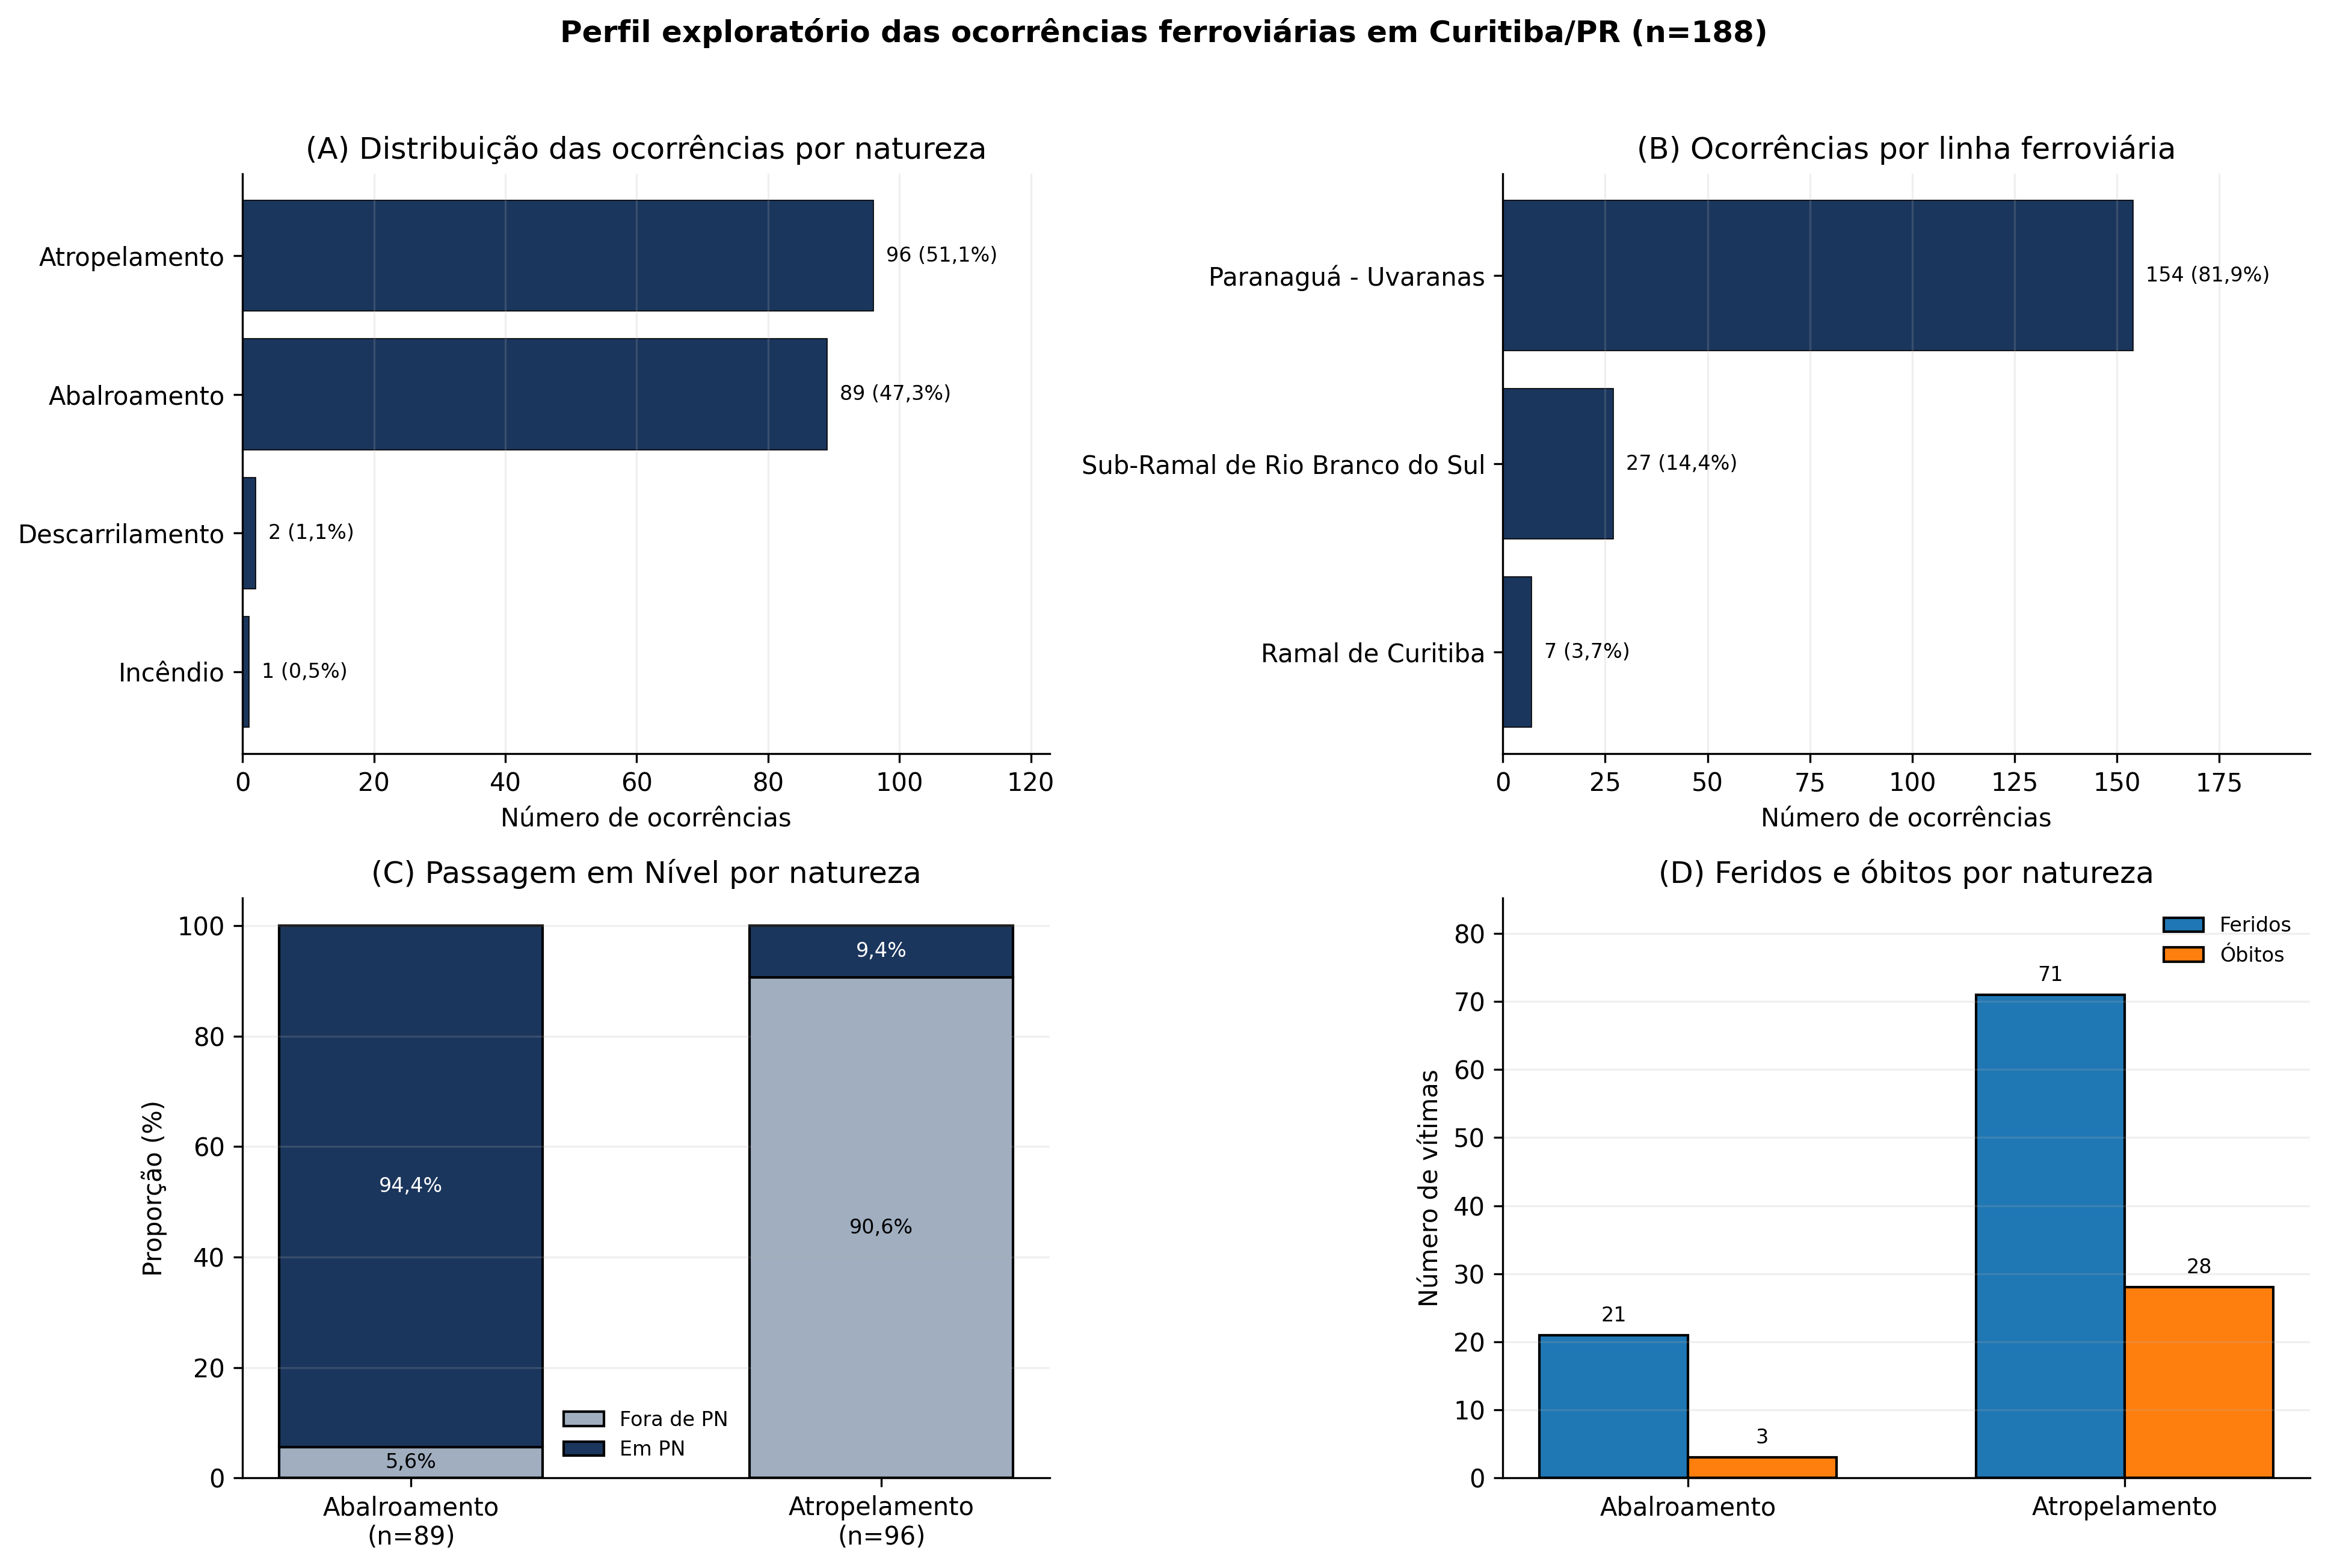

Fonte: elaborado pelos autores, com base nos dados da ANTT (2026).


In [18]:
# ============================================================
# 13) EXPLORAÇÃO DE CURITIBA – COMPLEMENTAR
# ============================================================

df_curitiba = df_final[
    df_final["Municipio"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq("curitiba")
].copy()

n_curitiba = len(df_curitiba)

if n_curitiba == 0:
    print("Nenhuma ocorrência de Curitiba foi localizada.")
else:
    # A) Natureza
    nat_cur = df_curitiba["Natureza_Norm"].value_counts()
    nat_plot = pd.DataFrame({
        "Quantidade": nat_cur,
        "Percentual": 100 * nat_cur / n_curitiba,
    }).sort_values("Quantidade")

    # B) Linhas ferroviárias
    linha_cur = df_curitiba["Linha"].value_counts()
    linha_plot = pd.DataFrame({
        "Quantidade": linha_cur,
        "Percentual": 100 * linha_cur / n_curitiba,
    }).sort_values("Quantidade")

    # C) PN por natureza
    naturezas_interesse = ["Abalroamento", "Atropelamento"]
    df_mecanismo = df_curitiba[
        df_curitiba["Natureza_Norm"].isin(naturezas_interesse)
    ].copy()

    pn_nat_cur_pct = (
        pd.crosstab(
            df_mecanismo["Natureza_Norm"],
            df_mecanismo["PN_Norm"],
            normalize="index",
        ) * 100
    )

    for coluna in ["Não", "Sim"]:
        if coluna not in pn_nat_cur_pct.columns:
            pn_nat_cur_pct[coluna] = 0.0

    mec_cur_df = (
        pn_nat_cur_pct
        .reindex(naturezas_interesse)
        .fillna(0)[["Não", "Sim"]]
    )

    n_natureza = df_mecanismo["Natureza_Norm"].value_counts()

    # D) Vítimas por natureza
    vit_cur_summary = (
        df_curitiba[
            df_curitiba["Natureza_Norm"].isin(naturezas_interesse)
        ]
        .groupby("Natureza_Norm")
        .agg(
            Feridos=("N_feridos", "sum"),
            Óbitos=("N_obitos", "sum"),
        )
        .reindex(naturezas_interesse)
        .fillna(0)
    )

    fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=300)
    axA, axB, axC, axD = axes.ravel()

    # Painel A
    barsA = axA.barh(
        nat_plot.index,
        nat_plot["Quantidade"],
        color="#1b365d",
        edgecolor="black",
        linewidth=0.4,
    )
    axA.set_title("(A) Distribuição das ocorrências por natureza")
    axA.set_xlabel("Número de ocorrências")
    axA.grid(axis="x", alpha=0.20)
    axA.set_xlim(0, max(nat_plot["Quantidade"].max() * 1.28, 1))
    for bar, pct in zip(barsA, nat_plot["Percentual"]):
        valor = bar.get_width()
        axA.text(
            valor + max(nat_plot["Quantidade"].max() * 0.02, 0.5),
            bar.get_y() + bar.get_height()/2,
            f"{int(valor)} ({pct:.1f}%)".replace(".", ","),
            va="center",
            fontsize=8,
        )

    # Painel B
    barsB = axB.barh(
        linha_plot.index,
        linha_plot["Quantidade"],
        color="#1b365d",
        edgecolor="black",
        linewidth=0.4,
    )
    axB.set_title("(B) Ocorrências por linha ferroviária")
    axB.set_xlabel("Número de ocorrências")
    axB.grid(axis="x", alpha=0.20)
    axB.set_xlim(0, max(linha_plot["Quantidade"].max() * 1.28, 1))
    for bar, pct in zip(barsB, linha_plot["Percentual"]):
        valor = bar.get_width()
        axB.text(
            valor + max(linha_plot["Quantidade"].max() * 0.02, 0.5),
            bar.get_y() + bar.get_height()/2,
            f"{int(valor)} ({pct:.1f}%)".replace(".", ","),
            va="center",
            fontsize=8,
        )

    # Painel C
    x = np.arange(len(naturezas_interesse))
    barsC1 = axC.bar(
        x,
        mec_cur_df["Não"],
        width=0.56,
        color="#a0aec0",
        edgecolor="black",
        label="Fora de PN",
    )
    barsC2 = axC.bar(
        x,
        mec_cur_df["Sim"],
        width=0.56,
        bottom=mec_cur_df["Não"],
        color="#1b365d",
        edgecolor="black",
        label="Em PN",
    )
    axC.set_title("(C) Passagem em Nível por natureza")
    axC.set_ylabel("Proporção (%)")
    axC.set_ylim(0, 105)
    axC.set_xticks(x)
    axC.set_xticklabels([
        f"Abalroamento\n(n={n_natureza.get('Abalroamento', 0)})",
        f"Atropelamento\n(n={n_natureza.get('Atropelamento', 0)})",
    ])
    axC.grid(axis="y", alpha=0.20)
    axC.legend(frameon=False, fontsize=8)

    for i, natureza in enumerate(naturezas_interesse):
        pct_nao = mec_cur_df.loc[natureza, "Não"]
        pct_sim = mec_cur_df.loc[natureza, "Sim"]
        if pct_nao > 0:
            axC.text(i, pct_nao/2, f"{pct_nao:.1f}%".replace(".", ","), ha="center", va="center", fontsize=8)
        if pct_sim > 0:
            axC.text(i, pct_nao + pct_sim/2, f"{pct_sim:.1f}%".replace(".", ","), ha="center", va="center", fontsize=8, color="white")

    # Painel D
    x = np.arange(len(vit_cur_summary.index))
    b1 = axD.bar(x - 0.17, vit_cur_summary["Feridos"], width=0.34, label="Feridos", edgecolor="black")
    b2 = axD.bar(x + 0.17, vit_cur_summary["Óbitos"], width=0.34, label="Óbitos", edgecolor="black")
    axD.set_title("(D) Feridos e óbitos por natureza")
    axD.set_ylabel("Número de vítimas")
    axD.set_xticks(x)
    axD.set_xticklabels(vit_cur_summary.index)
    axD.grid(axis="y", alpha=0.20)
    axD.legend(frameon=False, fontsize=8)
    max_v = max(float(vit_cur_summary.to_numpy().max()), 1)
    axD.set_ylim(0, max_v * 1.20)
    for barras in [b1, b2]:
        for bar in barras:
            valor = bar.get_height()
            axD.text(
                bar.get_x() + bar.get_width()/2,
                valor + max_v*0.02,
                f"{int(valor)}",
                ha="center",
                va="bottom",
                fontsize=8,
            )

    for ax in [axA, axB, axC, axD]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle(
        f"Perfil exploratório das ocorrências ferroviárias em Curitiba/PR (n={n_curitiba})",
        fontsize=12,
        fontweight="bold",
    )
    plt.tight_layout(rect=[0, 0.02, 1, 0.96])
    plt.savefig("EDA_06_Perfil_Curitiba.png", dpi=300, bbox_inches="tight")
    plt.show()

    print("Fonte: elaborado pelos autores, com base nos dados da ANTT (2026).")

# MODELAGEM, SENSIBILIDADE E RESULTADOS UTILIZADOS NO ARTIGO

Até este ponto, o notebook documentou a aquisição, auditoria, preparação e análise exploratória que antecederam a modelagem.

A partir desta seção, o fluxo corresponde diretamente às etapas de identificação e priorização de hotspots apresentadas no artigo:

- seleção de `eps` pela curva de k-distância;
- definição da métrica espacial linear;
- DBSCAN separado por linha ferroviária;
- configuração baseline;
- representação dos hotspots;
- análise de sensibilidade;
- pareamento entre clusters;
- Spearman dos rankings;
- Score de Severidade;
- sensibilidade dos pesos;
- perfil dos dez hotspots prioritários;
- Tabela 1.


## 14. Seleção do parâmetro espacial — Figura 2

**Correspondência com o artigo:** **Seção 3.2 – Seleção do parâmetro espacial do DBSCAN** e **Figura 2**.

Calibração com os registros da linha Paranaguá–Uvaranas. O subconjunto é usado somente para apoiar a seleção de `eps`; o DBSCAN final é aplicado a toda a RMS, por linha.

Ocorrências utilizadas na curva k-distância: 355


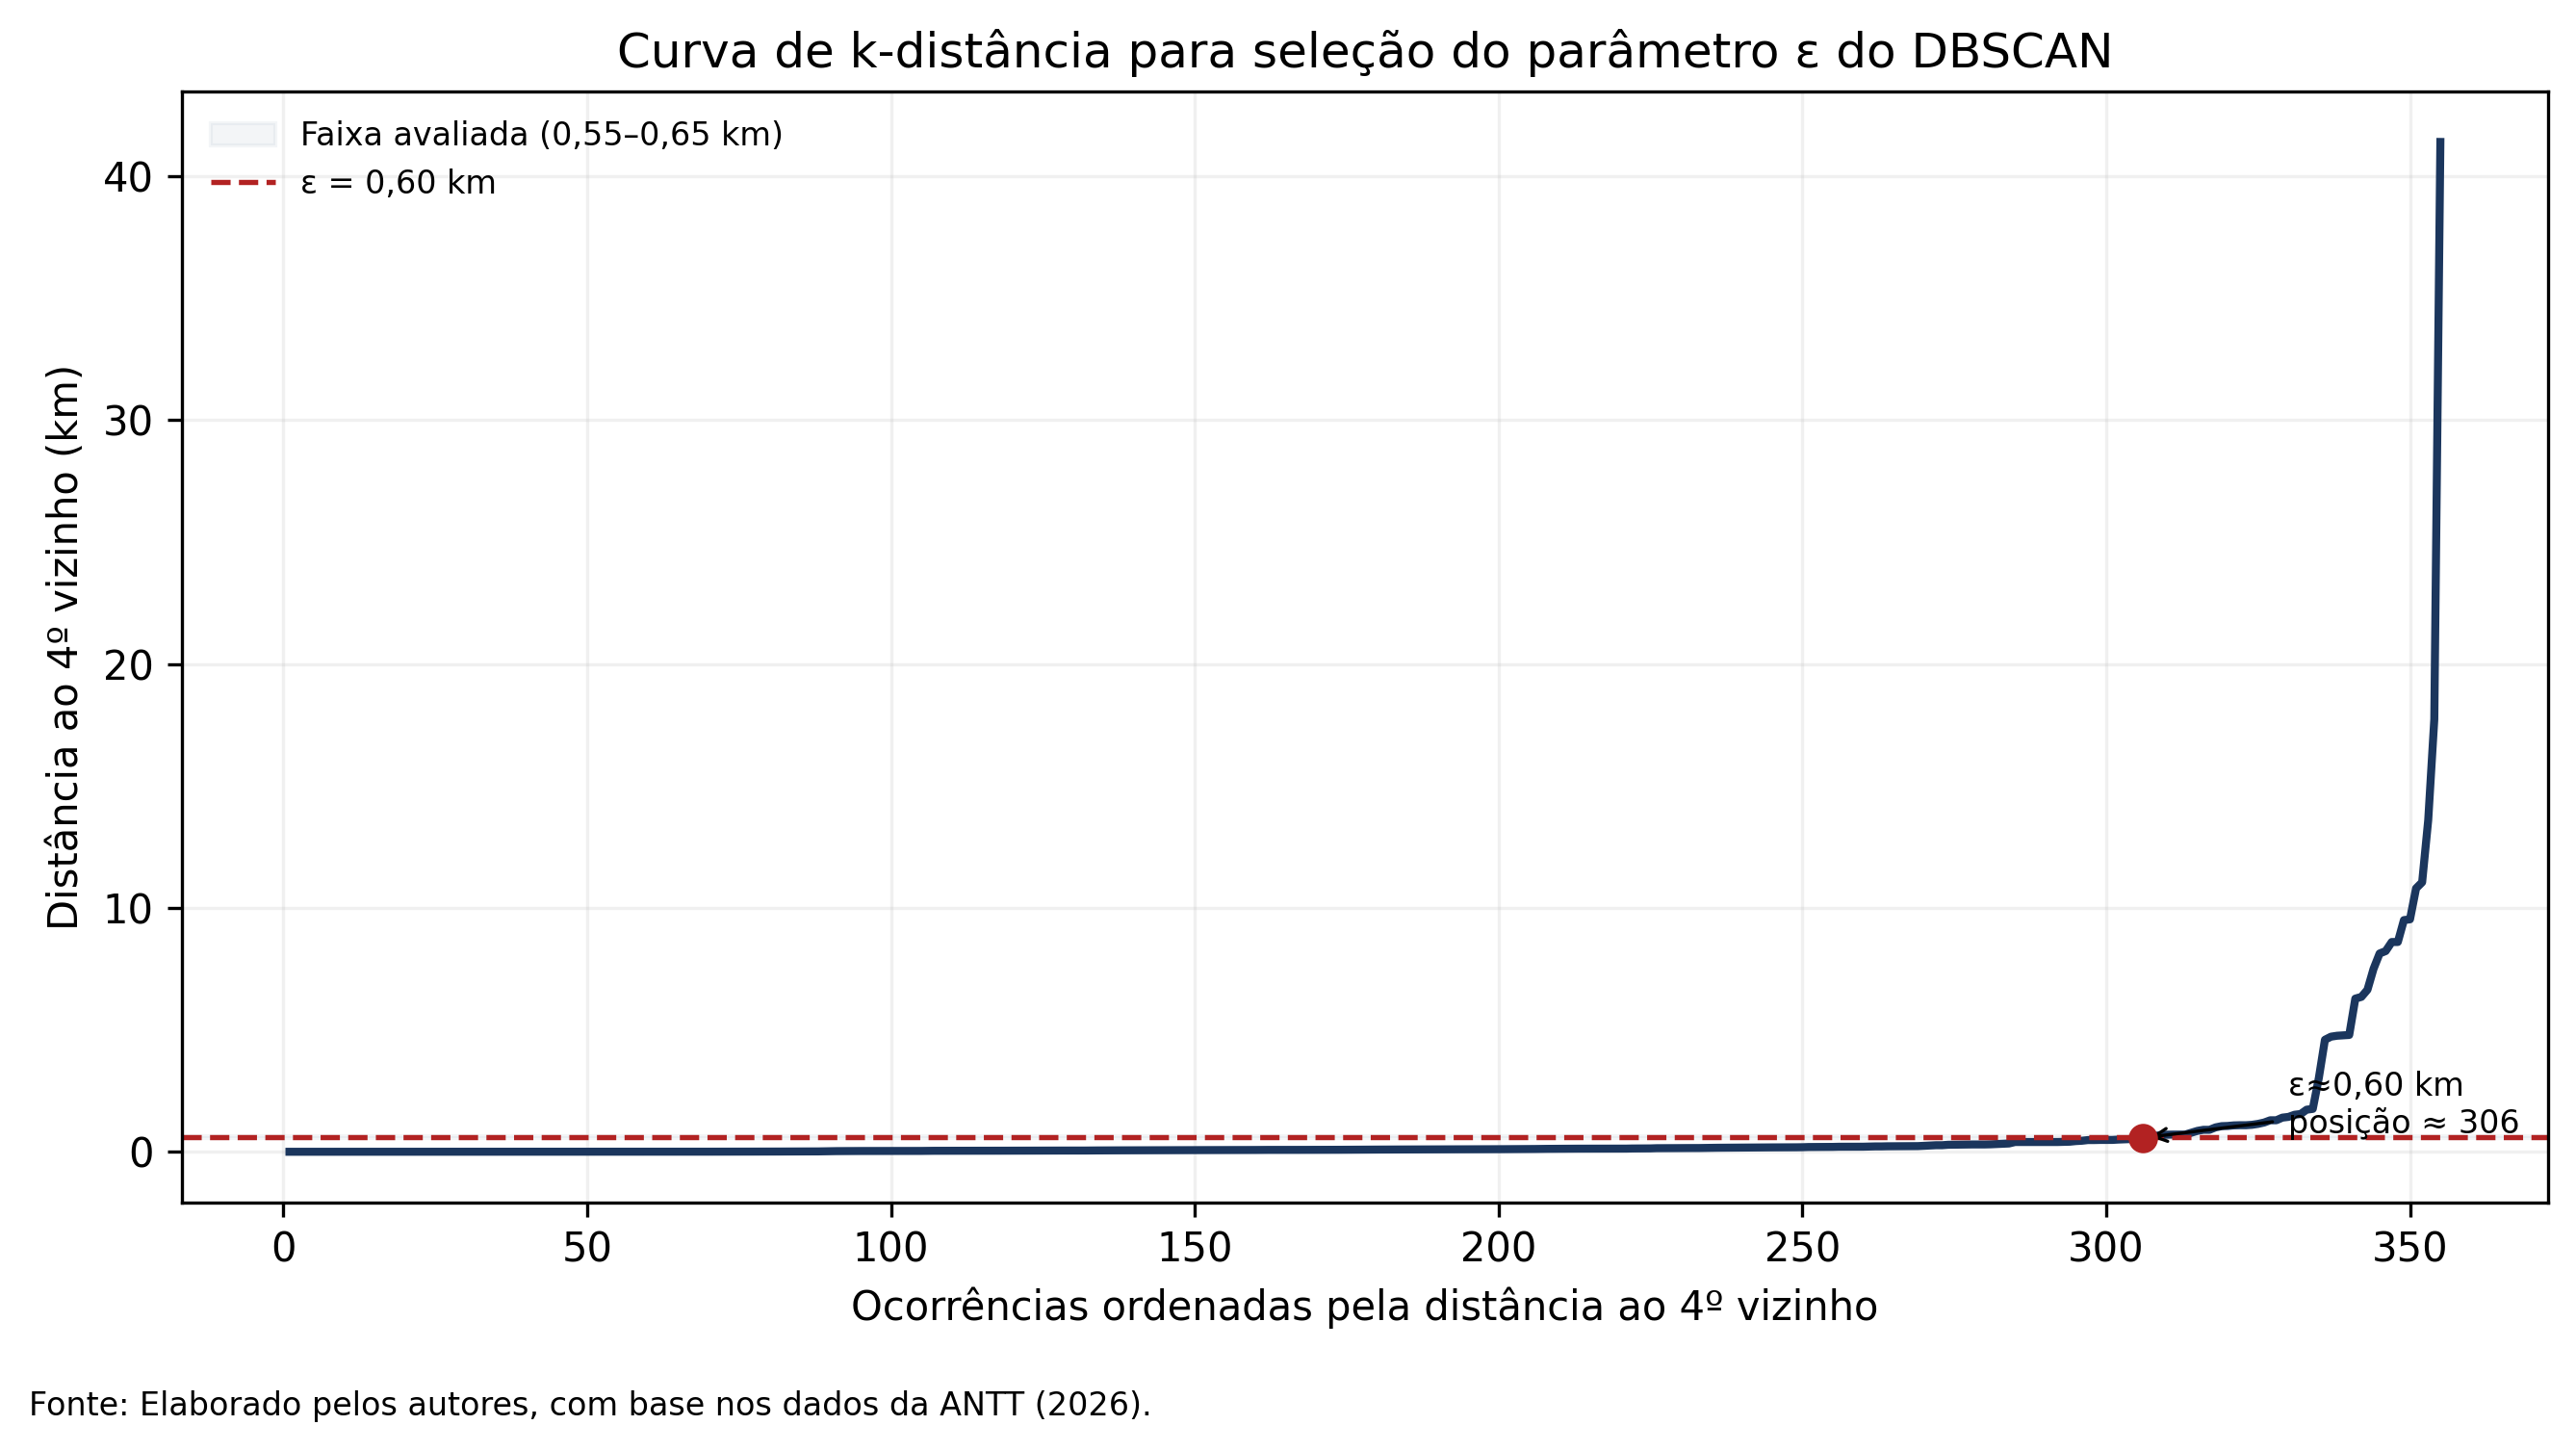

Distância mais próxima de 0,60 km: 0.5670 km | posição 306


In [19]:
# ============================================================
# 14) FIGURA 2 – CURVA DE K-DISTÂNCIA
# ============================================================

def texto_sem_acento(x):
    x = "" if x is None else str(x)
    x = unicodedata.normalize(
        "NFD",
        corrigir_mojibake(x)
    )
    return "".join(
        c for c in x
        if unicodedata.category(c) != "Mn"
    ).casefold()

linha_norm = (
    df_rms_ml["Linha"]
    .astype(str)
    .map(texto_sem_acento)
)

mask_pu = linha_norm.apply(
    lambda s:
        "paranagua" in s
        and "uvaranas" in s
)

df_pu = (
    df_rms_ml.loc[mask_pu]
    .dropna(
        subset=["Quilômetro_Inicial"]
    )
    .copy()
)

if df_pu.empty:
    raise ValueError(
        "A linha Paranaguá–Uvaranas não foi localizada."
    )

print(
    "Ocorrências utilizadas na curva k-distância:",
    len(df_pu)
)

X_pu = (
    df_pu[["Quilômetro_Inicial"]]
    .to_numpy(dtype=float)
)

k = 4

nn = NearestNeighbors(
    n_neighbors=k,
    metric="euclidean"
)

nn.fit(X_pu)

distancias, _ = nn.kneighbors(X_pu)

k_dist = np.sort(
    distancias[:, k - 1]
)

EPS_BASE = 0.60
MIN_SAMPLES_BASE = 4

idx_eps = int(
    np.argmin(
        np.abs(k_dist - EPS_BASE)
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5),
    dpi=300
)

ax.plot(
    np.arange(1, len(k_dist) + 1),
    k_dist,
    linewidth=2,
    color="#1b365d",
)

ax.axhspan(
    0.55,
    0.65,
    alpha=0.12,
    color="#a0aec0",
    label="Faixa avaliada (0,55–0,65 km)",
)

ax.axhline(
    EPS_BASE,
    color="#b22222",
    linestyle="--",
    linewidth=1.3,
    label="ε = 0,60 km",
)

ax.scatter(
    idx_eps + 1,
    k_dist[idx_eps],
    s=40,
    color="#b22222",
    zorder=5,
)

ax.annotate(
    f"ε≈0,60 km\nposição ≈ {idx_eps + 1}",
    xy=(
        idx_eps + 1,
        k_dist[idx_eps]
    ),
    xytext=(
        min(idx_eps + 25, len(k_dist)),
        k_dist[idx_eps] + 0.18
    ),
    arrowprops=dict(
        arrowstyle="->",
        linewidth=0.8,
        color="black"
    ),
    fontsize=8,
)

ax.set_title(
    "Curva de k-distância para seleção do parâmetro ε do DBSCAN"
)
ax.set_xlabel(
    "Ocorrências ordenadas pela distância ao 4º vizinho"
)
ax.set_ylabel(
    "Distância ao 4º vizinho (km)"
)
ax.grid(alpha=0.18)
ax.legend(
    frameon=False,
    fontsize=8
)

fig.text(
    0.01,
    0.01,
    "Fonte: Elaborado pelos autores, com base nos dados da ANTT (2026).",
    fontsize=8,
)

plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.savefig(
    "Figura_2_K_Distancia.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Distância mais próxima de 0,60 km: "
    f"{k_dist[idx_eps]:.4f} km | posição {idx_eps + 1}"
)

## 15. Funções do DBSCAN e resumo dos clusters

**Correspondência com o artigo:** Seções **2.2, 2.3 e 2.4** — métrica linear, definição de hotspot candidato e Score de Severidade.

O DBSCAN é aplicado separadamente para cada linha ferroviária e utiliza somente `Quilômetro_Inicial`. O Score é calculado após a clusterização.

In [20]:
# ============================================================
# 15) FUNÇÕES DBSCAN + RESUMO
# ============================================================

def executar_dbscan_linear(
    df_entrada,
    eps=0.60,
    min_samples=4
):
    resultado = df_entrada.copy()

    resultado["Quilômetro_Inicial"] = pd.to_numeric(
        resultado["Quilômetro_Inicial"],
        errors="coerce"
    )

    resultado = (
        resultado
        .dropna(
            subset=[
                "Linha",
                "Quilômetro_Inicial",
            ]
        )
        .copy()
    )

    resultado["Cluster_DBSCAN"] = "Ruído"

    for linha, grupo in resultado.groupby(
        "Linha",
        dropna=True
    ):
        if len(grupo) < min_samples:
            continue

        X = grupo[
            ["Quilômetro_Inicial"]
        ].to_numpy(dtype=float)

        labels = DBSCAN(
            eps=float(eps),
            min_samples=int(min_samples),
            metric="euclidean"
        ).fit_predict(X)

        rotulos = [
            (
                f"{linha}__C{int(lbl)}"
                if lbl != -1
                else "Ruído"
            )
            for lbl in labels
        ]

        resultado.loc[
            grupo.index,
            "Cluster_DBSCAN"
        ] = rotulos

    return resultado


def resumir_clusters(df_clusterizado):
    agrupados = (
        df_clusterizado[
            df_clusterizado["Cluster_DBSCAN"]
            != "Ruído"
        ]
        .copy()
    )

    if agrupados.empty:
        return pd.DataFrame()

    if "_id_ocorrencia" not in agrupados.columns:
        agrupados["_id_ocorrencia"] = (
            agrupados.index.astype(str)
        )

    resumo = (
        agrupados
        .groupby("Cluster_DBSCAN")
        .agg(
            Linha=("Linha", "first"),
            Municipio_Principal=(
                "Municipio",
                lambda x:
                    x.mode().iloc[0]
                    if not x.mode().empty
                    else "N/I"
            ),
            KM_Min=("Quilômetro_Inicial", "min"),
            KM_Max=("Quilômetro_Inicial", "max"),
            Total_Acidentes=("_id_ocorrencia", "count"),
            Total_Feridos=("N_feridos", "sum"),
            Total_Obitos=("N_obitos", "sum"),
            Abalroamentos=(
                "Natureza_Norm",
                lambda x:
                    int((x == "Abalroamento").sum())
            ),
            Atropelamentos=(
                "Natureza_Norm",
                lambda x:
                    int((x == "Atropelamento").sum())
            ),
            Pct_em_PN=(
                "PN_Norm",
                lambda x:
                    float((x == "Sim").mean() * 100)
            ),
            IDs=(
                "_id_ocorrencia",
                lambda x:
                    frozenset(x.astype(str))
            ),
        )
        .reset_index()
    )

    resumo["Extensao_KM"] = (
        resumo["KM_Max"]
        - resumo["KM_Min"]
    ).round(3)

    resumo["KM_Centroide"] = (
        (
            resumo["KM_Min"]
            + resumo["KM_Max"]
        ) / 2
    ).round(3)

    resumo["Score_5_2_1"] = (
        5 * resumo["Total_Obitos"]
        + 2 * resumo["Total_Feridos"]
        + resumo["Total_Acidentes"]
    )

    resumo = (
        resumo
        .sort_values(
            [
                "Score_5_2_1",
                "Total_Acidentes",
            ],
            ascending=[
                False,
                False,
            ]
        )
        .reset_index(drop=True)
    )

    resumo["Rank_5_2_1"] = np.arange(
        1,
        len(resumo) + 1
    )

    return resumo

print("✓ Funções centrais definidas.")

✓ Funções centrais definidas.


## 16. Configuração de referência do DBSCAN

**Correspondência com o artigo:** Seções **2.3 e 3.4** — baseline `eps = 0,60 km` e `min_samples = 4`.

Baseline: `eps = 0,60 km` e `min_samples = 4`.

In [21]:
# ============================================================
# 16) DBSCAN BASELINE
# ============================================================

EPS_BASE = 0.60
MIN_SAMPLES_BASE = 4

df_rms_baseline = executar_dbscan_linear(
    df_rms_ml,
    eps=EPS_BASE,
    min_samples=MIN_SAMPLES_BASE
)

resumo_baseline = resumir_clusters(
    df_rms_baseline
)

n_clusters_base = len(resumo_baseline)

n_ruido_base = int(
    (
        df_rms_baseline["Cluster_DBSCAN"]
        == "Ruído"
    ).sum()
)

n_agrupados_base = int(
    (
        df_rms_baseline["Cluster_DBSCAN"]
        != "Ruído"
    ).sum()
)

print(
    f"Configuração de referência: "
    f"eps={EPS_BASE:.2f} km; "
    f"min_samples={MIN_SAMPLES_BASE}"
)
print(
    "Clusters candidatos a hotspot:",
    n_clusters_base
)
print(
    "Ocorrências agrupadas:",
    n_agrupados_base
)
print(
    "Ocorrências classificadas como ruído:",
    n_ruido_base
)

if n_clusters_base == 60:
    print("✓ Baseline compatível com o artigo: 60 clusters.")
else:
    print(
        "⚠ O artigo reporta 60 clusters; "
        f"a execução atual produziu {n_clusters_base}."
    )

display(
    resumo_baseline[
        [
            "Rank_5_2_1",
            "Municipio_Principal",
            "Linha",
            "KM_Centroide",
            "Extensao_KM",
            "Total_Acidentes",
            "Total_Feridos",
            "Total_Obitos",
            "Score_5_2_1",
            "Pct_em_PN",
        ]
    ].head(20)
)

Configuração de referência: eps=0.60 km; min_samples=4
Clusters candidatos a hotspot: 59
Ocorrências agrupadas: 683
Ocorrências classificadas como ruído: 401
⚠ O artigo reporta 60 clusters; a execução atual produziu 59.


,Rank_5_2_1,Municipio_Principal,Linha,KM_Centroide,Extensao_KM,Total_Acidentes,Total_Feridos,Total_Obitos,Score_5_2_1,Pct_em_PN
0,1,Curitiba,Paranaguá - Uvaranas,104.575,5.150,83,37.0,16.0,237.0,55.421687
1,2,Paranagua,Paranaguá - Uvaranas,3.847,3.074,78,7.0,3.0,107.0,84.615385
2,3,Jandaia do Sul,Ourinhos - Cianorte,289.296,1.207,7,26.0,6.0,89.0,100.000000
3,4,Arapongas,Ourinhos - Cianorte,249.850,4.207,33,16.0,2.0,75.0,90.909091
4,5,Pinhais,Paranaguá - Uvaranas,99.980,2.040,23,16.0,4.0,75.0,47.826087
5,6,Curitiba,Paranaguá - Uvaranas,117.950,2.900,25,14.0,4.0,73.0,40.000000
6,7,Mandaguari,Ourinhos - Cianorte,300.013,3.650,24,10.0,3.0,59.0,87.500000
7,8,Curitiba,Paranaguá - Uvaranas,108.638,1.277,21,7.0,3.0,50.0,61.904762
8,9,Sarandi,Ourinhos - Cianorte,324.346,2.094,18,11.0,1.0,45.0,66.666667
9,10,Rolandia,Ourinhos - Cianorte,237.600,1.800,16,2.0,4.0,40.0,87.500000


## 17. Identificação dos hotspots no corredor — Figura 3

**Correspondência com o artigo:** **Seção 3.3** e **Figura 3**. A representação cartográfica é apenas ilustrativa; a clusterização permanece baseada em `Linha + Quilômetro_Inicial`.

A representação é aproximada e usada exclusivamente como apoio visual. Ela não participa da formação dos clusters.

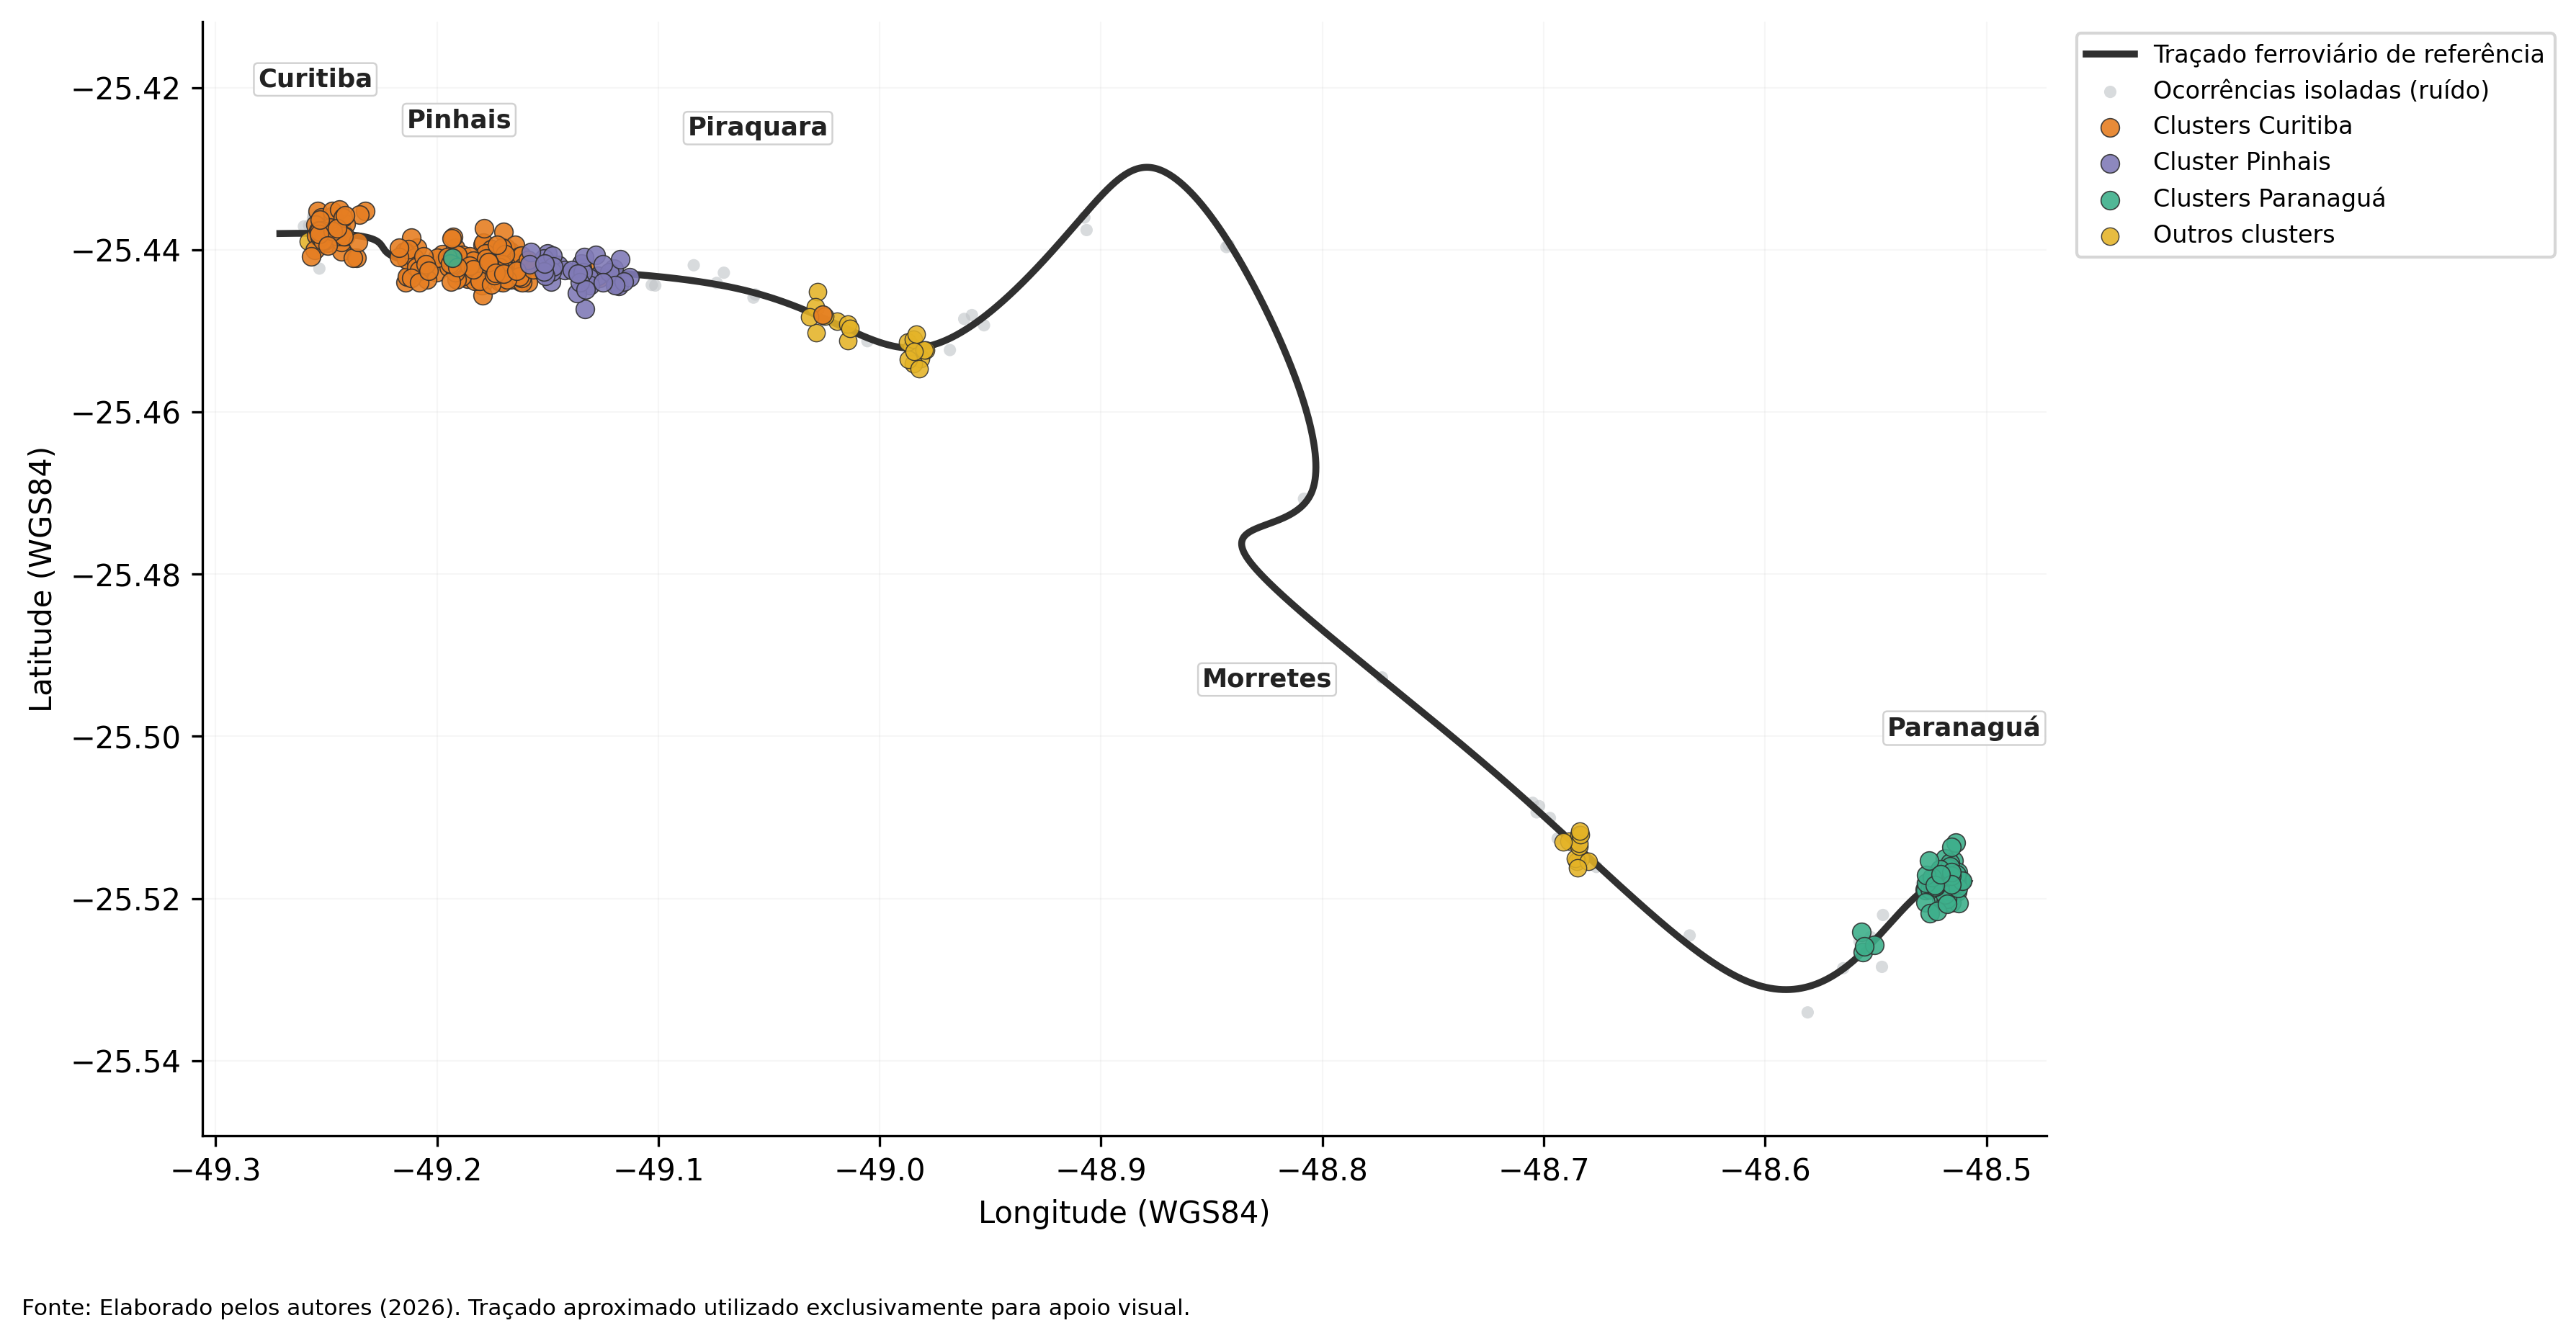

In [22]:
# ============================================================
# 17) FIGURA 3 – MAPA ESQUEMÁTICO CURITIBA–PARANAGUÁ
# ============================================================

waypoints_rail = np.array([
    [-49.2710, -25.4380],
    [-49.2250, -25.4395],
    [-49.1920, -25.4420],
    [-49.0610, -25.4450],
    [-48.9800, -25.4520],
    [-48.9150, -25.4380],
    [-48.8750, -25.4300],
    [-48.8300, -25.4450],
    [-48.8050, -25.4700],
    [-48.8340, -25.4780],
    [-48.7200, -25.5050],
    [-48.6100, -25.5300],
    [-48.5500, -25.5250],
    [-48.5080, -25.5180],
])

t_waypoints = np.linspace(
    0,
    1,
    len(waypoints_rail)
)
t_rail = np.linspace(
    0,
    1,
    2500
)

rail_lon = make_interp_spline(
    t_waypoints,
    waypoints_rail[:, 0],
    k=3
)(t_rail)

rail_lat = make_interp_spline(
    t_waypoints,
    waypoints_rail[:, 1],
    k=3
)(t_rail)

lat_media = np.mean(rail_lat)

dx = (
    np.diff(rail_lon)
    * np.cos(np.deg2rad(lat_media))
)
dy = np.diff(rail_lat)

segmentos = np.sqrt(
    dx**2 + dy**2
)

dist_acumulada = np.concatenate(
    [
        [0],
        np.cumsum(segmentos),
    ]
)

frac_tracado = (
    dist_acumulada
    / dist_acumulada[-1]
)

linha_norm = (
    df_rms_baseline["Linha"]
    .astype(str)
    .map(texto_sem_acento)
)

mask_pu = linha_norm.apply(
    lambda s:
        "paranagua" in s
        and "uvaranas" in s
)

df_mapa = (
    df_rms_baseline.loc[mask_pu]
    .copy()
)

if df_mapa.empty:
    raise ValueError(
        "Nenhuma ocorrência da linha Paranaguá–Uvaranas "
        "foi localizada para a Figura 3."
    )

ancoras_km = np.array([
    [0.0,   1.000],
    [15.0,  0.940],
    [38.0,  0.790],
    [60.0,  0.620],
    [80.0,  0.430],
    [90.0,  0.300],
    [98.0,  0.180],
    [105.0, 0.115],
    [110.0, 0.080],
    [120.0, 0.020],
])

interp_frac = interp1d(
    ancoras_km[:, 0],
    ancoras_km[:, 1],
    kind="linear",
    bounds_error=False,
    fill_value=(
        ancoras_km[0, 1],
        ancoras_km[-1, 1],
    )
)

def km_para_trilho(km):
    frac_desejada = float(
        interp_frac(float(km))
    )

    indice = int(
        np.argmin(
            np.abs(
                frac_tracado
                - frac_desejada
            )
        )
    )

    return (
        rail_lat[indice],
        rail_lon[indice],
    )

coords = (
    df_mapa["Quilômetro_Inicial"]
    .apply(km_para_trilho)
)

df_mapa["Latitude_trilho"] = (
    coords.apply(lambda x: x[0])
)
df_mapa["Longitude_trilho"] = (
    coords.apply(lambda x: x[1])
)

rng = np.random.default_rng(2026)

df_mapa["Longitude_plot"] = (
    df_mapa["Longitude_trilho"]
    + rng.normal(
        0,
        0.0022,
        len(df_mapa)
    )
)

df_mapa["Latitude_plot"] = (
    df_mapa["Latitude_trilho"]
    + rng.normal(
        0,
        0.0015,
        len(df_mapa)
    )
)

municipio_norm = (
    df_mapa["Municipio"]
    .astype(str)
    .map(texto_sem_acento)
)

eh_ruido = (
    df_mapa["Cluster_DBSCAN"]
    .eq("Ruído")
)

eh_curitiba = (
    ~eh_ruido
    & municipio_norm.str.contains(
        "curitiba",
        na=False
    )
)

eh_pinhais = (
    ~eh_ruido
    & municipio_norm.str.contains(
        "pinhais",
        na=False
    )
)

eh_paranagua = (
    ~eh_ruido
    & municipio_norm.str.contains(
        "paranagua",
        na=False
    )
)

eh_outros = (
    ~eh_ruido
    & ~(
        eh_curitiba
        | eh_pinhais
        | eh_paranagua
    )
)

fig, ax = plt.subplots(
    figsize=(12, 6.2),
    dpi=300
)

ax.plot(
    rail_lon,
    rail_lat,
    color="#303030",
    linewidth=2.3,
    zorder=2,
    label="Traçado ferroviário de referência",
)

ax.scatter(
    df_mapa.loc[eh_ruido, "Longitude_plot"],
    df_mapa.loc[eh_ruido, "Latitude_plot"],
    s=17,
    color="#BFC3C7",
    alpha=0.60,
    edgecolors="none",
    zorder=1,
    label="Ocorrências isoladas (ruído)",
)

ax.scatter(
    df_mapa.loc[eh_curitiba, "Longitude_plot"],
    df_mapa.loc[eh_curitiba, "Latitude_plot"],
    s=38,
    color="#E67E22",
    alpha=0.90,
    edgecolors="#303030",
    linewidth=0.4,
    zorder=4,
    label="Clusters Curitiba",
)

ax.scatter(
    df_mapa.loc[eh_pinhais, "Longitude_plot"],
    df_mapa.loc[eh_pinhais, "Latitude_plot"],
    s=38,
    color="#817BB7",
    alpha=0.90,
    edgecolors="#303030",
    linewidth=0.4,
    zorder=4,
    label="Cluster Pinhais",
)

ax.scatter(
    df_mapa.loc[eh_paranagua, "Longitude_plot"],
    df_mapa.loc[eh_paranagua, "Latitude_plot"],
    s=38,
    color="#3EAF8B",
    alpha=0.90,
    edgecolors="#303030",
    linewidth=0.4,
    zorder=4,
    label="Clusters Paranaguá",
)

ax.scatter(
    df_mapa.loc[eh_outros, "Longitude_plot"],
    df_mapa.loc[eh_outros, "Latitude_plot"],
    s=34,
    color="#E4B326",
    alpha=0.88,
    edgecolors="#303030",
    linewidth=0.35,
    zorder=3,
    label="Outros clusters",
)

referencias = {
    "Curitiba": (-49.255, -25.419),
    "Pinhais": (-49.190, -25.424),
    "Piraquara": (-49.055, -25.425),
    "Morretes": (-48.825, -25.493),
    "Paranaguá": (-48.510, -25.499),
}

for cidade, (lon, lat) in referencias.items():
    ax.text(
        lon,
        lat,
        cidade,
        fontsize=8.5,
        fontweight="bold",
        ha="center",
        va="center",
        color="#222222",
        bbox=dict(
            boxstyle="round,pad=0.16",
            facecolor="white",
            edgecolor="#CFCFCF",
            linewidth=0.6,
            alpha=0.95,
        ),
        zorder=6,
    )

ax.set_xlabel("Longitude (WGS84)")
ax.set_ylabel("Latitude (WGS84)")
ax.grid(alpha=0.10, linewidth=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(
    rail_lon.min() - 0.035,
    rail_lon.max() + 0.035
)
ax.set_ylim(
    rail_lat.min() - 0.018,
    rail_lat.max() + 0.018
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1.00),
    fontsize=8,
    frameon=True,
)

fig.text(
    0.01,
    0.01,
    "Fonte: Elaborado pelos autores (2026). "
    "Traçado aproximado utilizado exclusivamente para apoio visual.",
    fontsize=7.5,
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

plt.savefig(
    "Figura_3_Hotspots_Curitiba_Paranagua.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

## 18. Sensibilidade dos hiperparâmetros

**Correspondência com o artigo:** **Seção 3.4** — grade `eps ∈ {0,55; 0,60; 0,65}` × `min_samples ∈ {3; 4; 5}`.

Grade: `eps ∈ {0,55; 0,60; 0,65}` e `min_samples ∈ {3; 4; 5}`.

In [23]:
# ============================================================
# 15) SENSIBILIDADE DO DBSCAN
# ============================================================

EPS_TESTE = [
    0.55,
    0.60,
    0.65,
]

MIN_SAMPLES_TESTE = [
    3,
    4,
    5,
]

cenarios = {}
resultados_sensibilidade = []

for eps in EPS_TESTE:
    for ms in MIN_SAMPLES_TESTE:
        df_c = executar_dbscan_linear(
            df_rms_ml,
            eps=eps,
            min_samples=ms
        )

        resumo_c = resumir_clusters(
            df_c
        )

        cenarios[(eps, ms)] = {
            "dados": df_c,
            "resumo": resumo_c,
        }

        n_clusters = len(resumo_c)
        n_agrupados = int(
            (
                df_c["Cluster_DBSCAN"]
                != "Ruído"
            ).sum()
        )
        n_ruido = int(
            (
                df_c["Cluster_DBSCAN"]
                == "Ruído"
            ).sum()
        )

        resultados_sensibilidade.append({
            "eps_km": eps,
            "min_samples": ms,
            "n_clusters": n_clusters,
            "n_agrupados": n_agrupados,
            "n_ruido": n_ruido,
            "pct_agrupados": (
                100 * n_agrupados / len(df_c)
                if len(df_c)
                else np.nan
            ),
        })

sensibilidade_dbscan = pd.DataFrame(
    resultados_sensibilidade
)

display(
    sensibilidade_dbscan
    .sort_values(
        [
            "eps_km",
            "min_samples",
        ]
    )
    .reset_index(drop=True)
)

,eps_km,min_samples,n_clusters,n_agrupados,n_ruido,pct_agrupados
0,0.55,3,78,729,355,67.250923
1,0.55,4,61,669,415,61.715867
2,0.55,5,48,593,491,54.704797
3,0.60,3,74,735,349,67.804428
4,0.60,4,59,683,401,63.007380
5,0.60,5,48,612,472,56.457565
6,0.65,3,70,744,340,68.634686
7,0.65,4,57,697,387,64.298893
8,0.65,5,47,631,453,58.210332


## 19. Pareamento de clusters e estabilidade do ranking

**Correspondência com o artigo:** **Seções 2.5 e 3.4** — maior sobreposição de ocorrências na mesma linha, Jaccard como desempate e Spearman sobre as posições do ranking.

Pareamento por mesma linha, maior sobreposição de IDs e Jaccard como desempate. Ausência de sobreposição recebe rank `N + 1`.

In [24]:
# ============================================================
# 19) SPEARMAN REAL ENTRE RANKINGS
# ============================================================

def parear_e_spearman(
    resumo_base,
    resumo_alt
):
    if resumo_base.empty or resumo_alt.empty:
        return np.nan, pd.DataFrame()

    base = resumo_base.copy()
    alt = resumo_alt.copy()

    colunas_necessarias = [
        "Cluster_DBSCAN",
        "Linha",
        "Rank_5_2_1",
        "IDs",
    ]

    for coluna in colunas_necessarias:
        if coluna not in base.columns:
            raise KeyError(
                f"A coluna {coluna!r} não existe no baseline."
            )
        if coluna not in alt.columns:
            raise KeyError(
                f"A coluna {coluna!r} não existe no cenário alternativo."
            )

    alt_rank = dict(
        zip(
            alt["Cluster_DBSCAN"],
            alt["Rank_5_2_1"],
        )
    )

    registros = []

    for _, row_b in base.iterrows():
        candidatos = alt[
            alt["Linha"] == row_b["Linha"]
        ]

        melhor_cluster = None
        maior_intersecao = 0
        melhor_jaccard = 0.0

        ids_b = set(
            row_b["IDs"]
        )

        for _, row_a in candidatos.iterrows():
            ids_a = set(
                row_a["IDs"]
            )

            intersecao = len(
                ids_b & ids_a
            )

            uniao = len(
                ids_b | ids_a
            )

            jaccard = (
                intersecao / uniao
                if uniao
                else 0.0
            )

            if (
                intersecao > maior_intersecao
                or (
                    intersecao == maior_intersecao
                    and jaccard > melhor_jaccard
                )
            ):
                maior_intersecao = intersecao
                melhor_jaccard = jaccard
                melhor_cluster = row_a[
                    "Cluster_DBSCAN"
                ]

        if (
            melhor_cluster is None
            or maior_intersecao == 0
        ):
            rank_alt = len(alt) + 1
            melhor_cluster = "Ausente"
        else:
            rank_alt = int(
                alt_rank[melhor_cluster]
            )

        registros.append({
            "Cluster_Baseline": row_b["Cluster_DBSCAN"],
            "Linha": row_b["Linha"],
            "Rank_Baseline": int(row_b["Rank_5_2_1"]),
            "Cluster_Alternativo": melhor_cluster,
            "Rank_Alternativo": int(rank_alt),
            "Ocorrencias_Compartilhadas": int(maior_intersecao),
            "Jaccard": float(melhor_jaccard),
        })

    pareamento = pd.DataFrame(
        registros
    )

    if (
        pareamento["Rank_Baseline"].nunique() < 2
        or pareamento["Rank_Alternativo"].nunique() < 2
    ):
        rho = np.nan
    else:
        rho, _ = spearmanr(
            pareamento["Rank_Baseline"],
            pareamento["Rank_Alternativo"],
        )

    return (
        float(rho)
        if pd.notna(rho)
        else np.nan
    ), pareamento


resumo_base_ref = (
    cenarios[(0.60, 4)]["resumo"]
)

resultados_spearman = []
pareamentos = {}

for eps in EPS_TESTE:
    for ms in MIN_SAMPLES_TESTE:
        resumo_alt = (
            cenarios[(eps, ms)]["resumo"]
        )

        rho, tabela_pareamento = (
            parear_e_spearman(
                resumo_base_ref,
                resumo_alt
            )
        )

        pareamentos[(eps, ms)] = (
            tabela_pareamento
        )

        resultados_spearman.append({
            "eps_km": eps,
            "min_samples": ms,
            "spearman_rho": rho,
        })

spearman_df = pd.DataFrame(
    resultados_spearman
)

display(
    spearman_df
    .sort_values(
        [
            "eps_km",
            "min_samples",
        ]
    )
    .reset_index(drop=True)
)

,eps_km,min_samples,spearman_rho
0,0.55,3,0.993513
1,0.55,4,0.990473
2,0.55,5,0.901975
3,0.60,3,0.999123
4,0.60,4,1.000000
5,0.60,5,0.929386
6,0.65,3,0.919120
7,0.65,4,0.945789
8,0.65,5,0.916654


## 20. Sensibilidade do DBSCAN e estabilidade do ranking — Figura 4

**Correspondência com o artigo:** **Seção 3.4** e **Figura 4**.

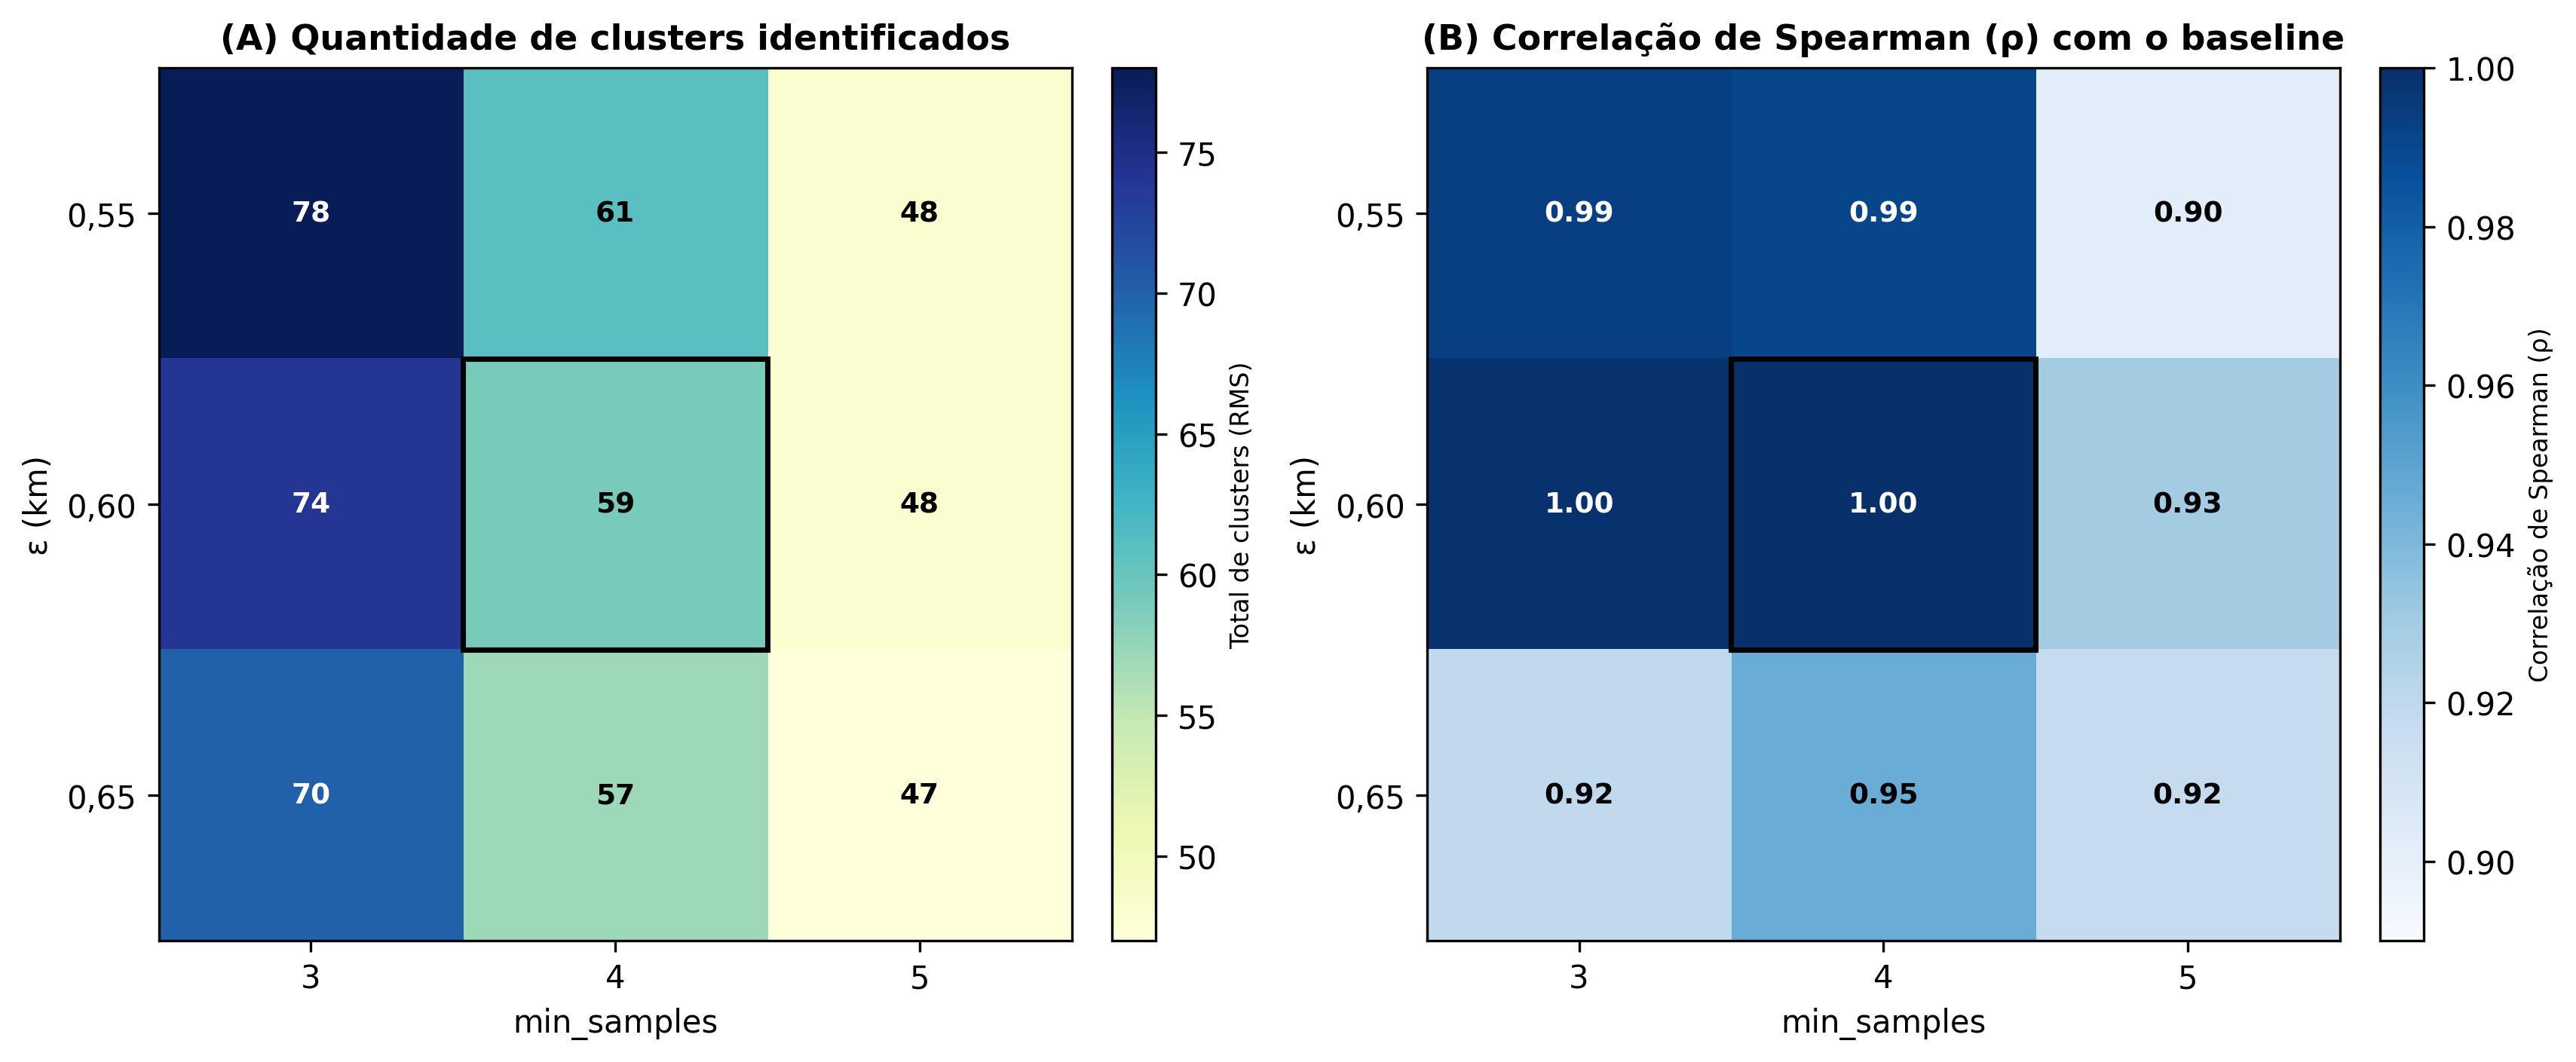

Fonte: Elaborado pelos autores, com base nos dados da ANTT (2026).


In [25]:
# ============================================================
# 20) FIGURA 4 – SENSIBILIDADE + SPEARMAN
# ============================================================

matriz_clusters = (
    sensibilidade_dbscan
    .pivot(
        index="eps_km",
        columns="min_samples",
        values="n_clusters",
    )
    .sort_index()
)

matriz_spearman = (
    spearman_df
    .pivot(
        index="eps_km",
        columns="min_samples",
        values="spearman_rho",
    )
    .sort_index()
)

matriz_clusters = matriz_clusters[
    sorted(matriz_clusters.columns)
]
matriz_spearman = matriz_spearman[
    sorted(matriz_spearman.columns)
]

def adicionar_valores_heatmap(
    ax,
    matriz,
    im,
    formato
):
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            valor = matriz.iloc[i, j]

            if pd.isna(valor):
                continue

            rgba = im.cmap(
                im.norm(valor)
            )
            r, g, b, _ = rgba

            luminancia = (
                0.299 * r
                + 0.587 * g
                + 0.114 * b
            )

            cor = (
                "black"
                if luminancia > 0.60
                else "white"
            )

            ax.text(
                j,
                i,
                formato.format(valor),
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold",
                color=cor,
            )

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 4.8),
    dpi=300,
)

im1 = axes[0].imshow(
    matriz_clusters.values,
    cmap="YlGnBu",
    aspect="auto",
)

axes[0].set_title(
    "(A) Quantidade de clusters identificados",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("min_samples")
axes[0].set_ylabel("ε (km)")
axes[0].set_xticks(
    np.arange(len(matriz_clusters.columns))
)
axes[0].set_xticklabels(
    matriz_clusters.columns
)
axes[0].set_yticks(
    np.arange(len(matriz_clusters.index))
)
axes[0].set_yticklabels(
    [
        f"{x:.2f}".replace(".", ",")
        for x in matriz_clusters.index
    ]
)

adicionar_valores_heatmap(
    axes[0],
    matriz_clusters,
    im1,
    "{:.0f}",
)

cbar1 = fig.colorbar(
    im1,
    ax=axes[0],
    fraction=0.046,
    pad=0.04,
)
cbar1.set_label(
    "Total de clusters (RMS)",
    fontsize=8
)

rho_min = (
    matriz_spearman
    .min()
    .min()
)

if pd.isna(rho_min):
    rho_min = 0.0

vmin_spearman = max(
    0.0,
    np.floor(rho_min * 100) / 100 - 0.01,
)

im2 = axes[1].imshow(
    matriz_spearman.values,
    cmap="Blues",
    aspect="auto",
    vmin=vmin_spearman,
    vmax=1.00,
)

axes[1].set_title(
    "(B) Correlação de Spearman (ρ) com o baseline",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("min_samples")
axes[1].set_ylabel("ε (km)")
axes[1].set_xticks(
    np.arange(len(matriz_spearman.columns))
)
axes[1].set_xticklabels(
    matriz_spearman.columns
)
axes[1].set_yticks(
    np.arange(len(matriz_spearman.index))
)
axes[1].set_yticklabels(
    [
        f"{x:.2f}".replace(".", ",")
        for x in matriz_spearman.index
    ]
)

adicionar_valores_heatmap(
    axes[1],
    matriz_spearman,
    im2,
    "{:.2f}",
)

cbar2 = fig.colorbar(
    im2,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
)
cbar2.set_label(
    "Correlação de Spearman (ρ)",
    fontsize=8
)

linha_base = list(
    matriz_clusters.index
).index(0.60)

coluna_base = list(
    matriz_clusters.columns
).index(4)

for ax in axes:
    ax.add_patch(
        plt.Rectangle(
            (
                coluna_base - 0.5,
                linha_base - 0.5,
            ),
            1,
            1,
            fill=False,
            edgecolor="black",
            linewidth=1.7,
        )
    )

plt.tight_layout()

plt.savefig(
    "Figura_4_Sensibilidade_DBSCAN.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Fonte: Elaborado pelos autores, "
    "com base nos dados da ANTT (2026)."
)

## 21. Sensibilidade do Score de Severidade

**Correspondência com o artigo:** **Seção 3.5** — comparação dos esquemas 5:2:1, 10:3:1 e 5:1:1.

Comparação dos esquemas 5:2:1, 10:3:1 e 5:1:1 sobre os mesmos clusters baseline.

In [26]:
# ============================================================
# 18) SCORES ALTERNATIVOS E RANKINGS
# ============================================================

resumo_scores = (
    resumo_baseline.copy()
)

resumo_scores["Score_5_2_1"] = (
    5 * resumo_scores["Total_Obitos"]
    + 2 * resumo_scores["Total_Feridos"]
    + resumo_scores["Total_Acidentes"]
)

resumo_scores["Score_10_3_1"] = (
    10 * resumo_scores["Total_Obitos"]
    + 3 * resumo_scores["Total_Feridos"]
    + resumo_scores["Total_Acidentes"]
)

resumo_scores["Score_5_1_1"] = (
    5 * resumo_scores["Total_Obitos"]
    + resumo_scores["Total_Feridos"]
    + resumo_scores["Total_Acidentes"]
)

resumo_scores["Rank_5_2_1"] = (
    resumo_scores["Score_5_2_1"]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

resumo_scores["Rank_10_3_1"] = (
    resumo_scores["Score_10_3_1"]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

resumo_scores["Rank_5_1_1"] = (
    resumo_scores["Score_5_1_1"]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

top10_scores = (
    resumo_scores
    .sort_values(
        [
            "Rank_5_2_1",
            "Score_5_2_1",
        ]
    )
    .head(10)
    .copy()
)

display(
    top10_scores[
        [
            "Municipio_Principal",
            "KM_Centroide",
            "Score_5_2_1",
            "Score_10_3_1",
            "Score_5_1_1",
            "Rank_5_2_1",
            "Rank_10_3_1",
            "Rank_5_1_1",
        ]
    ]
)

,Municipio_Principal,KM_Centroide,Score_5_2_1,Score_10_3_1,Score_5_1_1,Rank_5_2_1,Rank_10_3_1,Rank_5_1_1
0,Curitiba,104.575,237.0,354.0,200.0,1,1,1
1,Paranagua,3.847,107.0,129.0,100.0,2,3,2
2,Jandaia do Sul,289.296,89.0,145.0,63.0,3,2,3
3,Arapongas,249.850,75.0,101.0,59.0,4,6,4
4,Pinhais,99.980,75.0,111.0,59.0,4,4,4
5,Curitiba,117.950,73.0,107.0,59.0,6,5,4
6,Mandaguari,300.013,59.0,84.0,49.0,7,7,7
7,Curitiba,108.638,50.0,72.0,43.0,8,8,8
8,Sarandi,324.346,45.0,61.0,34.0,9,11,11
9,Rolandia,237.600,40.0,62.0,38.0,10,10,9


## 22. Perfil dos dez hotspots prioritários — Figura 6

**Correspondência com o artigo:** **Seção 3.6 – Natureza dos sinistros e ocorrência em Passagens em Nível** e **Figura 6**.

Painel (A): composição percentual por natureza, com frequências absolutas dentro das barras.  
Painel (B): proporção de ocorrências em Passagens em Nível.

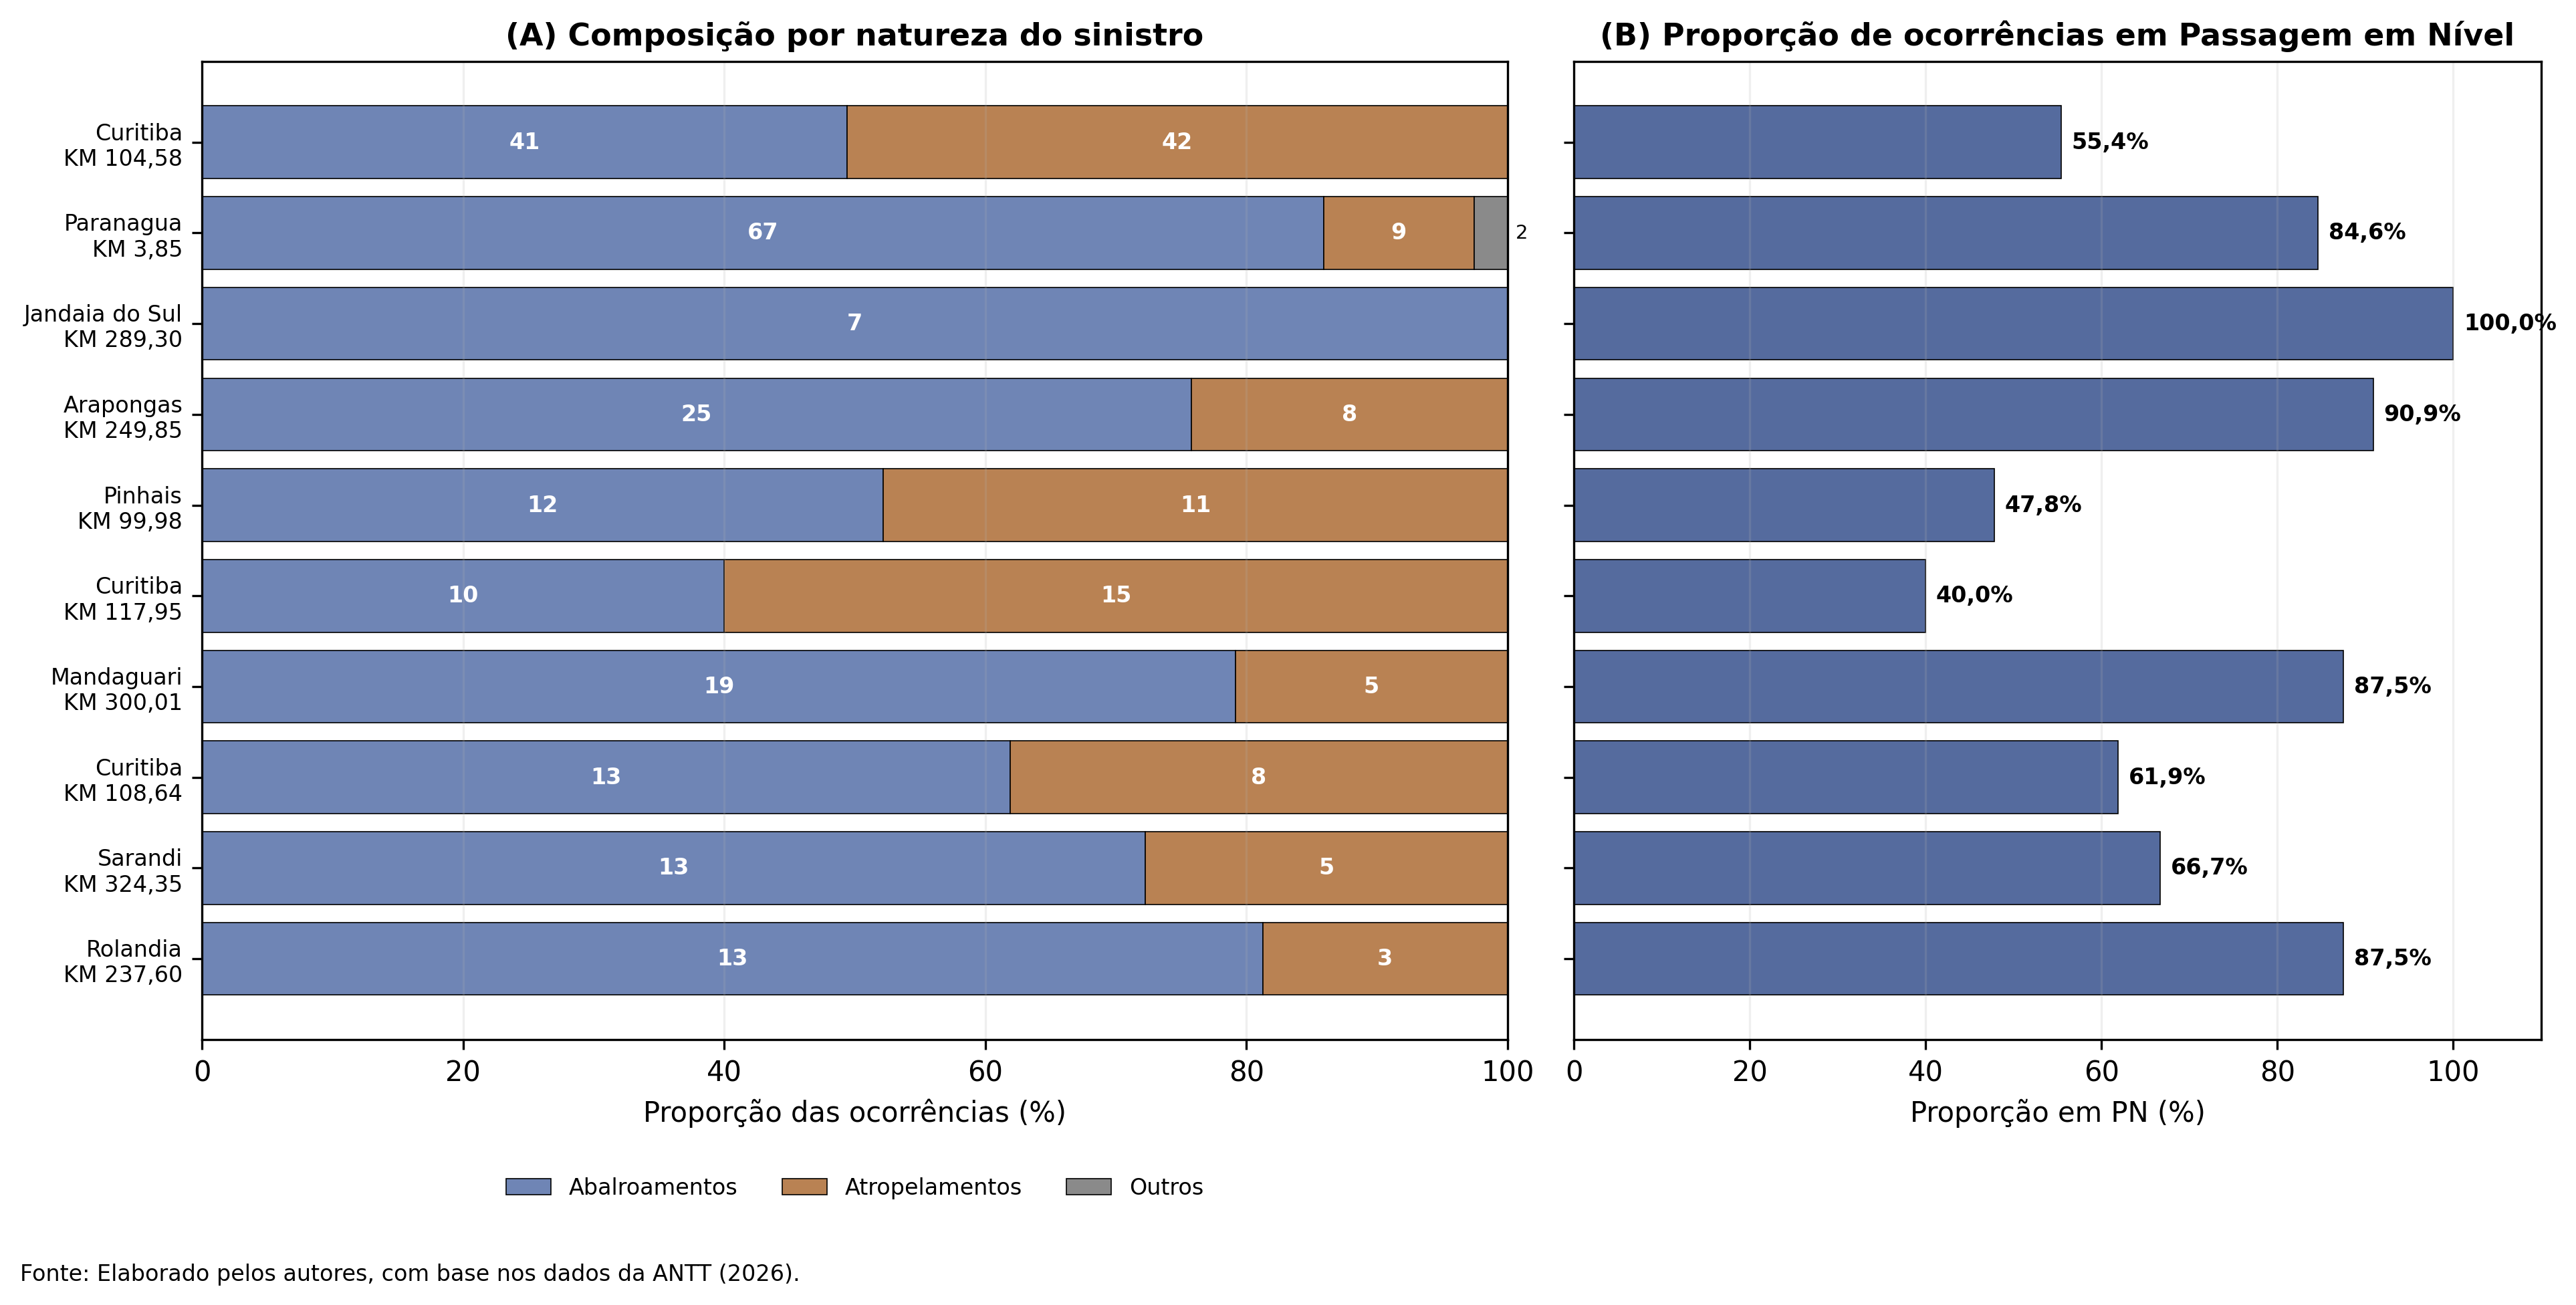

In [27]:
# ============================================================
# 23) FIGURA 6 – NATUREZA DOS SINISTROS + PN
# ============================================================

top10 = (
    resumo_baseline
    .sort_values("Rank_5_2_1")
    .head(10)
    .copy()
)

clusters_top10 = (
    top10["Cluster_DBSCAN"]
    .tolist()
)

df_top10 = (
    df_rms_baseline[
        df_rms_baseline["Cluster_DBSCAN"]
        .isin(clusters_top10)
    ]
    .copy()
)

df_top10["Natureza_Categoria"] = np.where(
    df_top10["Natureza_Norm"].eq("Abalroamento"),
    "Abalroamentos",
    np.where(
        df_top10["Natureza_Norm"].eq("Atropelamento"),
        "Atropelamentos",
        "Outros",
    ),
)

natureza_contagem = (
    df_top10
    .groupby(
        [
            "Cluster_DBSCAN",
            "Natureza_Categoria",
        ]
    )
    .size()
    .unstack(fill_value=0)
)

for categoria in [
    "Abalroamentos",
    "Atropelamentos",
    "Outros",
]:
    if categoria not in natureza_contagem.columns:
        natureza_contagem[categoria] = 0

natureza_contagem = (
    natureza_contagem[
        [
            "Abalroamentos",
            "Atropelamentos",
            "Outros",
        ]
    ]
)

natureza_pct = (
    natureza_contagem
    .div(
        natureza_contagem.sum(axis=1),
        axis=0,
    )
    .mul(100)
)

pn_pct = (
    df_top10
    .groupby("Cluster_DBSCAN")["PN_Norm"]
    .apply(
        lambda x:
            100 * (x == "Sim").mean()
    )
)

top10["Rotulo"] = (
    top10["Municipio_Principal"].astype(str)
    + "\nKM "
    + top10["KM_Centroide"].map(
        lambda x:
            f"{x:.2f}".replace(".", ",")
    )
)

ordem_clusters = (
    top10["Cluster_DBSCAN"]
    .tolist()
)

rotulos = (
    top10
    .set_index("Cluster_DBSCAN")
    .loc[
        ordem_clusters,
        "Rotulo",
    ]
    .tolist()
)

natureza_pct = (
    natureza_pct
    .reindex(ordem_clusters)
    .fillna(0)
)

natureza_contagem = (
    natureza_contagem
    .reindex(ordem_clusters)
    .fillna(0)
)

pn_pct = (
    pn_pct
    .reindex(ordem_clusters)
    .fillna(0)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 6.5),
    dpi=300,
    gridspec_kw={
        "width_ratios": [
            1.35,
            1,
        ]
    },
)

y = np.arange(
    len(ordem_clusters)
)

cores_natureza = {
    "Abalroamentos": "#6F85B5",
    "Atropelamentos": "#B98253",
    "Outros": "#8A8A8A",
}

left = np.zeros(
    len(natureza_pct)
)

for categoria in [
    "Abalroamentos",
    "Atropelamentos",
    "Outros",
]:
    valores = (
        natureza_pct[categoria]
        .values
    )

    axes[0].barh(
        y,
        valores,
        left=left,
        label=categoria,
        color=cores_natureza[categoria],
        edgecolor="black",
        linewidth=0.4,
    )

    contagens = (
        natureza_contagem[categoria]
        .values
    )

    for i, (
        largura,
        inicio,
        contagem,
    ) in enumerate(
        zip(
            valores,
            left,
            contagens,
        )
    ):
        if contagem <= 0:
            continue

        if largura >= 5:
            axes[0].text(
                inicio + largura / 2,
                i,
                f"{int(contagem)}",
                ha="center",
                va="center",
                fontsize=8,
                fontweight="bold",
                color="white",
            )
        else:
            axes[0].text(
                inicio + largura + 0.6,
                i,
                f"{int(contagem)}",
                ha="left",
                va="center",
                fontsize=7,
                color="black",
            )

    left += valores

axes[0].set_title(
    "(A) Composição por natureza do sinistro",
    fontsize=11,
    fontweight="bold",
)

axes[0].set_xlabel(
    "Proporção das ocorrências (%)"
)

axes[0].set_yticks(y)
axes[0].set_yticklabels(
    rotulos,
    fontsize=8,
)
axes[0].set_xlim(0, 100)
axes[0].invert_yaxis()
axes[0].grid(
    axis="x",
    alpha=0.20,
)

axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=8,
)

axes[1].barh(
    y,
    pn_pct.values,
    color="#556B9E",
    edgecolor="black",
    linewidth=0.4,
)

axes[1].set_title(
    "(B) Proporção de ocorrências em Passagem em Nível",
    fontsize=11,
    fontweight="bold",
)

axes[1].set_xlabel(
    "Proporção em PN (%)"
)

axes[1].set_yticks(y)
axes[1].set_yticklabels(
    [""] * len(y)
)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 110)
axes[1].grid(
    axis="x",
    alpha=0.20,
)

for i, valor in enumerate(
    pn_pct.values
):
    axes[1].text(
        valor + 1.2,
        i,
        f"{valor:.1f}%".replace(".", ","),
        va="center",
        ha="left",
        fontsize=8,
        fontweight="bold",
    )

fig.text(
    0.01,
    0.01,
    "Fonte: Elaborado pelos autores, "
    "com base nos dados da ANTT (2026).",
    fontsize=8,
)

plt.tight_layout(
    rect=[0, 0.04, 1, 1]
)

plt.savefig(
    "Figura_6_Perfil_Top10_Hotspots.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 23. Síntese e priorização dos principais hotspots — Tabela 1

**Correspondência com o artigo:** **Seção 3.7** e **Tabela 1**.

In [28]:
# ============================================================
# 24) TABELA 1 – TOP 10 HOTSPOTS
# ============================================================

tabela1 = (
    resumo_baseline
    .sort_values("Rank_5_2_1")
    .head(10)
    .copy()
)

tabela1_final = tabela1[
    [
        "Rank_5_2_1",
        "Municipio_Principal",
        "KM_Centroide",
        "Extensao_KM",
        "Total_Acidentes",
        "Total_Feridos",
        "Total_Obitos",
        "Score_5_2_1",
        "Pct_em_PN",
    ]
].copy()

tabela1_final.columns = [
    "Rank",
    "Município",
    "KM centroide",
    "Extensão (km)",
    "Ocorrências",
    "Feridos",
    "Óbitos",
    "Score 5:2:1",
    "PN (%)",
]

tabela1_final["KM centroide"] = (
    tabela1_final["KM centroide"]
    .round(2)
)

tabela1_final["Extensão (km)"] = (
    tabela1_final["Extensão (km)"]
    .round(2)
)

tabela1_final["PN (%)"] = (
    tabela1_final["PN (%)"]
    .round(1)
)

display(tabela1_final)

tabela1_final.to_csv(
    "Tabela_1_Top10_Hotspots.csv",
    index=False,
    encoding="utf-8-sig",
)

print(
    "Tabela 1 – Síntese dos 10 principais hotspots "
    "identificados na Rumo Malha Sul pelo DBSCAN."
)
print(
    "Fonte: Elaborado pelos autores, "
    "com base nos dados da ANTT (2026)."
)

,Rank,Município,KM centroide,Extensão (km),Ocorrências,Feridos,Óbitos,Score 5:2:1,PN (%)
0,1,Curitiba,104.58,5.15,83,37.0,16.0,237.0,55.4
1,2,Paranagua,3.85,3.07,78,7.0,3.0,107.0,84.6
2,3,Jandaia do Sul,289.30,1.21,7,26.0,6.0,89.0,100.0
3,4,Arapongas,249.85,4.21,33,16.0,2.0,75.0,90.9
4,5,Pinhais,99.98,2.04,23,16.0,4.0,75.0,47.8
5,6,Curitiba,117.95,2.90,25,14.0,4.0,73.0,40.0
6,7,Mandaguari,300.01,3.65,24,10.0,3.0,59.0,87.5
7,8,Curitiba,108.64,1.28,21,7.0,3.0,50.0,61.9
8,9,Sarandi,324.35,2.09,18,11.0,1.0,45.0,66.7
9,10,Rolandia,237.60,1.80,16,2.0,4.0,40.0,87.5


Tabela 1 – Síntese dos 10 principais hotspots identificados na Rumo Malha Sul pelo DBSCAN.
Fonte: Elaborado pelos autores, com base nos dados da ANTT (2026).


## Validação final de consistência dos resultados

**Etapa de controle e reprodutibilidade do notebook; não corresponde a uma seção do artigo.**

Como o recorte analítico foi alterado para **2021–2025**, os valores anteriormente utilizados no manuscrito para 2020–2025 não devem ser usados como referência fixa.

Esta etapa valida a coerência interna da execução atual, incluindo:

- presença apenas dos anos de 2021 a 2025;
- ausência de duplicatas exatas;
- integridade de `Linha + Quilômetro_Inicial` na RMS;
- existência do subconjunto Paranaguá–Uvaranas;
- formação de clusters no baseline;
- geração dinâmica das figuras e da tabela final.

Os novos totais e rankings devem ser considerados somente após a execução completa deste notebook.


In [29]:
# ============================================================
# VALIDAÇÃO FINAL DE CONSISTÊNCIA — RECORTE 2021–2025
# ============================================================

checagens = []

# 1) anos
anos_ok = sorted(
    df_final["Data_Ocorrencia_dt"]
    .dt.year
    .dropna()
    .unique()
    .tolist()
) == [2021, 2022, 2023, 2024, 2025]

checagens.append(
    ("Recorte contém somente 2021–2025", anos_ok)
)

# 2) duplicatas
duplicatas_exatas = int(df_final.duplicated().sum())
checagens.append(
    ("Sem duplicatas exatas", duplicatas_exatas == 0)
)

# 3) RMS
checagens.append(
    ("RMS possui registros", len(df_rms) > 0)
)

# 4) integridade espacial
aptos_dbscan = (
    df_rms["Linha"].notna()
    & df_rms["Quilômetro_Inicial"].notna()
)

checagens.append(
    (
        "Todos os registros RMS possuem Linha + Quilômetro_Inicial",
        bool(aptos_dbscan.all())
    )
)

# 5) corredor de calibração
checagens.append(
    (
        "Há registros na linha Paranaguá–Uvaranas",
        len(df_pu) > 0
    )
)

# 6) clusters baseline
checagens.append(
    (
        "Baseline DBSCAN gerou clusters candidatos",
        len(resumo_baseline) > 0
    )
)

resultado_checagens = pd.DataFrame(
    checagens,
    columns=["Checagem", "OK"]
)

display(resultado_checagens)

print("\nNOVOS TOTAIS DA EXECUÇÃO 2021–2025")
print("-" * 48)
print(
    "Base bruta ANTT:",
    f"{len(df_todos_dados):,}".replace(",", ".")
)
print(
    "Recorte 2021–2025:",
    f"{len(df_final):,}".replace(",", ".")
)
print(
    "RMS:",
    f"{len(df_rms):,}".replace(",", ".")
)
print(
    "Paranaguá–Uvaranas para k-distância:",
    f"{len(df_pu):,}".replace(",", ".")
)
print(
    "Clusters baseline:",
    f"{len(resumo_baseline):,}".replace(",", ".")
)

if not resultado_checagens["OK"].all():
    raise RuntimeError(
        "Uma ou mais checagens finais falharam. "
        "Revise os resultados antes de utilizar no artigo."
    )

print("\n✓ Execução 2021–2025 internamente consistente.")


,Checagem,OK
0,Recorte contém somente 2021–2025,True
1,Sem duplicatas exatas,True
2,RMS possui registros,True
3,Todos os registros RMS possuem Linha + Quilôme...,True
4,Há registros na linha Paranaguá–Uvaranas,True
5,Baseline DBSCAN gerou clusters candidatos,True



NOVOS TOTAIS DA EXECUÇÃO 2021–2025
------------------------------------------------
Base bruta ANTT: 3.710
Recorte 2021–2025: 3.609
RMS: 1.084
Paranaguá–Uvaranas para k-distância: 355
Clusters baseline: 59

✓ Execução 2021–2025 internamente consistente.


## Observações de reprodutibilidade

- os dados são obtidos diretamente do Portal de Dados Abertos da ANTT;
- o recurso de origem contém dezembro/2020 a janeiro/2026;
- **a análise principal utiliza exclusivamente os anos completos de 2021 a 2025**;
- 2020 e 2026 são mantidos apenas na auditoria inicial da fonte e excluídos antes das análises;
- duplicatas integrais são verificadas antes da modelagem;
- as etapas de limpeza, normalização e análise exploratória permanecem documentadas;
- o DBSCAN utiliza apenas `Linha + Quilômetro_Inicial`;
- óbitos e feridos não participam da formação dos clusters;
- o Score de Severidade é calculado posteriormente;
- as figuras e tabelas são recalculadas dinamicamente após a aplicação do novo recorte temporal;
